# Notebook 4 - AI Championship

> **Reproduce:** `.venv/Scripts/python scripts/build_notebooks.py --execute 04_ai_championship`
> (about 12 minutes on 8 worker processes; the source is `notebooks/src/04_ai_championship.py`, the adjustable numbers are in the
> *NOTEBOOK CONFIGURATION* cell below). The official tournament that this notebook analyses was produced by
> `.venv/Scripts/python scripts/run_tournament.py --set NUM_TOURNAMENT_HANDS=40000 --set RUN_NAME=official` (section 2 prints the exact command and its cost);
> it is only *read* here. Everything marked `[fresh]` is a new, seeded simulation on top of the same package code and the same saved models.
>
> **History of this analysis.** An earlier version of this notebook analysed a tournament played with the *legacy single-table* duplicate protocol. Its A/A test (section 6.2) found a first-mover artifact, an independent
> replication confirmed it, the framework was fixed (**two independent tables per session**) and the official tournament was re-run. This notebook analyses the corrected run and regenerates the legacy numbers freshly, for the record.

## 1. Experimental design

**Research question.** *Three architectures were trained independently to play heads-up No-Limit Hold'em - an Explainable Boosting Machine (EBM), a gradient-boosted
tree ensemble (XGBoost) and a genetic algorithm (GA). How do they compare with each other, with the rule-based Teacher that two of them imitate, and with three
trivial bots - and how much of that comparison is signal rather than noise?*

The notebook answers six sub-questions:

1. **Who beats whom?** Head-to-head BB/100 with honest confidence intervals for all 21 pairings of the 7 agents (sections 3-5).
2. **How certain is the ranking?** Pair-level vs session-level intervals, a bootstrap over sessions, a power analysis and a *replication* with new seeds (sections 5-6).
3. **How do they play?** VPIP, PFR, aggression, per-street behaviour, all-in frequency, where the profit comes from, decision latency (section 7).
4. **What do individual decisions look like?** Instructive hands, with every agent's explanation of the same decision side by side (section 8).
5. **Why does the EBM beat its own teacher?** The surprising result of the official run, investigated with controlled experiments instead of stories (section 9).
6. **How do the explanation methods compare?** Exact additive terms, SHAP and rule traces for the same decisions: fidelity, stability, cost (section 10).

### Evidence labels used throughout

* **[saved]** - read from the artifacts of the official run (`artifacts/tournaments/<run>/`) or of a training run (`artifacts/models/*`); never recomputed.
* **[replay]** - recomputed deterministically from the saved configuration and seeds, then checked against the saved numbers (it must agree *exactly*).
* **[fresh]** - a new simulation in this notebook with a visible seed in the `eval` namespace (never used for training or selection).
* **[demo]** - an illustration with the real package code; it is not evidence about strength.

Every result quoted in the interpretation text of this notebook is computed from those sources and written into the sentences with f-strings, so the text cannot drift away from the data.
The interpretation sections keep **empirical findings**, **assumptions**, **speculation** and **limitations** strictly apart.

### The seven agents

All seven implement the same `Agent` interface and receive exactly the same `Observation` object (own hole cards, revealed board, chip counts, legal actions, public history and
smoothed statistics of the opponent's *previous* hands - never the opponent's cards or any seed). Each picks one of five abstract actions: fold, check/call, raise about half the pot,
raise about the pot, all-in.

In [1]:
# ==========================================
# NOTEBOOK CONFIGURATION
# ==========================================
OFFICIAL_RUN = "latest"  # the official tournament that is analysed (READ ONLY; "latest" = artifacts/tournaments/latest.json)
N_WORKERS = 8  # worker processes of every fresh simulation (shared machine: keep <= 8; results do not depend on it)
BOOTSTRAP_RESAMPLES = 4000  # resamples of the rank-stability bootstrap over sessions (section 5)
BOOTSTRAP_SEED = 7  # seed of every bootstrap and random subsample in this notebook
POWER_TARGET_EDGE = 10.0  # BB/100 edge that the power analysis wants to detect (section 6)
POWER_LEVEL = 0.80  # desired power of that detection
REPLICATION_SEEDS = (101, 202)  # NEW master seeds (namespace "eval", != 42) of the replication study (section 6)
REPLICATION_HANDS = 20_000  # hands per pairing and seed in the replication (the official run: 40,000 per pairing)
AA_SEED = 3_000  # first master seed of the A/A matches of section 6.2 (seed + match index)
EXACT_AA_MATCHES = 10  # two IDENTICAL deterministic Teachers under the corrected protocol: matches (of 10 sessions = 2,000 hands each) that must cancel exactly
LEGACY_AA_MATCHES = 60  # the same two Teachers under the LEGACY single-table protocol (the documented bug): matches ...
LEGACY_AA_MATCH_HANDS = 4_000  # ... of this many hands each (20 sessions)
CALIBRATION_MATCHES = 40  # two IDENTICAL STOCHASTIC adaptive agents (noisy Teacher; GA) under the corrected protocol: independent matches ...
CALIBRATION_MATCH_HANDS = 2_000  # ... of this many hands each (10 sessions): the false-positive rate of the interval procedure
CALIBRATION_NOISE = 0.10  # share of random actions of the noisy Teacher used in that calibration
LEGACY_COMPARE_SESSIONS = 80  # sessions of the three key pairings replayed under the legacy protocol on the official deals (before/after, section 6.5)
STYLE_PROBE_HANDS = 1_000  # hands per pairing of the style probe whose EVERY hand is kept (section 7: all-in and 5-action statistics)
STYLE_PROBE_SEED = 909  # master seed of the style probe
SHADOW_SESSIONS = 50  # first sessions of the official EBM / XGBoost vs Teacher matches replayed with decision logging (section 9)
CONTROL_SEED = 777  # master seed of the controlled experiments of section 9 ("Variant" vs "Teacher", common deals)
CONTROL_SESSIONS = 50  # sessions (200 hands each) per controlled experiment
STATIC_SEED = 778  # master seed of the larger static-game experiments of section 9.3 (other deals than CONTROL_SEED)
STATIC_SESSIONS = 200  # sessions (200 hands each) of those experiments: a static game has a small variance, so a long run is cheap
EXPLAIN_STATES = 600  # validation states of the explainability comparison (section 10)
PERTURBATION_STATES = 150  # ... of which this many are re-explained after a tiny perturbation
EXPLAIN_SEED = 11  # seed of the validation-state sample and of the perturbations (section 10)

In [2]:
import ast
import copy
import dataclasses
import importlib.util
import json
import multiprocessing
import shutil
import textwrap
import time
from concurrent.futures import ProcessPoolExecutor  # noqa: F401 - kept for readers who want to swap in their own pool
from dataclasses import fields
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from matplotlib.colors import LinearSegmentedColormap, SymLogNorm, TwoSlopeNorm  # noqa: F401
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

import poker_arena
from poker_arena.agents.base import Agent
from poker_arena.agents.ga_agent import GeneticAgent
from poker_arena.agents.registry import AgentSpec, create_agent
from poker_arena.agents.teacher import TEACHER_STYLES, TeacherParams, TeacherPolicy
from poker_arena.cards import ALL_CARDS  # noqa: F401
from poker_arena.config import ARTIFACTS_DIR, MODELS_DIR, GameConfig, derive_seed
from poker_arena.data.behaviors import MixedPolicyAgent
from poker_arena.data.columns import LEGAL_COLUMNS
from poker_arena.engine.actions import ABSTRACT_ACTION_NAMES
from poker_arena.engine.deals import Deal
from poker_arena.engine.observation import OpponentStats, Street
from poker_arena.explain import notebook_plots as nbp
from poker_arena.explain.notebook_cases import load_validation_frame
from poker_arena.features import FEATURE_INDEX, FEATURE_NAMES, FEATURE_RANGES, NUM_FEATURES, build_features
from poker_arena.tournament import KeepHandsPolicy, MatchConfig, load_results, run_match, run_tournament, summarize_match
from poker_arena.tournament.config import SINGLE_TABLE, TWO_TABLE
from poker_arena.tournament.duplicate import play_duplicate_deals
from poker_arena.tournament.match import AgentCache, agent_seed, build_tasks, deal_seed, execute_tasks, match_key, play_session
from poker_arena.tournament.stats import PlayerTally, estimate_mean, pool_groups, sum_tallies, t_estimate
from poker_arena.tournament.summary import unit_samples

NOTEBOOK_STARTED = time.perf_counter()
nbp.apply_style()
RNG = np.random.default_rng(BOOTSTRAP_SEED)

# ---- the official run: everything below that says [saved] comes from these files ----
RES = load_results(OFFICIAL_RUN)
OFFICIAL_CFG = MatchConfig.from_dict(RES.config["match_config"])
GAME = OFFICIAL_CFG.game
assert RES.protocol == TWO_TABLE, f"this notebook analyses the corrected two-table protocol; run {RES.run_id} used {RES.protocol!r}"
AGENTS = RES.agent_names  # ['EBM', 'XGBoost', 'GA', 'Teacher', 'Random', 'CallStation', 'Maniac']
STRONG = ("EBM", "XGBoost", "GA", "Teacher")  # a-priori tier: trained or equity-aware agents (an assumption, see section 4)
WEAK = ("Random", "CallStation", "Maniac")  # a-priori tier: trivial bots without any notion of hand strength
assert set(AGENTS) == set(STRONG) | set(WEAK)
RANK = RES.leaderboard().set_index("agent")["rank"].to_dict()

AGENT_COLORS = {
    "EBM": nbp.SERIES[0], "XGBoost": nbp.SERIES[1], "GA": nbp.SERIES[2], "Teacher": nbp.SERIES[3],
    "Random": nbp.MUTED, "CallStation": nbp.SERIES[4], "Maniac": nbp.SERIES[5],
}  # fmt: skip
SILENT = KeepHandsPolicy(first=0, biggest_pots=0, biggest_wins_each=0)  # keep no replay hands: only the numeric per-hand data
SUITS = {"s": "♠", "h": "♥", "d": "♦", "c": "♣"}


# ---- small display helpers (formatting only) ----
def md_table(frame: pd.DataFrame, floatfmt: str = "{:.2f}") -> Markdown:
    """A pandas frame as a GitHub-flavoured markdown table (deterministic, renders everywhere)."""
    header = "| " + " | ".join(map(str, frame.columns)) + " |"
    rule = "|" + "|".join("---" for _ in frame.columns) + "|"
    cell = lambda v: floatfmt.format(v) if isinstance(v, (float, np.floating)) else str(v)  # noqa: E731
    rows = ["| " + " | ".join(cell(v) for v in row) + " |" for row in frame.itertuples(index=False)]
    return Markdown("\n".join([header, rule, *rows]))


def ci_text(estimate: float, low: float, high: float, digits: int = 0) -> str:
    return f"{estimate:+.{digits}f} [{low:+.{digits}f}, {high:+.{digits}f}]"


def verdict_word(low: float, high: float) -> str:
    """Words for a CI of a BB/100 difference from zero - never more than the interval supports."""
    return "wins" if low > 0 else "loses" if high < 0 else "no significant difference"


def pretty(cards) -> str:
    return " ".join(card[0] + SUITS[card[1]] for card in cards) or "-"


def pct(value: float, digits: int = 0) -> str:
    return f"{100 * value:.{digits}f}%"


def official_stem(label_a: str, label_b: str) -> tuple[str, str]:
    """The pairing in the order the tournament stores it: the label that sorts first is agent A (seat 0)."""
    return tuple(sorted((label_a, label_b)))  # type: ignore[return-value]


display(Markdown(
    f"Loaded the official run `{RES.run_id}` (created {RES.config['created_at'][:16]}; {len(AGENTS)} agents, {len(RES.pairings())} pairings of "
    f"{OFFICIAL_CFG.num_hands:,} hands, {OFFICIAL_CFG.num_sessions} independent sessions of {OFFICIAL_CFG.session_hands} hands per pairing; "
    f"intervals are {pct(RES.confidence)} {RES.ci_unit}-level t-intervals)."
))

Loaded the official run `20261011-204425_official` (created 2026-10-11T20:44; 7 agents, 21 pairings of 40,000 hands, 200 independent sessions of 200 hands per pairing; intervals are 95% session-level t-intervals).

In [3]:
# ---- what each agent is: read from the saved model metadata (nothing typed in by hand except the descriptions) ----
def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


EBM_META, XGB_META = read_json(MODELS_DIR / "ebm" / "metadata.json"), read_json(MODELS_DIR / "xgb" / "metadata.json")
GA_META, GA_CFG = read_json(MODELS_DIR / "ga" / "metadata.json"), read_json(MODELS_DIR / "ga" / "config.json")
XGB_CFG = read_json(MODELS_DIR / "xgb" / "config.json")
DATASET_META = read_json(ARTIFACTS_DIR / "datasets" / "teacher_bc_v2.meta.json")
describe = RES.agents().set_index("agent")
n_threshold = len(fields(TeacherParams))
agent_table = pd.DataFrame(
    [
        ["EBM", "ebm", describe.loc["EBM", "architecture"],
         f"supervised imitation of the Teacher's labels: {EBM_META['n_bc_train_rows']:,} behaviour-cloning states + {EBM_META['n_train_rows'] - EBM_META['n_bc_train_rows']:,} DAgger states (round {EBM_META['selected_round']} of {EBM_META['dagger_settings']['rounds']} kept)",
         f"{EBM_META['n_terms']} additive terms ({EBM_META['n_terms'] - EBM_META['n_interaction_terms']} shape functions + {EBM_META['n_interaction_terms']} pairwise interactions), {EBM_META['model_file_bytes'] / 1e6:.1f} MB",
         f"master seed {EBM_META['seeds']['master_seed']}", "exact: its additive terms ARE the model"],
        ["XGBoost", "xgboost", describe.loc["XGBoost", "architecture"],
         f"the same labels, features and split as the EBM: {XGB_META['n_bc_train_rows']:,} behaviour-cloning + {XGB_META['n_train_rows'] - XGB_META['n_bc_train_rows']:,} DAgger states (round {XGB_META['selected_round']} kept)",
         f"{XGB_META['n_trees_per_class']} trees per action, depth {XGB_CFG['booster_params']['max_depth']}, {XGB_META['model_file_bytes'] / 1e6:.1f} MB",
         f"master seed {XGB_META['seeds']['master_seed']}", "post-hoc: exact TreeSHAP of the model"],
        ["GA", "ga", describe.loc["GA", "architecture"],
         f"profit in simulated play (no labels, no Teacher): {GA_CFG['ga']['generations']} generations x {GA_CFG['ga']['population_size']} genomes",
         "18 named genes inside a fixed rule cascade", f"master seed {GA_CFG['ga']['seed']}", "the firing rule with its gene values"],
        ["Teacher", "teacher", describe.loc["Teacher", "architecture"],
         "nothing - hand-written reference policy (equity vs a random hand, pot odds, range penalty, opponent-statistic adjustments)",
         f"{n_threshold} thresholds", "deterministic", "the firing rule with its numbers"],
        ["Random", "random", "Random", "nothing: uniform over the legal abstract actions", "-", "seeded per session", "none"],
        ["CallStation", "call_station", "Rule-based", "nothing: always check / call", "-", "deterministic", "none"],
        ["Maniac", "maniac", "Rule-based", "nothing: pot-sized bet / raise 85% of the time, otherwise call", "-", "seeded per session", "none"],
    ],
    columns=["agent", "kind", "architecture", "what it learns from", "size", "seed", "explanation"],
)
display(md_table(agent_table))
display(Markdown(
    f"**[saved]** Agreement with the Teacher on held-out validation states (masked accuracy): EBM {pct(EBM_META['imitation']['masked_accuracy'], 1)}, XGBoost {pct(XGB_META['imitation']['masked_accuracy'], 1)}. "
    f"Both were trained on the same {DATASET_META['rows']:,}-row dataset `{DATASET_META['name']}`; the GA never saw the Teacher in training (it is one of its *validation* opponents)."
))

| agent | kind | architecture | what it learns from | size | seed | explanation |
|---|---|---|---|---|---|---|
| EBM | ebm | Explainable Boosting Machine | supervised imitation of the Teacher's labels: 150,000 behaviour-cloning states + 95,346 DAgger states (round 3 of 3 kept) | 85 additive terms (45 shape functions + 40 pairwise interactions), 3.7 MB | master seed 42 | exact: its additive terms ARE the model |
| XGBoost | xgboost | XGBoost | the same labels, features and split as the EBM: 150,000 behaviour-cloning + 95,525 DAgger states (round 3 kept) | 381 trees per action, depth 8, 7.3 MB | master seed 42 | post-hoc: exact TreeSHAP of the model |
| GA | ga | Genetic Algorithm | profit in simulated play (no labels, no Teacher): 40 generations x 40 genomes | 18 named genes inside a fixed rule cascade | master seed 2026 | the firing rule with its gene values |
| Teacher | teacher | Rule-based (equity + pot odds) | nothing - hand-written reference policy (equity vs a random hand, pot odds, range penalty, opponent-statistic adjustments) | 36 thresholds | deterministic | the firing rule with its numbers |
| Random | random | Random | nothing: uniform over the legal abstract actions | - | seeded per session | none |
| CallStation | call_station | Rule-based | nothing: always check / call | - | deterministic | none |
| Maniac | maniac | Rule-based | nothing: pot-sized bet / raise 85% of the time, otherwise call | - | seeded per session | none |

**[saved]** Agreement with the Teacher on held-out validation states (masked accuracy): EBM 97.9%, XGBoost 99.8%. Both were trained on the same 432,652-row dataset `teacher_bc_v2`; the GA never saw the Teacher in training (it is one of its *validation* opponents).

### What is held equal, and how

| what | how it is enforced |
|---|---|
| **Same information** | every agent receives only the frozen `Observation`; agent-side packages cannot import the hidden-state modules (checked below, and by `tests/test_information_boundary.py`) |
| **Same rules** | one engine (PokerKit) for everybody; folding when a free check exists is forbidden for everybody; illegal actions are impossible by construction (`Decision.from_abstract`) |
| **Same cards** | **duplicate deals at two tables**: every deal is played twice with the two players swapped between button and big blind - at two *independent* tables, each with its own agent copies and its own opponent statistics - so card luck cancels *within* a pair and nothing learned about a deal at one table can reach the other (as in real duplicate poker) |
| **Same depth** | 1000-chip stacks (100 big blinds) are reset before every hand; blinds 5/10 |
| **Held-out randomness** | all evaluation deals and agent streams come from `derive_seed("eval", ...)`; training, validation and DAgger use other namespaces (verified on actual deals in section 2) |
| **Fresh opponents each session** | agents are rebuilt (one copy per table) and the opponent statistics cleared at the start of every 200-hand session (100 deals, each played at both tables) - sessions are the independent unit of every interval |
| **Fixed-depth cash game** | no tournament dynamics, no stack-size strategy: the question is "who wins more per hand at 100 bb", nothing else |

### What is measured, and what "significant" means

* **BB/100** = big blinds won per 100 hands, from the first-named agent's point of view. It is the only quantity that decides a comparison.
* **Interval** = a 95% Student-t interval over the BB/100 of the **sessions** of a pairing (200 independent sessions of 200 hands). Why sessions and not hands or duplicate pairs: duplicate
  dealing removes card luck, but the Teacher, EBM and XGBoost *adapt* to statistics of the opponent's earlier hands, so the pairs of one session are not independent; section 6 measures how
  much that matters under the corrected protocol (section 6.1).
* **"Wins" / "loses"** (the *verdict*) = the interval excludes 0 and the pairing has enough sessions. **"No significant difference"** is *absence of evidence*, never "equally strong".
* **Imitation accuracy is not poker skill**; **equity against a random hand is not profitability**; **a high rank is not a significant difference from the next one**.

### Threats to validity (stated up front, revisited in section 11)

1. **The EBM and XGBoost are not independent samples of "machine learning".** They share the Teacher, the dataset, the 45 features and the split; they differ in model class only. Neither can be stronger than a good imitator of the Teacher *unless* the Teacher itself is exploitable.
2. **One trained model per architecture.** There is no estimate of retraining variability; the DAgger round of each model was selected on validation BB/100 (a winner's-curse risk).
3. **Adaptive agents and the duplicate protocol.** Agents that read opponent statistics make the hands of a session dependent (section 6.1 measures how much). The *legacy* single-table protocol additionally gave the second play of every deal an information advantage (first-mover artifact, section 6.2); the corrected two-table protocol removes it, and the A/A tests of section 6.2 check that it did.
4. **Weak bots as yardsticks.** BB/100 against a bot measures how hard a *specific weakness* is punished; the equal-weight leaderboard mixes such results with head-to-head results between strong agents.
5. **Multiple comparisons.** 21 pairings with one interval each (no correction): about one in twenty "significant" statements about a truly equal pair would be a false alarm.
6. **One game variant.** Heads-up, 100 bb, stacks reset every hand, 5-action abstraction, equity vs a random hand as the core feature. Nothing here says how the agents behave at other depths or at a six-handed table.
7. **No exploitability measurement.** "Wins against this pool" is not "close to equilibrium": an agent can beat every opponent here and still lose badly to a best response.

In [4]:
# ---- the information boundary, checked on the source code [demo] ----
AGENT_SIDE_PACKAGES = ("agents", "features", "training", "explain")
FORBIDDEN_MODULES = {"game", "history", "deals", "session"}  # poker_arena.engine.<module>: hidden state and orchestration
package_root = Path(poker_arena.__file__).parent


def forbidden_imports(path: Path) -> list[str]:
    found = []
    for node in ast.walk(ast.parse(path.read_text(encoding="utf-8"))):
        if isinstance(node, ast.ImportFrom) and node.module:
            if node.module.startswith("poker_arena.engine.") and node.module.split(".")[2] in FORBIDDEN_MODULES:
                found.append(node.module)
            if node.module == "poker_arena.engine":
                found += [f"poker_arena.engine.{a.name}" for a in node.names if a.name in FORBIDDEN_MODULES]
        elif isinstance(node, ast.Import):
            found += [a.name for a in node.names if a.name.startswith("poker_arena.engine.") and a.name.split(".")[2] in FORBIDDEN_MODULES]
    return found


scanned = [p for package in AGENT_SIDE_PACKAGES for p in (package_root / package).rglob("*.py")]
violations = {p.name: forbidden_imports(p) for p in scanned if forbidden_imports(p)}
display(Markdown(
    f"**[demo]** Static scan of the agent-side packages ({', '.join(AGENT_SIDE_PACKAGES)}): {len(scanned)} modules, "
    f"**{sum(len(v) for v in violations.values())} imports** of the hidden-state modules (`engine.{'`, `engine.'.join(sorted(FORBIDDEN_MODULES))}`)"
    + (f": {violations}" if violations else ".")
))

**[demo]** Static scan of the agent-side packages (agents, features, training, explain): 22 modules, **0 imports** of the hidden-state modules (`engine.deals`, `engine.game`, `engine.history`, `engine.session`).

## 2. Tournament configuration and reproducibility

### 2.1 The configuration of the official run `[saved]`

Read from `config.json` / `summary.json` of the run folder - not typed in. The run is **read-only** for this notebook.

In [5]:
mc = RES.config["match_config"]
meta = RES.meta
config_table = pd.DataFrame(
    [
        ["run id / name", f"`{RES.run_id}` / `{RES.config['run_name']}` (created {RES.config['created_at']})"],
        ["agents", ", ".join(f"`{a}`" for a in AGENTS)],
        ["pairings", f"{len(RES.pairings())} (full round-robin), one match each"],
        ["hands per pairing", f"{mc['num_hands']:,} = {OFFICIAL_CFG.num_units:,} duplicate pairs = {OFFICIAL_CFG.num_sessions} sessions of {mc['session_hands']} hands"],
        ["total hands", f"{meta['total_hands']:,}"],
        ["duplicate deals", f"{mc['duplicate']} (every deal is played twice with the seats swapped; the label that sorts first is agent A = seat 0)"],
        ["protocol", f"`{mc['protocol']}`: each session is played at two independent tables (own agent copies, own opponent statistics, the same deals, seats complemented); hands are stored as [table 0 deal p, table 1 deal p, ...]. Legacy note: {RES.protocol_note}"],
        ["game", f"heads-up NLHE, blinds {mc['game']['small_blind']}/{mc['game']['big_blind']}, stacks {mc['game']['starting_stack']} chips = {GAME.stack_in_bb:.0f} bb, reset before every hand"],
        ["master seed / namespace", f"`{RES.config['seeds']['master_seed']}` / `{RES.config['seeds']['namespace']}`"],
        ["deals", f"`{RES.config['seeds']['deals']}`"],
        ["agent streams", f"`{RES.config['seeds']['agents']}`"],
        ["intervals", f"{pct(mc['confidence'])} `{mc['ci_method']}`-intervals over `{mc['ci_unit']}`s (used: `{RES.ci_unit}`; fallback note: {RES.ci_unit_note})"],
        ["replay sample kept", f"first {mc['keep_hands']['first']} hands, {mc['keep_hands']['biggest_pots']} biggest pots, {mc['keep_hands']['biggest_wins_each']} biggest wins per player (per pairing)"],
        ["cost", f"{meta['wall_seconds'] / 60:.1f} min wall clock on {meta['n_workers_used']} worker processes ({meta['cpu_seconds'] / 3600:.1f} CPU hours, {meta['hands_per_second']:,.0f} hands/s)"],
        ["software", ", ".join(f"{k} {v}" for k, v in meta["environment"]["libraries"].items()) + f"; python {meta['environment']['python']}"],
    ],
    columns=["setting", "value"],
)
display(md_table(config_table))
fingerprints = pd.DataFrame(
    [
        {"agent": entry["label"], "model fingerprint": entry["describe"].get("model_fingerprint", "-"), "trained at": entry["describe"].get("trained_at", "-"),
         "feature schema": entry["describe"].get("feature_schema_hash", "-")}
        for entry in RES.config["agents"]
    ]
)
display(Markdown("The model files that played the official run are identified by their fingerprints (SHA-256 prefix of the model file). Agents without a trained file show `-`:"))
display(md_table(fingerprints))

| setting | value |
|---|---|
| run id / name | `20261011-204425_official` / `official` (created 2026-10-11T20:44:25+02:00) |
| agents | `EBM`, `XGBoost`, `GA`, `Teacher`, `Random`, `CallStation`, `Maniac` |
| pairings | 21 (full round-robin), one match each |
| hands per pairing | 40,000 = 20,000 duplicate pairs = 200 sessions of 200 hands |
| total hands | 840,000 |
| duplicate deals | True (every deal is played twice with the seats swapped; the label that sorts first is agent A = seat 0) |
| protocol | `two_table`: each session is played at two independent tables (own agent copies, own opponent statistics, the same deals, seats complemented); hands are stored as [table 0 deal p, table 1 deal p, ...]. Legacy note: None |
| game | heads-up NLHE, blinds 5/10, stacks 1000 chips = 100 bb, reset before every hand |
| master seed / namespace | `42` / `eval` |
| deals | `Deal.from_seed(derive_seed("eval", seed, match_key, pair_index))` |
| agent streams | `agent.reset(derive_seed("eval", seed, match_key, "agent", label, session_index, "table", t)) for table t in {0, 1}; the legacy single_table protocol omits the last two parts` |
| intervals | 95% `t`-intervals over `session`s (used: `session`; fallback note: None) |
| replay sample kept | first 10 hands, 5 biggest pots, 5 biggest wins per player (per pairing) |
| cost | 6.7 min wall clock on 21 worker processes (2.3 CPU hours, 2,096 hands/s) |
| software | poker-arena 0.1.0, pokerkit 0.7.6, numpy 2.5.4, pandas 3.0.6, scipy 1.18.1, scikit-learn 1.9.1, interpret 0.7.8, xgboost 3.4.1, shap 0.53.0, joblib 1.6.0; python 3.13.2 |

The model files that played the official run are identified by their fingerprints (SHA-256 prefix of the model file). Agents without a trained file show `-`:

| agent | model fingerprint | trained at | feature schema |
|---|---|---|---|
| EBM | 14f92a9cff80694b | 2026-10-11T14:52:13+00:00 | 9dfcba73264b60de |
| XGBoost | 08cee062881516f1 | 2026-10-11T14:49:52+00:00 | 9dfcba73264b60de |
| GA | - | - | - |
| Teacher | - | - | - |
| Random | - | - | - |
| CallStation | - | - | - |
| Maniac | - | - | - |

### 2.2 Commands that regenerate everything

The official run was produced with the **effective** configuration stored in `config.json`; the command below is derived by comparing that stored configuration with the
defaults in the configuration block at the top of `scripts/run_tournament.py` (the convention of the whole project: a block of named settings, `--set KEY=VALUE` to override).

In [6]:
from poker_arena.config import REPO_ROOT  # noqa: E402

script_spec = importlib.util.spec_from_file_location("run_tournament_script", REPO_ROOT / "scripts" / "run_tournament.py")
script_module = importlib.util.module_from_spec(script_spec)
script_spec.loader.exec_module(script_module)
effective = RES.config["script_config"]["config"]
as_json = lambda value: json.loads(json.dumps(value))  # noqa: E731 - tuples vs lists: compare what would be stored
overrides = {k: v for k, v in effective.items() if as_json(getattr(script_module, k)) != v}
tournament_command = ".venv/Scripts/python scripts/run_tournament.py " + " ".join(f"--set {k}={v}" for k, v in overrides.items())
display(Markdown(
    "| step | command |\n|---|---|\n"
    "| 1. labelled dataset (Teacher labels, seed 42) | `.venv/Scripts/python scripts/generate_dataset.py` |\n"
    "| 2. EBM / XGBoost (behaviour cloning + 3 DAgger rounds) | `.venv/Scripts/python scripts/train_ebm.py`, `.venv/Scripts/python scripts/train_xgboost.py` |\n"
    "| 3. genetic algorithm | `.venv/Scripts/python scripts/train_ga.py` |\n"
    f"| 4. **the official tournament** | `{tournament_command}` |\n"
    "| 5. this notebook | `.venv/Scripts/python scripts/build_notebooks.py --execute 04_ai_championship` |\n"
))
display(Markdown(
    f"Settings of the stored run that differ from the script defaults: {', '.join(f'`{k}` = {v!r} (default {as_json(getattr(script_module, k))!r})' for k, v in overrides.items())}. "
    "Every other setting is the default of the script."
))

| step | command |
|---|---|
| 1. labelled dataset (Teacher labels, seed 42) | `.venv/Scripts/python scripts/generate_dataset.py` |
| 2. EBM / XGBoost (behaviour cloning + 3 DAgger rounds) | `.venv/Scripts/python scripts/train_ebm.py`, `.venv/Scripts/python scripts/train_xgboost.py` |
| 3. genetic algorithm | `.venv/Scripts/python scripts/train_ga.py` |
| 4. **the official tournament** | `.venv/Scripts/python scripts/run_tournament.py --set NUM_TOURNAMENT_HANDS=40000 --set RUN_NAME=official` |
| 5. this notebook | `.venv/Scripts/python scripts/build_notebooks.py --execute 04_ai_championship` |


Settings of the stored run that differ from the script defaults: `NUM_TOURNAMENT_HANDS` = 40000 (default 20000), `RUN_NAME` = 'official' (default None). Every other setting is the default of the script.

### 2.3 Replaying the first sessions: the simulation is deterministic `[replay]`

A session depends only on `(agent specs, MatchConfig, session index)`: deals come from `derive_seed("eval", seed, pairing, pair)`, agent streams from
`derive_seed("eval", seed, pairing, "agent", label, session, "table", table)`, and agents/opponent statistics are rebuilt at the start of each session (and table). So re-running the first
sessions of a saved pairing with `run_match` must give **exactly** the saved numbers - on any number of workers:

In [7]:
REPLAY_SESSIONS = 10
replay_rows = []
for label_x, label_y, spec_x, spec_y in (("EBM", "Teacher", "ebm", "teacher"), ("Teacher", "XGBoost", "teacher", "xgboost")):
    cfg_replay = MatchConfig(game=GAME, num_hands=REPLAY_SESSIONS * OFFICIAL_CFG.session_hands, seed=OFFICIAL_CFG.seed, duplicate=True, protocol=OFFICIAL_CFG.protocol,
                             session_hands=OFFICIAL_CFG.session_hands, n_workers=N_WORKERS, keep_hands=SILENT)  # fmt: skip
    started = time.perf_counter()
    result = run_match(AgentSpec(spec_x, label=label_x), AgentSpec(spec_y, label=label_y), cfg_replay)
    replayed = unit_samples(result.arrays.profit_chips, cfg_replay).session
    saved = RES.session_profits(label_x, label_y)[:REPLAY_SESSIONS]
    replay_rows.append(
        {
            "pairing": f"{label_x} vs {label_y}",
            "sessions replayed": REPLAY_SESSIONS,
            "saved BB/100 of the first sessions": ", ".join(f"{v:+.1f}" for v in saved[:5]) + ", ...",
            "replayed": ", ".join(f"{v:+.1f}" for v in replayed[:5]) + ", ...",
            "max abs. difference": f"{np.max(np.abs(replayed - saved)):.1e}",
            "seconds": f"{time.perf_counter() - started:.0f}",
        }
    )
    assert np.allclose(replayed, saved, atol=1e-9), "the replay must reproduce the saved sessions exactly"
display(md_table(pd.DataFrame(replay_rows)))

| pairing | sessions replayed | saved BB/100 of the first sessions | replayed | max abs. difference | seconds |
|---|---|---|---|---|---|
| EBM vs Teacher | 10 | -72.5, +79.0, +11.0, +55.5, +329.5, ... | -72.5, +79.0, +11.0, +55.5, +329.5, ... | 0.0e+00 | 5 |
| Teacher vs XGBoost | 10 | +2.0, -5.0, -20.0, +49.0, -107.5, ... | +2.0, -5.0, -20.0, +49.0, -107.5, ... | 0.0e+00 | 6 |

### 2.4 Evaluation deals are disjoint from every training, validation and DAgger deal `[replay]`

Training randomness lives in other seed namespaces (`dataset_train`, `dataset_val`, `dagger`, `ga_fitness`, `ga_validation`); the tournament uses `eval`. A namespace is part
of the hash that produces a seed, so collisions are not expected - but "not expected" is cheap to test. The cell below regenerates the *actual deals* (12 cards each) of
every training-side source from the seeds the training scripts used (read from the saved metadata) and of the official evaluation, and counts identical deals.

In [8]:
started = time.perf_counter()
split_hands = {s: DATASET_META["splits"][s]["requested_hands"] for s in ("train", "val")}
ds_seed = DATASET_META["seeds"]["master_seed"]


def deals_from(namespace: str, *parts, n: int, kind: str) -> set[tuple[str, ...]]:
    """Cards of the first ``n`` deals of a seed stream; ``kind`` is "hand" (datasets, DAgger) or "deal" (duplicate pairs)."""
    return {Deal.from_seed(derive_seed(namespace, *parts, kind, i)).cards for i in range(n)}


def trainer_sources(meta_doc: dict, model: str) -> dict[str, set]:
    script = meta_doc["config"]["script_configuration"]
    seed = meta_doc["seeds"]["master_seed"]
    sources = {}
    for k in range(1, script["DAGGER_ROUNDS"] + 1):
        sources[f"{model}: DAgger round {k} (on-policy training hands)"] = deals_from("dagger", seed, k, "train", n=script["DAGGER_HANDS_PER_ROUND"], kind="hand")
    tag = "ebm" if model == "EBM" else "xgboost"
    sources[f"{model}: on-policy validation hands"] = deals_from("dagger", f"{tag}_on_policy_validation", seed, "val", n=script["VALIDATION_ON_POLICY_HANDS"], kind="hand")
    sources[f"{model}: duplicate-pair policy validation"] = set().union(
        *(deals_from("dataset_val", f"{tag}_policy_validation", seed, opponent, n=script["VALIDATION_PAIRS"], kind="deal") for opponent in script["VALIDATION_OPPONENTS"])
    )
    return sources


training_sources = {
    f"dataset `{DATASET_META['name']}`, train split ({split_hands['train']:,} hands)": deals_from("dataset_train", ds_seed, n=split_hands["train"], kind="hand"),
    f"dataset `{DATASET_META['name']}`, validation split ({split_hands['val']:,} hands)": deals_from("dataset_val", ds_seed, n=split_hands["val"], kind="hand"),
    **trainer_sources(EBM_META, "EBM"),
    **trainer_sources(XGB_META, "XGBoost"),
}
ga_seed = GA_CFG["seeds"]["master_seed"]
GA_CHECK_PAIRS = 100  # pairs per (generation, opponent) of the GA's training deals that are regenerated (as in Notebook 3)
ga_opponents = len(GA_META["training"]["training_opponents"])
training_sources["GA: fitness deals (first 100 pairs per generation and opponent)"] = set().union(
    *(deals_from("ga_fitness", ga_seed, g, j, n=GA_CHECK_PAIRS, kind="deal") for g in range(GA_CFG["ga"]["generations"]) for j in range(ga_opponents))
)
training_sources["GA: validation deals"] = set().union(
    *(deals_from("ga_validation", ga_seed, "validation", j, n=GA_CFG["effective_config"]["VALIDATION_PAIRS"], kind="deal") for j in range(len(GA_META["training"]["validation_opponents"])))
)
training_sources["GA: final-evaluation deals"] = set().union(
    *(deals_from("ga_validation", ga_seed, "final", j, n=GA_META["final_evaluation"]["pairs_per_opponent"], kind="deal") for j in range(len(GA_META["final_evaluation"]["opponents"])))
)

official_deals = {
    f"{a} vs {b}": {Deal.from_seed(deal_seed(OFFICIAL_CFG.seed, match_key(a, b), i)).cards for i in range(OFFICIAL_CFG.num_units)} for a, b in RES.pairings()
}
replication_deals = {
    seed: set().union(*(
        {Deal.from_seed(deal_seed(seed, match_key(a, b), i)).cards for i in range(REPLICATION_HANDS // 2)}
        for a, b in (("EBM", "Teacher"), ("EBM", "XGBoost"), ("Teacher", "XGBoost"))
    ))
    for seed in REPLICATION_SEEDS
}
all_official = set().union(*official_deals.values())
all_replication = set().union(*replication_deals.values())
rows = [
    {"training-side source": name, "deals checked": f"{len(deals):,}", "identical to an official evaluation deal": len(deals & all_official),
     "identical to a replication deal (section 6)": len(deals & all_replication)}
    for name, deals in training_sources.items()
]
display(md_table(pd.DataFrame(rows)))
shared_between_pairings = sum(len(d) for d in official_deals.values()) - len(all_official)
shared_with_replication = len(all_replication & all_official)
display(Markdown(
    f"**[replay]** {sum(len(d) for d in training_sources.values()):,} training-side deals and {len(all_official):,} official evaluation deals ({len(official_deals)} pairings x {OFFICIAL_CFG.num_units:,}) regenerated in "
    f"{time.perf_counter() - started:.0f} s. Deals shared between two official pairings: **{shared_between_pairings}**; deals shared between the replication seeds {REPLICATION_SEEDS} and the official run: "
    f"**{shared_with_replication}**. A 12-card deal has about 10^20 possibilities, so a single coincidence would point to a seeding bug."
))

| training-side source | deals checked | identical to an official evaluation deal | identical to a replication deal (section 6) |
|---|---|---|---|
| dataset `teacher_bc_v2`, train split (115,000 hands) | 115,000 | 0 | 0 |
| dataset `teacher_bc_v2`, validation split (23,000 hands) | 23,000 | 0 | 0 |
| EBM: DAgger round 1 (on-policy training hands) | 10,000 | 0 | 0 |
| EBM: DAgger round 2 (on-policy training hands) | 10,000 | 0 | 0 |
| EBM: DAgger round 3 (on-policy training hands) | 10,000 | 0 | 0 |
| EBM: on-policy validation hands | 4,000 | 0 | 0 |
| EBM: duplicate-pair policy validation | 2,000 | 0 | 0 |
| XGBoost: DAgger round 1 (on-policy training hands) | 10,000 | 0 | 0 |
| XGBoost: DAgger round 2 (on-policy training hands) | 10,000 | 0 | 0 |
| XGBoost: DAgger round 3 (on-policy training hands) | 10,000 | 0 | 0 |
| XGBoost: on-policy validation hands | 4,000 | 0 | 0 |
| XGBoost: duplicate-pair policy validation | 4,000 | 0 | 0 |
| GA: fitness deals (first 100 pairs per generation and opponent) | 32,000 | 0 | 0 |
| GA: validation deals | 900 | 0 | 0 |
| GA: final-evaluation deals | 13,500 | 0 | 0 |

**[replay]** 258,400 training-side deals and 420,000 official evaluation deals (21 pairings x 20,000) regenerated in 13 s. Deals shared between two official pairings: **0**; deals shared between the replication seeds (101, 202) and the official run: **0**. A 12-card deal has about 10^20 possibilities, so a single coincidence would point to a seeding bug.

## 3. Head-to-head performance

Every pairing is one match of 40,000 hands. The first-named agent's BB/100 is shown with two intervals: the **session-level** one (the honest one: 200 independent sessions,
adaptive agents included) and, for comparison, the **pair-level** one that treats the 20,000 duplicate pairs as independent. The verdict follows the session-level interval only.
Section 6.1 compares the two.

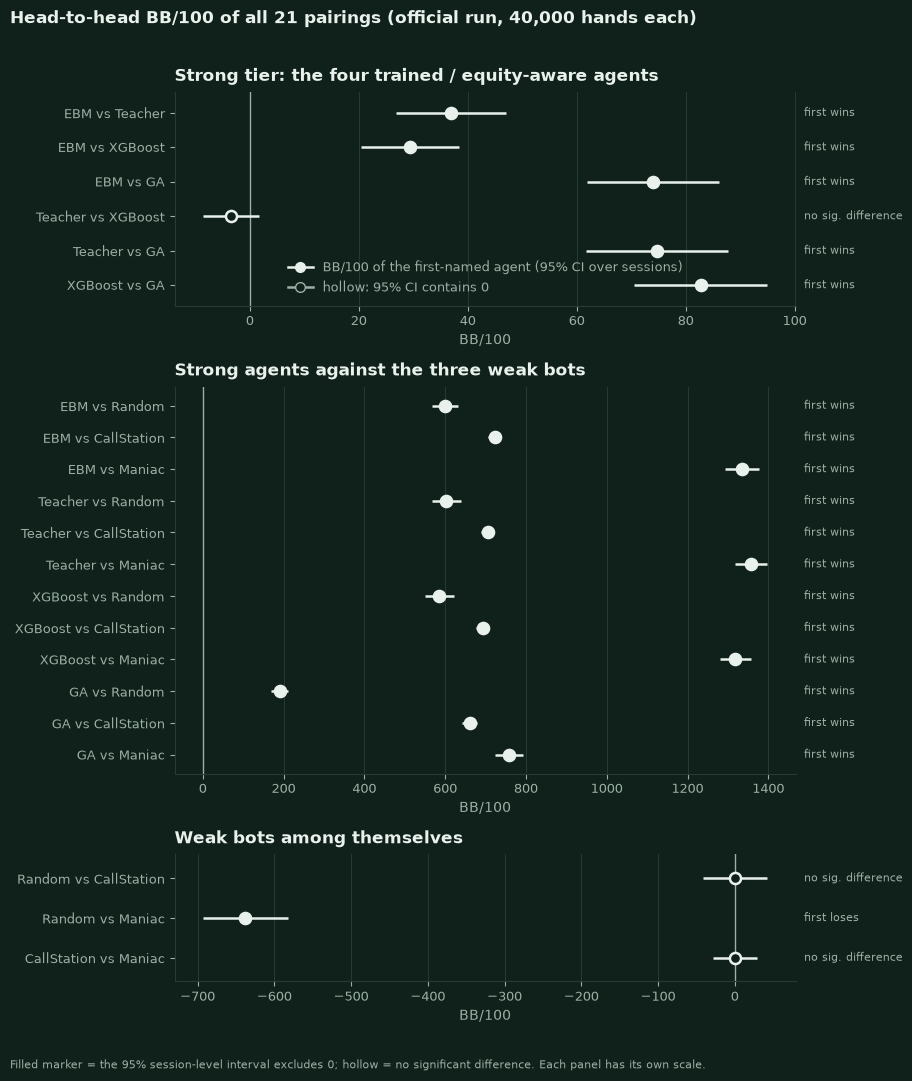

| pairing | BB/100 [95% CI, sessions] | pair-level CI (naive) | session SE / pair SE | verdict |
|---|---|---|---|---|
| `EBM vs Teacher` | +37 [+27, +47] | [+29, +45] | 1.30 | EBM > Teacher (significant) |
| `EBM vs XGBoost` | +29 [+20, +38] | [+22, +37] | 1.15 | EBM > XGBoost (significant) |
| `EBM vs GA` | +74 [+62, +86] | [+62, +86] | 1.03 | EBM > GA (significant) |
| `Teacher vs XGBoost` | -3 [-9, +2] | [-8, +1] | 1.17 | no significant difference |
| `Teacher vs GA` | +75 [+62, +88] | [+63, +86] | 1.11 | Teacher > GA (significant) |
| `XGBoost vs GA` | +83 [+71, +95] | [+71, +95] | 1.00 | XGBoost > GA (significant) |
| `EBM vs Random` | +599 [+567, +631] | [+566, +632] | 0.98 | EBM > Random (significant) |
| `EBM vs CallStation` | +722 [+706, +739] | [+705, +740] | 0.95 | EBM > CallStation (significant) |
| `EBM vs Maniac` | +1335 [+1292, +1377] | [+1294, +1375] | 1.03 | EBM > Maniac (significant) |
| `Teacher vs Random` | +603 [+568, +639] | [+570, +637] | 1.05 | Teacher > Random (significant) |
| `Teacher vs CallStation` | +705 [+688, +722] | [+688, +722] | 1.00 | Teacher > CallStation (significant) |
| `Teacher vs Maniac` | +1358 [+1317, +1398] | [+1317, +1398] | 0.98 | Teacher > Maniac (significant) |
| `XGBoost vs Random` | +585 [+550, +621] | [+551, +620] | 1.03 | XGBoost > Random (significant) |
| `XGBoost vs CallStation` | +693 [+676, +710] | [+676, +710] | 0.99 | XGBoost > CallStation (significant) |
| `XGBoost vs Maniac` | +1318 [+1281, +1356] | [+1277, +1359] | 0.92 | XGBoost > Maniac (significant) |
| `GA vs Random` | +190 [+170, +210] | [+170, +211] | 0.98 | GA > Random (significant) |
| `GA vs CallStation` | +661 [+643, +680] | [+643, +679] | 1.03 | GA > CallStation (significant) |
| `GA vs Maniac` | +757 [+722, +792] | [+722, +793] | 0.98 | GA > Maniac (significant) |
| `Random vs CallStation` | +1 [-41, +43] | [-42, +44] | 0.97 | no significant difference |
| `Random vs Maniac` | -638 [-693, -582] | [-688, -587] | 1.09 | Random < Maniac (significant) |
| `CallStation vs Maniac` | +0 [-29, +29] | [-28, +29] | 1.02 | no significant difference |

**[saved]** Inside the strong tier the session-level verdicts are: `EBM vs Teacher` EBM > Teacher (significant); `EBM vs XGBoost` EBM > XGBoost (significant); `EBM vs GA` EBM > GA (significant); `Teacher vs XGBoost` no significant difference; `Teacher vs GA` Teacher > GA (significant); `XGBoost vs GA` XGBoost > GA (significant). Treating duplicate pairs as independent would flip the verdict of 0 pairing(s): none (section 6.1).

In [9]:
PT = RES.pairwise_table()
STRONG_PAIRS = [(a, b) for i, a in enumerate(STRONG) for b in STRONG[i + 1 :]]
BOT_PAIRS = [(a, b) for a in STRONG for b in WEAK]
WEAK_PAIRS = [(a, b) for i, a in enumerate(WEAK) for b in WEAK[i + 1 :]]


def oriented(a: str, b: str) -> pd.Series:
    """The row of ``pairwise_table`` for the pairing, seen from the better-ranked agent (rank = official leaderboard)."""
    first, second = (a, b) if RANK[a] < RANK[b] else (b, a)
    return PT[(PT["agent"] == first) & (PT["opponent"] == second)].iloc[0]


def group_frame(pairs: list[tuple[str, str]]) -> pd.DataFrame:
    rows = [oriented(a, b) for a, b in pairs]
    frame = pd.DataFrame(rows).reset_index(drop=True)
    frame["label"] = frame["agent"] + " vs " + frame["opponent"]
    frame["rank_a"], frame["rank_b"] = frame["agent"].map(RANK), frame["opponent"].map(RANK)
    return frame.sort_values(["rank_a", "rank_b"]).reset_index(drop=True)


GROUPS = {
    "Strong tier: the four trained / equity-aware agents": group_frame(STRONG_PAIRS),
    "Strong agents against the three weak bots": group_frame(BOT_PAIRS),
    "Weak bots among themselves": group_frame(WEAK_PAIRS),
}
fig, axes = plt.subplots(3, 1, figsize=(10.2, 10.6), gridspec_kw={"height_ratios": [len(g) + 1.4 for g in GROUPS.values()]})
for ax, (title, frame), color in zip(axes, GROUPS.items(), (nbp.TEXT, nbp.TEXT, nbp.TEXT)):
    nbp.forest_plot(
        ax, frame["label"].tolist(), {"BB/100 of the first-named agent (95% CI over sessions)": (frame["bb_per_100"], frame["ci_low"], frame["ci_high"])},
        colors={"BB/100 of the first-named agent (95% CI over sessions)": color}, x_label="BB/100", legend=ax is axes[0],
    )  # fmt: skip
    for y, row in frame.iterrows():  # the verdict in words, right of the interval
        word = {"win": "first wins", "lose": "first loses", "draw": "no sig. difference"}[row["verdict"]]
        ax.annotate(word, (ax.get_xlim()[1], y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=nbp.MUTED, annotation_clip=False)
    nbp.title(ax, title)
fig.suptitle("Head-to-head BB/100 of all 21 pairings (official run, 40,000 hands each)", x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=nbp.TEXT)
nbp.footnote(fig, "Filled marker = the 95% session-level interval excludes 0; hollow = no significant difference. Each panel has its own scale.")
fig.tight_layout(rect=(0, 0.01, 0.9, 0.97))
nbp.savefig("nb04_head_to_head", fig)
plt.show()

table_rows = []
for title, frame in GROUPS.items():
    for _, row in frame.iterrows():
        table_rows.append(
            {
                "pairing": f"`{row['label']}`",
                "BB/100 [95% CI, sessions]": ci_text(row["bb_per_100"], row["ci_low"], row["ci_high"]),
                "pair-level CI (naive)": f"[{row['pair_ci_low']:+.0f}, {row['pair_ci_high']:+.0f}]",
                "session SE / pair SE": f"{row['session_over_pair_se']:.2f}",
                "verdict": row["verdict_text"],
            }
        )
display(md_table(pd.DataFrame(table_rows)))
strong_frame = GROUPS["Strong tier: the four trained / equity-aware agents"].set_index("label")
flip = [r["label"] for _, r in pd.concat(GROUPS.values()).iterrows() if (r["pair_ci_low"] > 0 or r["pair_ci_high"] < 0) != (r["ci_low"] > 0 or r["ci_high"] < 0)]
display(Markdown(
    f"**[saved]** Inside the strong tier the session-level verdicts are: "
    + "; ".join(f"`{label}` {row['verdict_text']}" for label, row in strong_frame.iterrows())
    + f". Treating duplicate pairs as independent would flip the verdict of {len(flip)} pairing(s): {', '.join(f'`{f}`' for f in flip) or 'none'} (section 6.1)."
))

In [10]:
p_values = {pair: float(stats.ttest_1samp(RES.session_profits(*pair), 0.0).pvalue) for pair in RES.pairings()}
bonferroni = 0.05 / len(p_values)
undecided = [f"`{a} vs {b}`" for (a, b), p in p_values.items() if p >= 0.05]
survivors = [pair for pair, p in p_values.items() if p < bonferroni]
weakest = max((pair for pair in survivors), key=lambda pair: p_values[pair])
lead = {k: strong_frame.loc[k] for k in ("EBM vs Teacher", "EBM vs XGBoost")}
MATRIX_ABS = RES.matchup_matrix()
decisive = sorted((pair for pair, p in p_values.items() if p < 0.05), key=lambda pair: abs(MATRIX_ABS.loc[pair[0], pair[1]]))
smallest = [f"`{a} vs {b}` ({abs(MATRIX_ABS.loc[a, b]):.0f})" for a, b in decisive[:3]]
ga_gaps = [abs(strong_frame.loc[f"{x} vs GA", "bb_per_100"]) for x in ("EBM", "Teacher", "XGBoost")]
display(Markdown(f"""
**Reading the head-to-head results `[saved]`.**

* {sum(p < 0.05 for p in p_values.values())} of the {len(p_values)} pairings have a significant winner at the 5% level; the undecided ones are {', '.join(undecided)}. With a Bonferroni correction for 21 comparisons (threshold {bonferroni:.4f}) {len(survivors)} remain significant; the weakest survivor is
  `{weakest[0]} vs {weakest[1]}` (two-sided p = {p_values[weakest]:.1e}), so the multiplicity of the table is not what makes any of the verdicts fragile.
* **The case for the EBM at the top rests on two pairings**: it beats the Teacher by {ci_text(lead['EBM vs Teacher']['bb_per_100'], lead['EBM vs Teacher']['ci_low'], lead['EBM vs Teacher']['ci_high'])} and XGBoost by {ci_text(lead['EBM vs XGBoost']['bb_per_100'], lead['EBM vs XGBoost']['ci_low'], lead['EBM vs XGBoost']['ci_high'])} BB/100. The three smallest
  decisive effects in the table are {', '.join(smallest)} BB/100 - the regime in which a session-level interval of this run is only just narrow enough (section 6.3). Everything else - the three leaders beat the GA by {min(ga_gaps):.0f}-{max(ga_gaps):.0f} BB/100 and the bots by hundreds - is far outside that regime.
* **The Teacher and XGBoost are not separated** (`Teacher vs XGBoost`: {strong_frame.loc['Teacher vs XGBoost', 'verdict_text']}). "No significant difference" is not "equal": section 6.4 asks whether more data would change that.
* **Scale warning.** The three panels of the figure have different axes: the strong-tier results are tens of BB/100, the results against bots hundreds to a thousand and more. A difference that is "huge" in the lower panels would be a landslide in the upper one.
"""))


**Reading the head-to-head results `[saved]`.**

* 18 of the 21 pairings have a significant winner at the 5% level; the undecided ones are `CallStation vs Maniac`, `CallStation vs Random`, `Teacher vs XGBoost`. With a Bonferroni correction for 21 comparisons (threshold 0.0024) 18 remain significant; the weakest survivor is
  `EBM vs XGBoost` (two-sided p = 7.2e-10), so the multiplicity of the table is not what makes any of the verdicts fragile.
* **The case for the EBM at the top rests on two pairings**: it beats the Teacher by +37 [+27, +47] and XGBoost by +29 [+20, +38] BB/100. The three smallest
  decisive effects in the table are `EBM vs XGBoost` (29), `EBM vs Teacher` (37), `EBM vs GA` (74) BB/100 - the regime in which a session-level interval of this run is only just narrow enough (section 6.3). Everything else - the three leaders beat the GA by 74-83 BB/100 and the bots by hundreds - is far outside that regime.
* **The Teacher and XGBoost are not separated** (`Teacher vs XGBoost`: no significant difference). "No significant difference" is not "equal": section 6.4 asks whether more data would change that.
* **Scale warning.** The three panels of the figure have different axes: the strong-tier results are tens of BB/100, the results against bots hundreds to a thousand and more. A difference that is "huge" in the lower panels would be a landslide in the upper one.


## 4. Comparison with baseline policies: the weak tier and the strong tier

Random, CallStation and Maniac ignore hand strength (or, for Random, everything). Against them the trained agents win hundreds of BB/100 - a result that says *how hard a specific
weakness is punished*, not how good the winner is. The cell below separates the two tiers: each strong agent against the weak bots, and the Teacher as the reference policy.

**[saved]** BB/100 [95% CI] of every strong agent against each weak bot (200 sessions each):

| opponent | EBM | XGBoost | GA | Teacher |
|---|---|---|---|---|
| `Random` | +599 [+567, +631] | +585 [+550, +621] | +190 [+170, +210] | +603 [+568, +639] |
| `CallStation` | +722 [+706, +739] | +693 [+676, +710] | +661 [+643, +680] | +705 [+688, +722] |
| `Maniac` | +1335 [+1292, +1377] | +1318 [+1281, +1356] | +757 [+722, +792] | +1358 [+1317, +1398] |

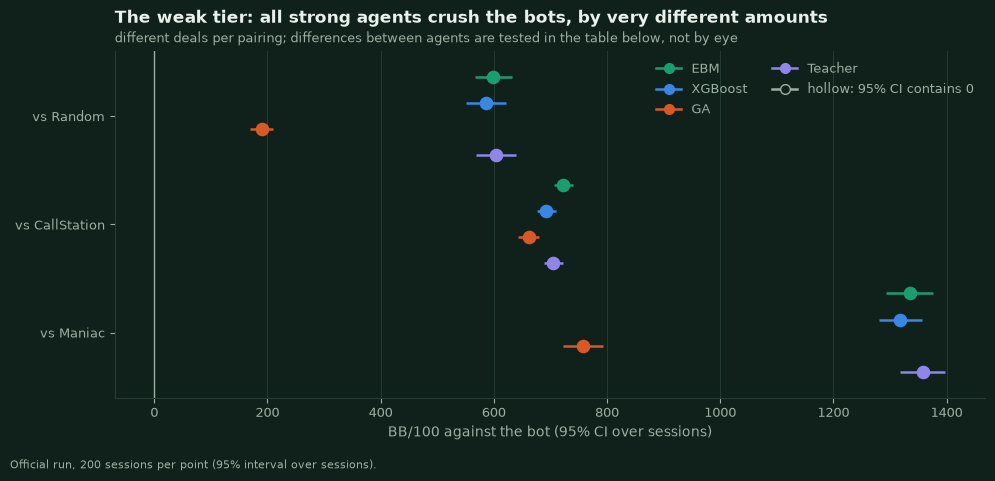

**[saved]** Difference in BB/100 against the same bot, agent minus Teacher (Welch intervals, independent deals; `*` = interval excludes 0):

| agent minus Teacher | vs Random | vs CallStation | vs Maniac | average over the 3 bots |
|---|---|---|---|---|
| `EBM` | -4 [-52, +44] | +17 [-7, +41] | -23 [-81, +35] | -3 [-30, +23] |
| `XGBoost` | -18 [-68, +32] | -12 [-36, +12] | -39 [-94, +16] | -23 [-49, +3] |
| `GA` | -413 [-454, -372] * | -44 [-69, -19] * | -600 [-654, -547] * | -352 [-376, -329] * |

In [11]:
def welch(x: np.ndarray, y: np.ndarray, confidence: float = 0.95) -> tuple[float, float, float, float]:
    """Mean(x) - mean(y) of two independent samples (different deals): estimate, SE, CI low, CI high (Welch t-interval)."""
    vx, vy = x.var(ddof=1) / len(x), y.var(ddof=1) / len(y)
    se = float(np.sqrt(vx + vy))
    df = (vx + vy) ** 2 / (vx**2 / (len(x) - 1) + vy**2 / (len(y) - 1))
    half = float(stats.t.ppf(0.5 + confidence / 2, df)) * se
    diff = float(x.mean() - y.mean())
    return diff, se, diff - half, diff + half


bot_rows, bot_series = [], {a: ([], [], []) for a in STRONG}
for bot in WEAK:
    row = {"opponent": f"`{bot}`"}
    for agent in STRONG:
        r = PT[(PT["agent"] == agent) & (PT["opponent"] == bot)].iloc[0]
        row[agent] = ci_text(r["bb_per_100"], r["ci_low"], r["ci_high"])
        for lst, v in zip(bot_series[agent], (r["bb_per_100"], r["ci_low"], r["ci_high"])):
            lst.append(v)
    bot_rows.append(row)
display(Markdown("**[saved]** BB/100 [95% CI] of every strong agent against each weak bot (200 sessions each):"))
display(md_table(pd.DataFrame(bot_rows)))

fig, ax = plt.subplots(figsize=(10.0, 4.6))
nbp.forest_plot(ax, [f"vs {b}" for b in WEAK], {a: tuple(map(np.array, bot_series[a])) for a in STRONG}, colors=AGENT_COLORS, x_label="BB/100 against the bot (95% CI over sessions)")
nbp.title(ax, "The weak tier: all strong agents crush the bots, by very different amounts", "different deals per pairing; differences between agents are tested in the table below, not by eye")
nbp.footnote(fig, "Official run, 200 sessions per point (95% interval over sessions).")
fig.tight_layout()
nbp.savefig("nb04_vs_baselines", fig)
plt.show()

# differences to the Teacher against the same bot (independent samples: every pairing has its own deals)
diff_rows, BOT_DIFF, BOT_DIFF_EACH = [], {}, {}
for agent in ("EBM", "XGBoost", "GA"):
    row = {"agent minus Teacher": f"`{agent}`"}
    for bot in WEAK:
        d, se, lo, hi = welch(RES.session_profits(agent, bot), RES.session_profits("Teacher", bot))
        BOT_DIFF_EACH[agent, bot] = (d, lo, hi)
        row[f"vs {bot}"] = ci_text(d, lo, hi) + ("" if lo <= 0 <= hi else " *")
    mine = pool_groups([RES.session_profits(agent, b) for b in WEAK], weighting="equal", unit="session")
    theirs = pool_groups([RES.session_profits("Teacher", b) for b in WEAK], weighting="equal", unit="session")
    d, se = mine.mean - theirs.mean, float(np.hypot(mine.se, theirs.se))
    df = se**4 / (mine.se**4 / mine.df + theirs.se**4 / theirs.df)  # Welch-Satterthwaite
    half = float(stats.t.ppf(0.975, df)) * se
    BOT_DIFF[agent] = (d, d - half, d + half)
    row["average over the 3 bots"] = ci_text(d, d - half, d + half) + ("" if abs(d) < half else " *")
    diff_rows.append(row)
display(Markdown("**[saved]** Difference in BB/100 against the same bot, agent minus Teacher (Welch intervals, independent deals; `*` = interval excludes 0):"))
display(md_table(pd.DataFrame(diff_rows)))

### 4.1 Two tiers, two rankings - and the matchups are not additive

If skill were one number (as in Elo), the result of A against C would be the sum of A against B and B against C. The **cyclic sum** `B(a,b) + B(b,c) + B(c,a)` of three agents is then
exactly 0. Its standard error follows from the three session-level standard errors, so we can say which triples are consistent with a single-number skill and which are not:

In [12]:
tier_rows = []
for agent in STRONG:
    weak = pool_groups([RES.session_profits(agent, o) for o in WEAK], weighting="equal", unit="session")
    strong_opponents = [o for o in STRONG if o != agent]
    strong = pool_groups([RES.session_profits(agent, o) for o in strong_opponents], weighting="equal", unit="session")
    tier_rows.append({"agent": agent, "weak": weak, "strong": strong})
for entry in tier_rows:
    entry["rank_weak"] = 1 + sum(o["weak"].mean > entry["weak"].mean for o in tier_rows)
    entry["rank_strong"] = 1 + sum(o["strong"].mean > entry["strong"].mean for o in tier_rows)
display(Markdown("**[saved]** The same four agents ranked by their average BB/100 against the *weak* bots and against the *other strong* agents (equal weight per opponent, session-level t-intervals):"))
display(md_table(pd.DataFrame(
    {
        "agent": [f"`{e['agent']}`" for e in tier_rows],
        "vs the 3 weak bots": [ci_text(e["weak"].mean, e["weak"].ci_low, e["weak"].ci_high) for e in tier_rows],
        "rank (weak tier)": [e["rank_weak"] for e in tier_rows],
        "vs the other 3 strong agents": [ci_text(e["strong"].mean, e["strong"].ci_low, e["strong"].ci_high) for e in tier_rows],
        "rank (strong tier)": [e["rank_strong"] for e in tier_rows],
    }
)))

MATRIX = RES.matchup_matrix()
SE_MATRIX = RES.matchup_matrix(part="se")
triple_rows = []
for i, a in enumerate(AGENTS):
    for j in range(i + 1, len(AGENTS)):
        for k in range(j + 1, len(AGENTS)):
            b, c = AGENTS[j], AGENTS[k]
            cyc = MATRIX.loc[a, b] + MATRIX.loc[b, c] + MATRIX.loc[c, a]
            se = float(np.sqrt(SE_MATRIX.loc[a, b] ** 2 + SE_MATRIX.loc[b, c] ** 2 + SE_MATRIX.loc[c, a] ** 2))
            members = {a, b, c}
            kind = "inside the strong tier" if members <= set(STRONG) else "inside the weak tier" if members <= set(WEAK) else "mixes the tiers"
            triple_rows.append({"triple": (a, b, c), "kind": kind, "cyclic sum": cyc, "se": se, "z": cyc / se})
triples = pd.DataFrame(triple_rows)
summary = (
    triples.groupby("kind")
    .agg(triples=("z", "size"), median_abs_cyclic_sum=("cyclic sum", lambda s: float(np.median(np.abs(s)))), share_abs_z_above_2=("z", lambda s: float(np.mean(np.abs(s) > 2))))
    .reset_index()
)
display(md_table(summary.assign(kind=lambda f: f["kind"], median_abs_cyclic_sum=lambda f: f["median_abs_cyclic_sum"].map("{:.0f}".format), share_abs_z_above_2=lambda f: f["share_abs_z_above_2"].map(pct))
                 .rename(columns={"median_abs_cyclic_sum": "median abs. cyclic sum (BB/100)", "share_abs_z_above_2": "share of triples with abs. z above 2"})))
weak_triple = triples[triples["kind"] == "inside the weak tier"].iloc[0]
display(Markdown(
    f"**[saved]** The three weak bots form the clearest violation: Maniac beats Random ({MATRIX.loc['Maniac', 'Random']:+.0f} BB/100), while Random vs CallStation ({MATRIX.loc['Random', 'CallStation']:+.1f}) and "
    f"CallStation vs Maniac ({MATRIX.loc['CallStation', 'Maniac']:+.1f}) are both indistinguishable from zero - cyclic sum {weak_triple['cyclic sum']:+.0f} ± {weak_triple['se']:.0f} (z = {weak_triple['z']:.1f})."
))

**[saved]** The same four agents ranked by their average BB/100 against the *weak* bots and against the *other strong* agents (equal weight per opponent, session-level t-intervals):

| agent | vs the 3 weak bots | rank (weak tier) | vs the other 3 strong agents | rank (strong tier) |
|---|---|---|---|---|
| `EBM` | +885 [+867, +904] | 2 | +47 [+41, +53] | 1 |
| `XGBoost` | +866 [+848, +884] | 3 | +19 [+14, +24] | 2 |
| `GA` | +536 [+521, +551] | 4 | -77 [-84, -70] | 4 |
| `Teacher` | +889 [+870, +907] | 1 | +11 [+6, +17] | 3 |

| kind | triples | median abs. cyclic sum (BB/100) | share of triples with abs. z above 2 |
|---|---|---|---|
| inside the strong tier | 4 | 21 | 50% |
| inside the weak tier | 1 | 639 | 100% |
| mixes the tiers | 30 | 115 | 70% |

**[saved]** The three weak bots form the clearest violation: Maniac beats Random (+638 BB/100), while Random vs CallStation (+0.8) and CallStation vs Maniac (+0.4) are both indistinguishable from zero - cyclic sum +639 ± 38 (z = 16.7).

In [13]:
weak_rank = {e["agent"]: e["rank_weak"] for e in tier_rows}
strong_rank = {e["agent"]: e["rank_strong"] for e in tier_rows}
by_weak = sorted(STRONG, key=lambda a: weak_rank[a])
by_strong = sorted(STRONG, key=lambda a: strong_rank[a])
ga_share_vs_random = MATRIX.loc["GA", "Random"] / np.mean([MATRIX.loc[a, "Random"] for a in ("EBM", "XGBoost", "Teacher")])
maniac_vs_station = np.mean([MATRIX.loc[a, "Maniac"] / MATRIX.loc[a, "CallStation"] for a in ("EBM", "XGBoost", "Teacher")])
strong_triples = triples[triples["kind"] == "inside the strong tier"]
display(Markdown(f"""
**Reading the two tiers `[saved]`.**

* **Beating the bots is easy, and says little about the rest.** All {len(STRONG) * len(WEAK)} strong-agent-vs-bot pairings are decisive wins of several hundred BB/100. Between the three agents that imitate or equal the Teacher the differences against the *same* bot are small: EBM minus Teacher is
  {ci_text(*BOT_DIFF['EBM'])} BB/100 on average over the bots (interval {'contains' if BOT_DIFF['EBM'][1] <= 0 <= BOT_DIFF['EBM'][2] else 'excludes'} 0), XGBoost minus Teacher {ci_text(*BOT_DIFF['XGBoost'])} ({'contains' if BOT_DIFF['XGBoost'][1] <= 0 <= BOT_DIFF['XGBoost'][2] else 'excludes'} 0; against Random alone
  {ci_text(*BOT_DIFF_EACH['XGBoost', 'Random'])}). The GA earns {ci_text(*BOT_DIFF['GA'])} relative to the Teacher: it wins against every bot, but earns far less than the others (against Random {pct(ga_share_vs_random)} of what the three other strong agents earn).
* **The two tiers rank the agents differently.** Against the weak bots the order is {' > '.join(f'`{a}`' for a in by_weak)}; against the other strong agents it is {' > '.join(f'`{a}`' for a in by_strong)}. The Teacher is #{weak_rank['Teacher']} against the bots and #{strong_rank['Teacher']} among the strong agents. A leaderboard that averages the two (section 5) therefore depends on how many bots are in the pool.
* **The matchups are not additive (4.1).** Of the {len(strong_triples)} triples inside the strong tier, {int((strong_triples['z'].abs() > 2).sum())} violate transitivity beyond sampling error (|z| > 2); the cyclic sums of the {int(summary.loc[summary['kind'] == 'mixes the tiers', 'triples'].iloc[0])} triples that mix tiers have a median
  size of {float(summary.loc[summary['kind'] == 'mixes the tiers', 'median_abs_cyclic_sum'].iloc[0]):.0f} BB/100, and the weak-bot triple is a textbook intransitive cycle (z = {weak_triple['z']:.0f}). The reason is not mysterious: a strategy that ignores hand strength (Maniac, CallStation) is not "a little worse"; it is a different kind of opponent
  whose weakness only some strategies can punish (the strong agents earn {maniac_vs_station:.1f} times more from the Maniac than from the CallStation).
* **Consequence for yardsticks.** A bot is a good *unit test* ("does the agent beat the bots?") and a poor *scale*: against the Maniac the strong agents differ by hundreds of BB/100 for reasons that have nothing to do with their strength against each other, and Elo-style single-number ratings would
  misrepresent the matrix. This notebook therefore reports the strong-tier head-to-head matrix separately and uses the bots only as sanity checks and for style analysis.
"""))


**Reading the two tiers `[saved]`.**

* **Beating the bots is easy, and says little about the rest.** All 12 strong-agent-vs-bot pairings are decisive wins of several hundred BB/100. Between the three agents that imitate or equal the Teacher the differences against the *same* bot are small: EBM minus Teacher is
  -3 [-30, +23] BB/100 on average over the bots (interval contains 0), XGBoost minus Teacher -23 [-49, +3] (contains 0; against Random alone
  -18 [-68, +32]). The GA earns -352 [-376, -329] relative to the Teacher: it wins against every bot, but earns far less than the others (against Random 32% of what the three other strong agents earn).
* **The two tiers rank the agents differently.** Against the weak bots the order is `Teacher` > `EBM` > `XGBoost` > `GA`; against the other strong agents it is `EBM` > `XGBoost` > `Teacher` > `GA`. The Teacher is #1 against the bots and #3 among the strong agents. A leaderboard that averages the two (section 5) therefore depends on how many bots are in the pool.
* **The matchups are not additive (4.1).** Of the 4 triples inside the strong tier, 2 violate transitivity beyond sampling error (|z| > 2); the cyclic sums of the 30 triples that mix tiers have a median
  size of 115 BB/100, and the weak-bot triple is a textbook intransitive cycle (z = 17). The reason is not mysterious: a strategy that ignores hand strength (Maniac, CallStation) is not "a little worse"; it is a different kind of opponent
  whose weakness only some strategies can punish (the strong agents earn 1.9 times more from the Maniac than from the CallStation).
* **Consequence for yardsticks.** A bot is a good *unit test* ("does the agent beat the bots?") and a poor *scale*: against the Maniac the strong agents differ by hundreds of BB/100 for reasons that have nothing to do with their strength against each other, and Elo-style single-number ratings would
  misrepresent the matrix. This notebook therefore reports the strong-tier head-to-head matrix separately and uses the bots only as sanity checks and for style analysis.


## 5. Matchup matrix, leaderboard and rank stability

### 5.1 The full matrix with significance

Left: all 49 cells (symmetric-logarithmic colour scale - the bot results are 10-30 times larger than the strong-tier ones). Right: the strong tier on a linear scale with the
interval printed in every cell. A dot marks a cell whose interval contains 0.

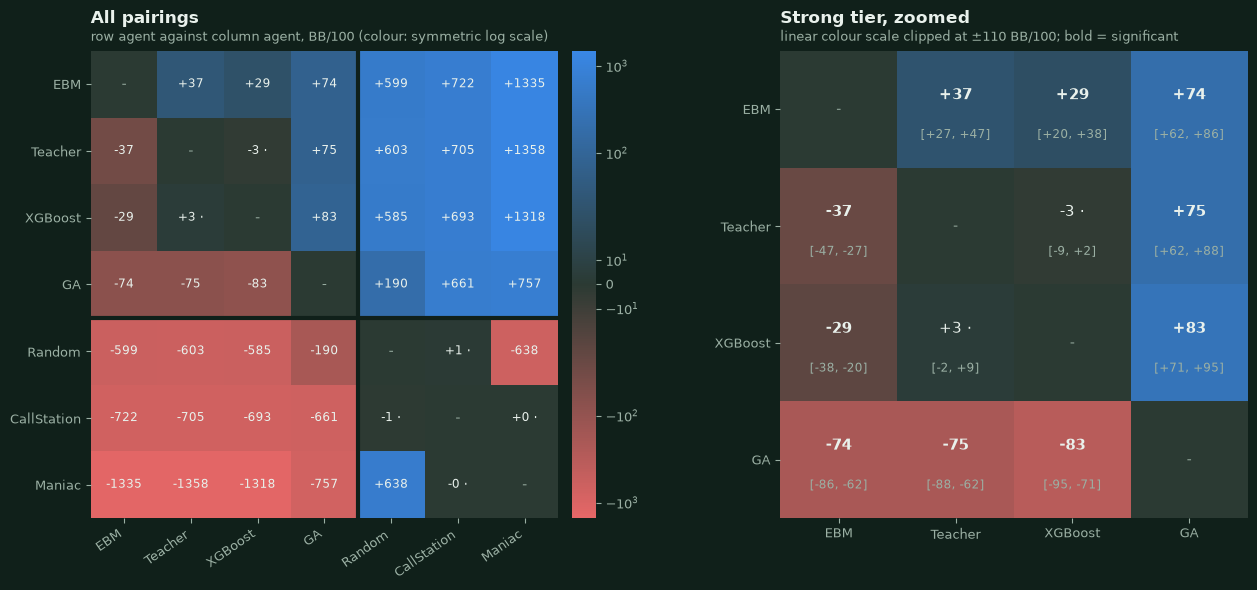

In [14]:
ORDER = RES.leaderboard()["agent"].tolist()
VALUE = RES.matchup_matrix().loc[ORDER, ORDER]
LOW, HIGH = RES.matchup_matrix(part="ci_low").loc[ORDER, ORDER], RES.matchup_matrix(part="ci_high").loc[ORDER, ORDER]
SIGNIFICANT = RES.matchup_matrix(part="significant").loc[ORDER, ORDER].astype(bool)
strong_order = [a for a in ORDER if a in STRONG]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14.6, 6.0), gridspec_kw={"width_ratios": [1.25, 1]})
grid = VALUE.to_numpy(dtype=float)
norm = SymLogNorm(linthresh=40, vmin=-1500, vmax=1500, base=10)
image = ax.imshow(np.nan_to_num(grid), cmap=nbp.DIVERGING, norm=norm)
for i in range(len(ORDER)):
    for j in range(len(ORDER)):
        if i == j:
            ax.text(j, i, "-", ha="center", va="center", color=nbp.MUTED)
        else:
            ax.text(j, i, f"{grid[i, j]:+.0f}" + ("" if SIGNIFICANT.iloc[i, j] else " ·"), ha="center", va="center", fontsize=8.6, color=nbp.TEXT)
ax.set_xticks(range(len(ORDER)), ORDER, rotation=35, ha="right")
ax.set_yticks(range(len(ORDER)), ORDER)
ax.grid(False)
ax.axhline(3.5, color=nbp.SURFACE, linewidth=3)
ax.axvline(3.5, color=nbp.SURFACE, linewidth=3)
for spine in ax.spines.values():
    spine.set_visible(False)
nbp.title(ax, "All pairings", "row agent against column agent, BB/100 (colour: symmetric log scale)")
colorbar = fig.colorbar(image, ax=ax, fraction=0.04, pad=0.02)
colorbar.outline.set_visible(False)

sv = VALUE.loc[strong_order, strong_order].to_numpy(dtype=float)
image2 = ax2.imshow(np.nan_to_num(sv), cmap=nbp.DIVERGING, norm=TwoSlopeNorm(vcenter=0, vmin=-110, vmax=110))
for i, a in enumerate(strong_order):
    for j, b in enumerate(strong_order):
        if i == j:
            ax2.text(j, i, "-", ha="center", va="center", color=nbp.MUTED)
            continue
        significant = SIGNIFICANT.loc[a, b]
        ax2.text(j, i - 0.12, f"{sv[i, j]:+.0f}" + ("" if significant else " ·"), ha="center", va="center", fontsize=11, fontweight="bold" if significant else "normal", color=nbp.TEXT)
        ax2.text(j, i + 0.22, f"[{LOW.loc[a, b]:+.0f}, {HIGH.loc[a, b]:+.0f}]", ha="center", va="center", fontsize=8.3, color=nbp.MUTED)
ax2.set_xticks(range(len(strong_order)), strong_order, rotation=0)
ax2.set_yticks(range(len(strong_order)), strong_order)
ax2.grid(False)
for spine in ax2.spines.values():
    spine.set_visible(False)
nbp.title(ax2, "Strong tier, zoomed", "linear colour scale clipped at ±110 BB/100; bold = significant")
fig.tight_layout()
nbp.savefig("nb04_matchup_matrix", fig)
plt.show()

### 5.2 Leaderboard

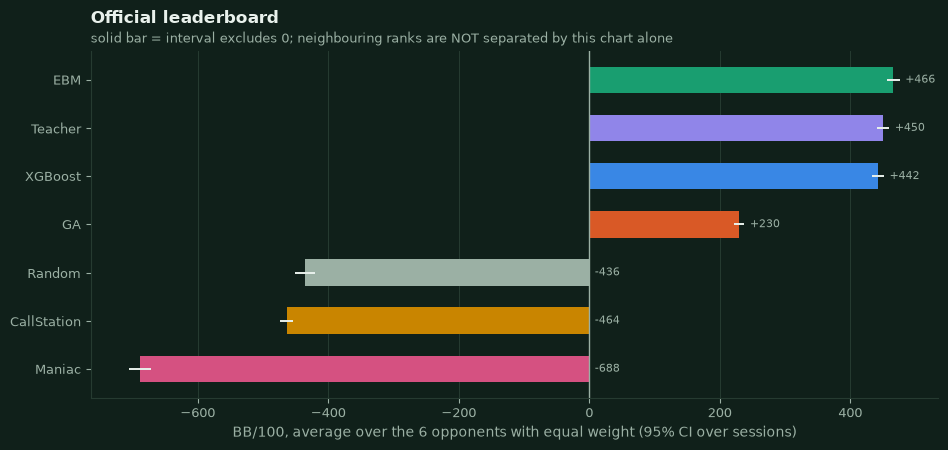

| rank | agent | BB/100 [95% CI, sessions] | pair-level CI (naive) | sample-weighted BB/100 | wins / losses / draws |
|---|---|---|---|---|---|
| 1 | `EBM` | +466.0 [+456.3, +475.8] | [+456.4, +475.6] | +466.0 | 6 / 0 / 0 |
| 2 | `Teacher` | +450.1 [+440.3, +459.9] | [+440.5, +459.6] | +450.1 | 4 / 1 / 1 |
| 3 | `XGBoost` | +442.3 [+432.9, +451.7] | [+432.6, +451.9] | +442.3 | 4 / 1 / 1 |
| 4 | `GA` | +229.5 [+221.3, +237.7] | [+221.3, +237.7] | +229.5 | 3 / 3 / 0 |
| 5 | `Random` | -435.8 [-451.4, -420.3] | [-450.9, -420.7] | -435.8 | 0 / 5 / 1 |
| 6 | `CallStation` | -463.7 [-473.9, -453.4] | [-474.0, -453.3] | -463.7 | 0 / 4 / 2 |
| 7 | `Maniac` | -688.4 [-705.0, -671.8] | [-704.8, -672.1] | -688.4 | 1 / 4 / 1 |

In [15]:
BOARD = RES.leaderboard()
fig, ax = plt.subplots(figsize=(9.6, 4.6))
nbp.bar_with_ci(ax, BOARD["agent"], BOARD["bb_per_100"], BOARD["ci_low"], BOARD["ci_high"], colors=[AGENT_COLORS[a] for a in BOARD["agent"]])
ax.set_xlabel("BB/100, average over the 6 opponents with equal weight (95% CI over sessions)")
nbp.title(ax, "Official leaderboard", "solid bar = interval excludes 0; neighbouring ranks are NOT separated by this chart alone")
fig.tight_layout()
nbp.savefig("nb04_leaderboard", fig)
plt.show()
display(md_table(pd.DataFrame(
    {
        "rank": BOARD["rank"], "agent": [f"`{a}`" for a in BOARD["agent"]],
        "BB/100 [95% CI, sessions]": [ci_text(r.bb_per_100, r.ci_low, r.ci_high, 1) for r in BOARD.itertuples()],
        "pair-level CI (naive)": [f"[{r.pair_ci_low:+.1f}, {r.pair_ci_high:+.1f}]" for r in BOARD.itertuples()],
        "sample-weighted BB/100": BOARD["pooled_bb_per_100"].map("{:+.1f}".format),
        "wins / losses / draws": [f"{r.wins} / {r.losses} / {r.draws}" for r in BOARD.itertuples()],
    }
)))

### 5.3 How stable is the ranking? A bootstrap over sessions `[saved]`

The sessions of a pairing are independent, and so are the pairings (their own deals). One bootstrap replicate therefore resamples the 200 sessions of every pairing with replacement,
recomputes every agent's leaderboard score (equal-weight mean over opponents) and ranks the agents. The share of replicates in which an agent holds each rank is the *rank probability*.
The strong-tier ranking is the same procedure restricted to the four strong agents' mutual pairings (the head-to-head record without the bots).

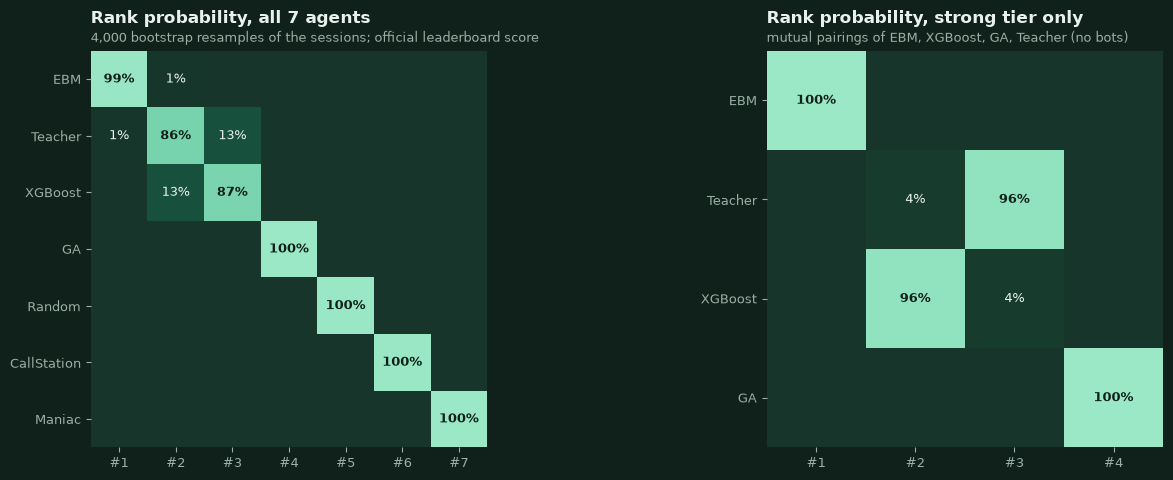

**[saved]** In the full 7-agent leaderboard `EBM` is first in 99% of the resamples; the three leaders hold their official rank in 99% (`EBM`, #1), 86% (`Teacher`, #2), 87% (`XGBoost`, #3) of them. Using only the head-to-head record of the strong tier the order is `EBM` > `XGBoost` > `Teacher` > `GA` with probabilities 100%, 96%, 96%, 100%. The Teacher is ahead of XGBoost in the all-agent ranking (86% for #2) but behind it in the strong-tier ranking (96% for XGBoost at #2): the two metrics answer different questions (4.1).

In [16]:
SESSION_SAMPLES = {}
for a, b in RES.pairings():
    SESSION_SAMPLES[a, b] = RES.session_profits(a, b)
    SESSION_SAMPLES[b, a] = -SESSION_SAMPLES[a, b]
boot_rng = np.random.default_rng(BOOTSTRAP_SEED)
boot_means = {
    key: samples[boot_rng.integers(0, len(samples), size=(BOOTSTRAP_RESAMPLES, len(samples)))].mean(axis=1) for key, samples in SESSION_SAMPLES.items() if key[0] < key[1]
}  # one resample per pairing, shared by both orientations
for (a, b), values in list(boot_means.items()):
    boot_means[b, a] = -values


def rank_probabilities(members: tuple[str, ...]) -> pd.DataFrame:
    scores = np.stack([np.mean([boot_means[x, y] for y in members if y != x], axis=0) for x in members], axis=1)
    ranks = (-scores).argsort(axis=1).argsort(axis=1) + 1
    return pd.DataFrame([[np.mean(ranks[:, i] == r) for r in range(1, len(members) + 1)] for i in range(len(members))], index=list(members), columns=range(1, len(members) + 1))


RANK_P_ALL = rank_probabilities(tuple(ORDER))
RANK_P_STRONG = rank_probabilities(tuple(strong_order))
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.9), gridspec_kw={"width_ratios": [1.35, 1]})
for axis, frame, title, subtitle in (
    (ax, RANK_P_ALL, "Rank probability, all 7 agents", f"{BOOTSTRAP_RESAMPLES:,} bootstrap resamples of the sessions; official leaderboard score"),
    (ax2, RANK_P_STRONG, "Rank probability, strong tier only", "mutual pairings of EBM, XGBoost, GA, Teacher (no bots)"),
):
    image = axis.imshow(frame.to_numpy(), cmap=nbp.SEQUENTIAL, vmin=0, vmax=1)
    for i in range(frame.shape[0]):
        for j in range(frame.shape[1]):
            value = frame.iloc[i, j]
            axis.text(j, i, f"{value:.0%}" if value >= 0.005 else "", ha="center", va="center", fontsize=9.5, fontweight="bold" if value > 0.5 else "normal",
                      color=nbp.SURFACE if value > 0.55 else nbp.TEXT)  # fmt: skip
    axis.set_xticks(range(frame.shape[1]), [f"#{r}" for r in frame.columns])
    axis.set_yticks(range(frame.shape[0]), frame.index)
    axis.grid(False)
    for spine in axis.spines.values():
        spine.set_visible(False)
    nbp.title(axis, title, subtitle)
fig.tight_layout()
nbp.savefig("nb04_rank_stability", fig)
plt.show()
top = RANK_P_ALL[1].idxmax()
display(Markdown(
    f"**[saved]** In the full 7-agent leaderboard `{top}` is first in {pct(RANK_P_ALL.loc[top, 1])} of the resamples; the three leaders hold their official rank in "
    + ", ".join(f"{pct(RANK_P_ALL.loc[a, r])} (`{a}`, #{r})" for a, r in ((ORDER[0], 1), (ORDER[1], 2), (ORDER[2], 3)))
    + f" of them. Using only the head-to-head record of the strong tier the order is "
    + " > ".join(f"`{a}`" for a in RANK_P_STRONG.idxmax(axis=0).tolist())
    + f" with probabilities " + ", ".join(pct(RANK_P_STRONG[r].max()) for r in RANK_P_STRONG.columns)
    + ". "
    + (
        f"The Teacher is ahead of XGBoost in the all-agent ranking ({pct(RANK_P_ALL.loc['Teacher', 2])} for #2) but behind it in the strong-tier ranking ({pct(RANK_P_STRONG.loc['XGBoost', 2])} for XGBoost at #2): the two metrics answer different questions (4.1)."
        if (ORDER.index("Teacher") < ORDER.index("XGBoost")) != (list(RANK_P_STRONG.idxmax(axis=0)).index("Teacher") < list(RANK_P_STRONG.idxmax(axis=0)).index("XGBoost"))
        else "The two metrics put the Teacher and XGBoost in the same relative order."
    )
))

### 5.4 Cumulative profit and the luck band `[saved]`

The curve is the running total of one agent's profit (in big blinds) after every duplicate pair. The shaded band is what a player with **no edge at all** would stay inside with 95%
probability; its width at the end equals the session-level confidence interval of the match total. A curve that leaves the band is evidence of an edge, one that stays inside is compatible with luck.

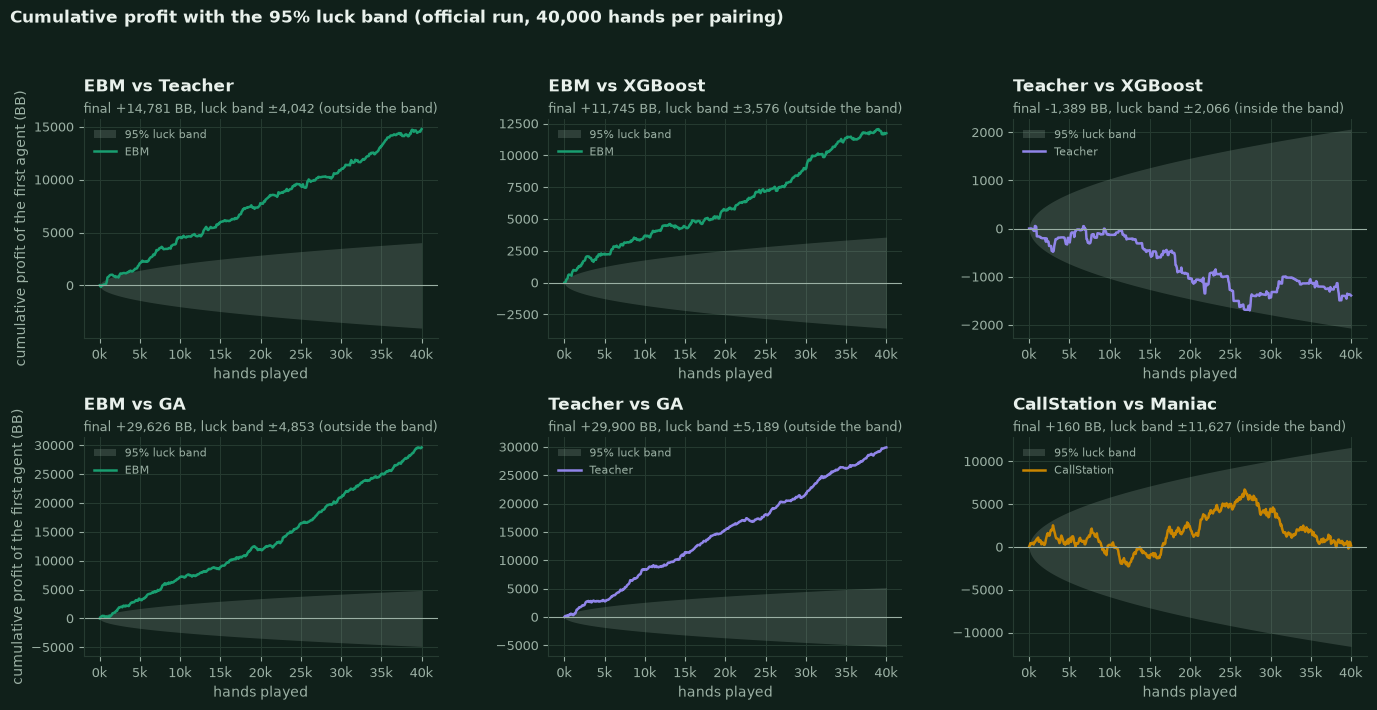

In [17]:
KEY_PAIRS = [("EBM", "Teacher"), ("EBM", "XGBoost"), ("Teacher", "XGBoost"), ("EBM", "GA"), ("Teacher", "GA"), ("CallStation", "Maniac")]
fig, axes = plt.subplots(2, 3, figsize=(14.0, 7.2))
for ax, (a, b) in zip(axes.flat, KEY_PAIRS):
    curve = RES.cumulative_profit(a, b, max_points=500)
    ax.fill_between(curve["hand"], curve["luck_low"], curve["luck_high"], color=nbp.MUTED, alpha=0.22, linewidth=0, label="95% luck band")
    ax.plot(curve["hand"], curve["cum_bb"], color=AGENT_COLORS[a], linewidth=1.8, label=f"{a}")
    ax.axhline(0, color=nbp.MUTED, linewidth=0.8)
    final, band = curve["cum_bb"].iloc[-1], curve["luck_high"].iloc[-1]
    left_band = "outside the band" if abs(final) > band else "inside the band"
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
    ax.set_xlabel("hands played")
    nbp.title(ax, f"{a} vs {b}", f"final {final:+,.0f} BB, luck band ±{band:,.0f} ({left_band})")
    ax.legend(loc="upper left", fontsize=8)
axes[0, 0].set_ylabel("cumulative profit of the first agent (BB)")
axes[1, 0].set_ylabel("cumulative profit of the first agent (BB)")
fig.suptitle("Cumulative profit with the 95% luck band (official run, 40,000 hands per pairing)", x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=nbp.TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.95))
nbp.savefig("nb04_cumulative_profit", fig)
plt.show()

In [18]:
board = BOARD.set_index("agent")
uncertain = [a for a in ORDER if RANK_P_ALL.loc[a].max() < 0.995]
fixed_agents = [a for a in ORDER if a not in uncertain]
most_likely = {a: int(RANK_P_ALL.loc[a].idxmax()) for a in ORDER}
leader_vs_bots = [MATRIX.loc[a, b] for a in BOARD["agent"].tolist()[:3] for b in WEAK]
band = {pair: abs(RES.cumulative_profit(*pair)["cum_bb"].iloc[-1]) > RES.cumulative_profit(*pair)["luck_high"].iloc[-1] for pair in KEY_PAIRS}
leader_names = BOARD["agent"].tolist()[:3]
display(Markdown(f"""
**Reading the leaderboard and the rank bootstrap `[saved]`.**

* The official ranking is {' > '.join(f'`{a}` ({board.loc[a, "bb_per_100"]:+.0f})' for a in BOARD['agent'])}. Its **three leaders are within {board.loc[leader_names[0], 'bb_per_100'] - board.loc[leader_names[2], 'bb_per_100']:.0f} BB/100 of each other** on a scale on which the four-agent spread is {board.loc[leader_names[0], 'bb_per_100'] - board.loc['GA', 'bb_per_100']:.0f},
  because every score is an average of six opponents of which three are bots that all three leaders beat by {min(leader_vs_bots):.0f}-{max(leader_vs_bots):.0f} BB/100. The leaderboard intervals ({', '.join(f"`{a}` [{board.loc[a, 'ci_low']:+.0f}, {board.loc[a, 'ci_high']:+.0f}]" for a in leader_names)}) overlap pairwise, but the *difference* between two leaderboard scores has its own, smaller uncertainty (the two leaders' scores share the pairing `EBM vs Teacher`), so rank questions are answered by the bootstrap below, not by the overlap of two intervals.
* **Rank stability.** `{top}` is first in {pct(RANK_P_ALL.loc[top, 1])} of the resamples; the ranks that are not fixed in every resample are {', '.join(f'`{a}` (most likely #{most_likely[a]}, in {pct(RANK_P_ALL.loc[a].max())})' for a in uncertain) or 'none'}; {', '.join(f'`{a}`' for a in fixed_agents)} keep their place in every resample.
  In the strong-tier ranking (head-to-head record only) the EBM is first in {pct(RANK_P_STRONG.loc['EBM', 1])} of the resamples against {pct(RANK_P_ALL.loc['EBM', 1])} in the bot-diluted leaderboard; the three leader positions are held with probabilities {', '.join(pct(RANK_P_STRONG[r].max()) for r in (1, 2, 3))} (head-to-head) against {', '.join(pct(RANK_P_ALL.loc[ORDER[r - 1], r]) for r in (1, 2, 3))} (leaderboard) - {'the head-to-head record separates the top agents more reliably' if np.mean([RANK_P_STRONG[r].max() for r in (1, 2, 3)]) > np.mean([RANK_P_ALL.loc[ORDER[r - 1], r] for r in (1, 2, 3)]) else 'the bots do not blur the top of the ranking'}.
* **What the luck band says (5.4).** {', '.join(f"`{a} vs {b}`" for (a, b), outside in band.items() if outside)} end outside the 95% band of a zero-edge player; {', '.join(f"`{a} vs {b}`" for (a, b), outside in band.items() if not outside)} end inside it. A curve can leave the
  band temporarily and return - one of the reasons not to stop a match "when it looks significant".
"""))


**Reading the leaderboard and the rank bootstrap `[saved]`.**

* The official ranking is `EBM` (+466) > `Teacher` (+450) > `XGBoost` (+442) > `GA` (+230) > `Random` (-436) > `CallStation` (-464) > `Maniac` (-688). Its **three leaders are within 24 BB/100 of each other** on a scale on which the four-agent spread is 237,
  because every score is an average of six opponents of which three are bots that all three leaders beat by 585-1358 BB/100. The leaderboard intervals (`EBM` [+456, +476], `Teacher` [+440, +460], `XGBoost` [+433, +452]) overlap pairwise, but the *difference* between two leaderboard scores has its own, smaller uncertainty (the two leaders' scores share the pairing `EBM vs Teacher`), so rank questions are answered by the bootstrap below, not by the overlap of two intervals.
* **Rank stability.** `EBM` is first in 99% of the resamples; the ranks that are not fixed in every resample are `EBM` (most likely #1, in 99%), `Teacher` (most likely #2, in 86%), `XGBoost` (most likely #3, in 87%); `GA`, `Random`, `CallStation`, `Maniac` keep their place in every resample.
  In the strong-tier ranking (head-to-head record only) the EBM is first in 100% of the resamples against 99% in the bot-diluted leaderboard; the three leader positions are held with probabilities 100%, 96%, 96% (head-to-head) against 99%, 86%, 87% (leaderboard) - the head-to-head record separates the top agents more reliably.
* **What the luck band says (5.4).** `EBM vs Teacher`, `EBM vs XGBoost`, `EBM vs GA`, `Teacher vs GA` end outside the 95% band of a zero-edge player; `Teacher vs XGBoost`, `CallStation vs Maniac` end inside it. A curve can leave the
  band temporarily and return - one of the reasons not to stop a match "when it looks significant".


## 6. Statistical uncertainty

This section answers five questions about the *numbers* before we interpret them: (1) how much wider is the honest session-level interval than the naive pair-level one under the corrected protocol, and why;
(2) does the corrected protocol do what it should when there is no difference at all (**A/A tests**: two identical deterministic Teachers must cancel exactly; two identical *stochastic* adaptive agents calibrate the interval procedure) - and what exactly was wrong with the legacy protocol;
(3) how much data would it take to resolve a +10 BB/100 edge; (4) does the ordering of the three most important pairings **replicate** on new seeds; (5) what did the protocol change cost or buy, on the same deals?

### 6.0 Tooling for the fresh experiments `[demo]`

Two ways of playing sessions are used below, both built from the package's own code. **Registry agents** (`AgentSpec`) go through `build_tasks` / `execute_tasks`, exactly as `run_match` and `run_tournament` do (`run_matches` below puts many matches
on one process pool). **Modified agents** (an agent that is blind to opponent statistics, a logging wrapper, ...) are not in the registry; `run_experiments` feeds agent *objects* into the package's own `play_session` through an `AgentCache` subclass and
runs the sessions on a process pool (`joblib`/`loky`, which can ship notebook-defined classes to the workers). In both cases the protocol (`two_table`, or `single_table` where a legacy diagnostic says so), the deals and the agent streams come from the package:
deals from `derive_seed("eval", ...)` keyed by the two labels, agent streams by label, session **and table**.

In [19]:
OPPONENT_CHANNELS = ("vpip", "pfr", "aggression", "fold_to_bet", "showdown_rate")  # the smoothed opponent statistics an Observation carries
NEUTRAL_STATS = OpponentStats()  # the prior every tracker starts from
BB = GAME.big_blind


class ObjectCache(AgentCache):
    """An ``AgentCache`` that builds agents from zero-argument factories (keyed by label), so wrapped agents can play through ``play_session``."""

    def __init__(self, factories: dict) -> None:
        super().__init__()
        self.factories = factories
        self.created: list = []

    def fresh(self, spec: AgentSpec) -> Agent:
        agent = self.factories[spec.label]()
        agent.name = spec.label
        self.created.append(agent)
        return agent


def _logged_rows(agent):
    """Rows logged by an agent and by every agent it wraps (``inner``): wrappers can be stacked."""
    while agent is not None:
        yield from getattr(agent, "rows", [])
        agent = getattr(agent, "inner", None)


def _custom_session(task, factories):
    cache = ObjectCache(factories)
    result = play_session(task, cache)
    # the cache creates the two agents of table 0 first, then those of table 1 (two_table); the single legacy table has one pair: table = creation index // 2
    rows = [(task.session_index, index // 2, *row) for index, agent in enumerate(cache.created) for row in _logged_rows(agent)]
    return result, rows


@dataclasses.dataclass
class CustomRun:
    """Outcome of one experiment: the hero's BB/100 per session, whether the hero was the first-named agent (agent A), the raw session results and the decision logs."""

    sessions: np.ndarray
    hero_is_a: bool
    results: list
    rows: list
    seconds: float = 0.0

    @property
    def estimate(self):
        return t_estimate(self.sessions, unit="session")

    @property
    def sign(self) -> float:
        return 1.0 if self.hero_is_a else -1.0


def run_experiments(experiments: dict[str, dict]) -> dict[str, CustomRun]:
    """Run several experiments on ONE process pool. Each entry: ``factories`` (label -> agent factory), ``hero``, ``opponent``, ``seed``, ``sessions``, optional
    ``order`` ("first" (default): the hero is agent A = seat 0, "second": the hero is agent B - the official tournament makes the label that sorts first agent A),
    ``session_hands`` (default 200) and ``protocol`` (default: the corrected ``two_table``). The result of an experiment never depends on the others or on the worker count."""
    jobs, layout = [], {}
    for name, e in experiments.items():
        cfg = MatchConfig(game=GAME, num_hands=e["sessions"] * e.get("session_hands", 200), seed=e["seed"], duplicate=True, session_hands=e.get("session_hands", 200),
                          keep_hands=SILENT, protocol=e.get("protocol", TWO_TABLE))  # fmt: skip
        spec_hero, spec_opp = (AgentSpec("custom", {}, label=label) for label in (e["hero"], e["opponent"]))
        hero_is_a = e.get("order", "first") == "first"
        tasks = build_tasks(0, spec_hero, spec_opp, cfg) if hero_is_a else build_tasks(0, spec_opp, spec_hero, cfg)
        layout[name] = (len(jobs), len(tasks), hero_is_a, cfg)
        jobs += [(task, e["factories"]) for task in tasks]
    started = time.perf_counter()
    out = Parallel(n_jobs=N_WORKERS, backend="loky")(delayed(_custom_session)(task, factories) for task, factories in jobs)
    elapsed = time.perf_counter() - started
    runs = {}
    for name, (start, count, hero_is_a, cfg) in layout.items():
        results = [r for r, _ in out[start : start + count]]
        sign = 1.0 if hero_is_a else -1.0
        bb100 = sign * np.array([r.arrays.profit_chips.sum() for r in results], dtype=float) / BB / cfg.session_hands * 100.0
        runs[name] = CustomRun(bb100, hero_is_a, results, [row for _, rows in out[start : start + count] for row in rows], elapsed * count / len(jobs))
    return runs


def run_matches(matches: dict[str, tuple[AgentSpec, AgentSpec, MatchConfig]]) -> dict[str, list]:
    """Several matches described by registry specs, played on ONE process pool with the package's own ``build_tasks`` / ``execute_tasks``.
    Returns ``{name: [SessionResult of session 0, 1, ...]}``; agent A is the first spec."""
    tasks, names = [], {}
    for index, (name, (spec_a, spec_b, cfg)) in enumerate(matches.items()):
        names[index] = name
        tasks += build_tasks(index, spec_a, spec_b, cfg)
    collected: dict[str, dict[int, object]] = {name: {} for name in matches}
    for result in execute_tasks(tasks, N_WORKERS):
        collected[names[result.match_index]][result.session_index] = result
    return {name: [by_session[s] for s in sorted(by_session)] for name, by_session in collected.items()}


def sessions_bb100(results: list) -> np.ndarray:
    """Agent A's BB/100 in every session of a match (``SessionResult`` list)."""
    return np.array([r.arrays.profit_chips.sum() / BB / r.num_hands * 100.0 for r in results])


def pairs_bb(results: list) -> np.ndarray:
    """Agent A's BB per duplicate pair (hands 2p and 2p + 1 of the layout are the two plays of deal p), all sessions in order."""
    return np.concatenate([(r.arrays.profit_chips[0::2] + r.arrays.profit_chips[1::2]) / BB for r in results])


def match_config(hands: int, seed: int, protocol: str = TWO_TABLE) -> MatchConfig:
    return MatchConfig(game=GAME, num_hands=hands, seed=seed, duplicate=True, session_hands=OFFICIAL_CFG.session_hands, keep_hands=SILENT, protocol=protocol)


class SeesLess(Agent):
    """Wraps an agent and shrinks the opponent statistics it is shown towards the neutral prior: ``alpha = 1`` changes nothing, ``alpha = 0`` hides them
    completely (an agent that does not adapt). ``channels`` restricts the effect to some statistics. Only the *Observation* is changed - never the game."""

    architecture = "wrapped"

    def __init__(self, inner: Agent, alpha: float = 0.0, channels: tuple[str, ...] = OPPONENT_CHANNELS) -> None:
        self.inner, self.alpha, self.channels = inner, alpha, channels

    def reset(self, seed: int | None = None) -> None:
        self.inner.reset(seed)

    def act(self, obs):
        stats_seen = obs.opponent_stats
        shrunk = {c: getattr(NEUTRAL_STATS, c) + self.alpha * (getattr(stats_seen, c) - getattr(NEUTRAL_STATS, c)) for c in self.channels}
        return self.inner.act(dataclasses.replace(obs, opponent_stats=dataclasses.replace(stats_seen, **shrunk)))

    def end_hand(self, summary) -> None:
        self.inner.end_hand(summary)


make_teacher = lambda: create_agent("teacher")  # noqa: E731
make_ebm = lambda: create_agent("ebm")  # noqa: E731
make_xgb = lambda: create_agent("xgboost")  # noqa: E731
display(Markdown("Tooling defined: `run_matches` (registry agents), `run_experiments` (agent objects through `play_session`), `SeesLess` (opponent-statistic shrinking wrapper)."))

Tooling defined: `run_matches` (registry agents), `run_experiments` (agent objects through `play_session`), `SeesLess` (opponent-statistic shrinking wrapper).

### 6.1 Pair-level vs session-level intervals under the corrected protocol `[saved]`

Duplicate dealing makes the two plays of a deal strongly negatively correlated, so the sum of a **pair** has a small variance. If pairs were independent, 20,000 of them would give a very
narrow interval. But the Teacher, EBM and XGBoost read statistics of the opponent's earlier hands, so the pairs of one session can influence each other (each table is a game with memory). The **intraclass correlation**
(how much of the variance of a pair result is shared by the pairs of the same session) measures that dependence directly, and the variance ratio `(session SE / pair SE)^2` is the
*design effect* by which the naive interval understates the variance. Section 6.5 measures the same quantities under the legacy protocol on the same deals.

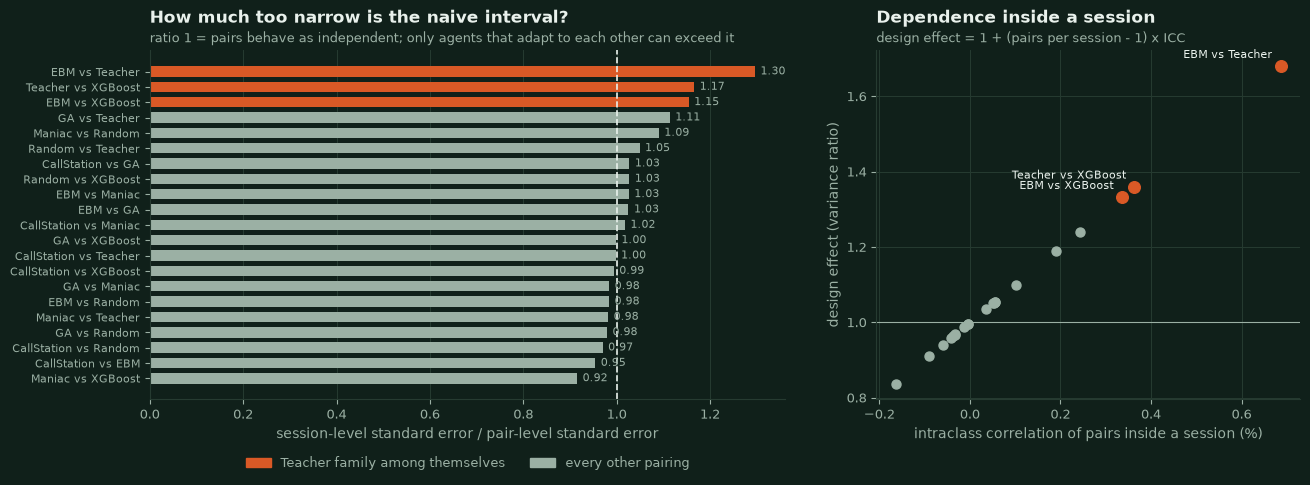

**[saved]** For the 3 pairings inside the Teacher family the session-level standard error is 1.15-1.30 times the pair-level one (design effect 1.3-1.7; ICC 0.34-0.69% with 100 pairs per session). For the other 18 pairings the ratio is 0.92-1.11 (median 1.00) and the ICC -0.16 to +0.24% - as expected for opponents that do not adapt (the bots) or adapt hardly at all (the GA has two adaptation genes). The naive pair-level interval would not change any verdict.

**[saved]** What duplicate dealing buys: the standard error of the sum of a duplicate pair is 0.22-0.97 times (median 0.72) that of the same number of independent hands (the stored `se_ratio`), i.e. the card luck it removes is worth 1.1-21.5 times as many hands.

In [20]:
def icc_of(pair_bb: np.ndarray) -> float:
    """One-way ANOVA intraclass correlation of pair results (rows: sessions, columns: pairs of a session)."""
    k = pair_bb.shape[1]
    ms_between = k * ((pair_bb.mean(axis=1) - pair_bb.mean()) ** 2).sum() / (len(pair_bb) - 1)
    ms_within = ((pair_bb - pair_bb.mean(axis=1, keepdims=True)) ** 2).sum() / (len(pair_bb) * (k - 1))
    return float((ms_between - ms_within) / (ms_between + (k - 1) * ms_within))


rows = []
for a, b in RES.pairings():
    r = PT[(PT["agent"] == a) & (PT["opponent"] == b)].iloc[0]
    rows.append(
        {"a": a, "b": b, "label": f"{a} vs {b}", "icc": icc_of(RES.pair_profits(a, b).reshape(OFFICIAL_CFG.num_sessions, -1)), "ratio": r["session_over_pair_se"], "se": r["se"], "pair_se": r["pair_se"], "bb": r["bb_per_100"],
         "pair_significant": bool(r["pair_significant"]), "significant": bool(r["significant"]), "kind": "Teacher family (EBM, XGBoost, Teacher) among themselves" if {a, b} <= {"EBM", "XGBoost", "Teacher"} else "every other pairing"}
    )  # fmt: skip
DEPENDENCE = pd.DataFrame(rows).sort_values("ratio", ascending=False).reset_index(drop=True)
FAMILY = DEPENDENCE[DEPENDENCE["kind"].str.startswith("Teacher")]
OTHERS = DEPENDENCE[~DEPENDENCE["kind"].str.startswith("Teacher")]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.2, 5.0), gridspec_kw={"width_ratios": [1.5, 1]})
colors = [nbp.SERIES[2] if k.startswith("Teacher") else nbp.MUTED for k in DEPENDENCE["kind"]]
ax.barh(range(len(DEPENDENCE)), DEPENDENCE["ratio"], color=colors, height=0.68)
ax.axvline(1.0, color=nbp.TEXT, linewidth=1.2, linestyle="--")
ax.set_yticks(range(len(DEPENDENCE)), DEPENDENCE["label"], fontsize=8)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("session-level standard error / pair-level standard error")
for y, v in enumerate(DEPENDENCE["ratio"]):
    ax.annotate(f"{v:.2f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=nbp.MUTED)
nbp.title(ax, "How much too narrow is the naive interval?", "ratio 1 = pairs behave as independent; only agents that adapt to each other can exceed it")
ax.legend(handles=[Patch(color=nbp.SERIES[2], label="Teacher family among themselves"), Patch(color=nbp.MUTED, label="every other pairing")], loc="upper center", bbox_to_anchor=(0.5, -0.13), ncols=2)
ax2.scatter(OTHERS["icc"] * 100, OTHERS["ratio"] ** 2, color=nbp.MUTED, s=42, label="every other pairing")
ax2.scatter(FAMILY["icc"] * 100, FAMILY["ratio"] ** 2, color=nbp.SERIES[2], s=70, label="Teacher family among themselves", zorder=3)
for _, r in FAMILY.iterrows():
    ax2.annotate(r["label"], (r["icc"] * 100, r["ratio"] ** 2), xytext=(-6, 6), textcoords="offset points", ha="right", fontsize=8, color=nbp.TEXT)
ax2.axhline(1, color=nbp.MUTED, linewidth=0.8)
ax2.set_xlabel("intraclass correlation of pairs inside a session (%)")
ax2.set_ylabel("design effect (variance ratio)")
nbp.title(ax2, "Dependence inside a session", "design effect = 1 + (pairs per session - 1) x ICC")
fig.tight_layout()
nbp.savefig("nb04_pair_vs_session", fig)
plt.show()
verdict_flips = DEPENDENCE[DEPENDENCE["pair_significant"] != DEPENDENCE["significant"]]
display(Markdown(
    f"**[saved]** For the {len(FAMILY)} pairings inside the Teacher family the session-level standard error is {FAMILY['ratio'].min():.2f}-{FAMILY['ratio'].max():.2f} times the pair-level one "
    f"(design effect {FAMILY['ratio'].min() ** 2:.1f}-{FAMILY['ratio'].max() ** 2:.1f}; ICC {100 * FAMILY['icc'].min():.2f}-{100 * FAMILY['icc'].max():.2f}% with {OFFICIAL_CFG.session_hands // 2} pairs per session). "
    f"For the other {len(OTHERS)} pairings the ratio is {OTHERS['ratio'].min():.2f}-{OTHERS['ratio'].max():.2f} (median {OTHERS['ratio'].median():.2f}) and the ICC {100 * OTHERS['icc'].min():+.2f} to {100 * OTHERS['icc'].max():+.2f}% - "
    f"as expected for opponents that do not adapt (the bots) or adapt hardly at all (the GA has two adaptation genes). "
    + (f"The naive interval would change the verdict of {', '.join(f'`{r.label}` (session-level: {r.bb:+.1f} BB/100, SE {r.se:.1f}; pair-level SE {r.pair_se:.1f})' for r in verdict_flips.itertuples())}."
       if len(verdict_flips) else "The naive pair-level interval would not change any verdict.")
))
display(Markdown(
    f"**[saved]** What duplicate dealing buys: the standard error of the sum of a duplicate pair is {PT['se_ratio'].min():.2f}-{PT['se_ratio'].max():.2f} times (median {PT['se_ratio'].median():.2f}) that of the same number of independent hands (the stored `se_ratio`), "
    f"i.e. the card luck it removes is worth {1 / PT['se_ratio'].max() ** 2:.1f}-{1 / PT['se_ratio'].min() ** 2:.1f} times as many hands."
))

### 6.2 A/A tests: what must cancel, what was wrong, and is the interval calibrated? `[fresh]`

The honest test of a protocol and of an interval procedure is a situation where the truth is known: two **identical** agents play each other, the true difference is 0. Three experiments:

1. **Corrected protocol, two identical deterministic Teachers.** Neither agent has randomness; with two independent tables the two plays of every deal are exact mirror images, so *every single pair* must sum to exactly 0 - not just in expectation.
2. **Legacy single-table protocol, the same two Teachers** (the documented bug). Both plays of a deal are consecutive hands of one game, so the second play is played against an opponent model that already contains the first play of the same deal; the second mover learns how the opponent played the cards it now holds.
   The first-named agent is first mover in every pair. This is what this notebook's A/A test found in the original analysis.
3. **Corrected protocol, two identical *stochastic* adaptive agents** (a Teacher that plays a random legal action `CALIBRATION_NOISE` of the time; and the GA, which draws bluff coins). Their pairs do not cancel exactly, so this is the non-degenerate calibration of the interval procedure:
   over many independent matches a 95% interval must exclude 0 in about 5% of them.

In [21]:
TEACHER_A, TEACHER_B = AgentSpec("teacher", label="Teacher-A"), AgentSpec("teacher", label="Teacher-B")
started = time.perf_counter()
AA_EXACT_LEGACY = run_matches(
    {f"exact-{m}": (TEACHER_A, TEACHER_B, match_config(10 * OFFICIAL_CFG.session_hands, AA_SEED + m, TWO_TABLE)) for m in range(EXACT_AA_MATCHES)}
    | {f"legacy-{m}": (TEACHER_A, TEACHER_B, match_config(LEGACY_AA_MATCH_HANDS, AA_SEED + 1000 + m, SINGLE_TABLE)) for m in range(LEGACY_AA_MATCHES)}
)
aa_seconds = time.perf_counter() - started


def pooled_first_named(prefix: str, count: int) -> dict:
    sessions = np.concatenate([sessions_bb100(AA_EXACT_LEGACY[f"{prefix}-{m}"]) for m in range(count)])
    pairs = np.concatenate([pairs_bb(AA_EXACT_LEGACY[f"{prefix}-{m}"]) for m in range(count)])
    return {"sessions": sessions, "pairs": pairs, "mean": float(sessions.mean()), "se": float(sessions.std(ddof=1) / np.sqrt(len(sessions)))}


AA_EXACT, AA_LEGACY = pooled_first_named("exact", EXACT_AA_MATCHES), pooled_first_named("legacy", LEGACY_AA_MATCHES)
# the legacy asymmetry by seat of the second-named copy (agent B)
b_button, b_bb = [], []
for m in range(LEGACY_AA_MATCHES):
    for r in AA_EXACT_LEGACY[f"legacy-{m}"]:
        a_profit = r.arrays.profit_chips / BB
        b_button.append(-a_profit[~r.arrays.a_on_button])
        b_bb.append(-a_profit[r.arrays.a_on_button])
b_button, b_bb = np.concatenate(b_button), np.concatenate(b_bb)
display(md_table(pd.DataFrame(
    [
        {"protocol": "`two_table` (corrected)", "matches x sessions": f"{EXACT_AA_MATCHES} x 10", "pairs": f"{len(AA_EXACT['pairs']):,}", "largest |pair sum| (BB)": f"{np.max(np.abs(AA_EXACT['pairs'])):.2f}",
         "Teacher-A (first-named), BB/100": f"{AA_EXACT['mean']:+.2f} ± {AA_EXACT['se']:.2f}", "z": "-" if AA_EXACT["se"] == 0 else f"{AA_EXACT['mean'] / AA_EXACT['se']:+.1f}"},
        {"protocol": "`single_table` (legacy)", "matches x sessions": f"{LEGACY_AA_MATCHES} x {LEGACY_AA_MATCH_HANDS // OFFICIAL_CFG.session_hands}", "pairs": f"{len(AA_LEGACY['pairs']):,}", "largest |pair sum| (BB)": f"{np.max(np.abs(AA_LEGACY['pairs'])):.1f}",
         "Teacher-A (first-named), BB/100": f"{AA_LEGACY['mean']:+.1f} ± {AA_LEGACY['se']:.1f}", "z": f"{AA_LEGACY['mean'] / AA_LEGACY['se']:+.1f}"},
    ]
)))
display(Markdown(
    f"**[fresh]** ({aa_seconds:.0f} s.) **Corrected protocol:** {len(AA_EXACT['pairs']):,} pairs of two identical Teachers, the largest absolute pair sum is {np.max(np.abs(AA_EXACT['pairs'])):.2f} BB - the mirror cancellation is exact. "
    f"**Legacy protocol:** the first-named Teacher loses {-AA_LEGACY['mean']:.1f} ± {AA_LEGACY['se']:.1f} BB/100 to an identical copy of itself over {len(AA_LEGACY['sessions'])} independent sessions (z = {AA_LEGACY['mean'] / AA_LEGACY['se']:.1f}); "
    f"seen from the second-named copy: {100 * b_button.mean():+.0f} BB per 100 hands in which it has the button and {100 * b_bb.mean():+.0f} per 100 hands in the big blind (the two halves are averaged in the headline). "
    f"For scale: the official EBM vs Teacher estimate is {RES.session_profits('EBM', 'Teacher').mean():+.0f} BB/100 and the official Teacher vs XGBoost estimate {RES.session_profits('Teacher', 'XGBoost').mean():+.1f}, so an artifact of {-AA_LEGACY['mean']:.0f} BB/100 is {-AA_LEGACY['mean'] / abs(RES.session_profits('Teacher', 'XGBoost').mean()):.0f} times the latter. "
    f"The true difference between two identical agents is exactly 0, so any systematic departure is a property of the protocol (here {'p < 0.001' if 2 * stats.norm.sf(abs(AA_LEGACY['mean'] / AA_LEGACY['se'])) < 0.001 else f"p = {2 * stats.norm.sf(abs(AA_LEGACY['mean'] / AA_LEGACY['se'])):.3f}"} for one test over {len(AA_LEGACY['sessions'])} sessions; the documentation of the repository (`docs/METHODOLOGY.md`, section 5) quotes two earlier measurements of the same quantity, -13.0 ± 3.7 over 800 sessions and -9.5 ± 3.8 on other seeds)."
))

| protocol | matches x sessions | pairs | largest |pair sum| (BB) | Teacher-A (first-named), BB/100 | z |
|---|---|---|---|---|---|
| `two_table` (corrected) | 10 x 10 | 10,000 | 0.00 | +0.00 ± 0.00 | - |
| `single_table` (legacy) | 60 x 20 | 120,000 | 154.0 | -13.2 ± 3.0 | -4.3 |

**[fresh]** (127 s.) **Corrected protocol:** 10,000 pairs of two identical Teachers, the largest absolute pair sum is 0.00 BB - the mirror cancellation is exact. **Legacy protocol:** the first-named Teacher loses 13.2 ± 3.0 BB/100 to an identical copy of itself over 1200 independent sessions (z = -4.3); seen from the second-named copy: +46 BB per 100 hands in which it has the button and -20 per 100 hands in the big blind (the two halves are averaged in the headline). For scale: the official EBM vs Teacher estimate is +37 BB/100 and the official Teacher vs XGBoost estimate -3.5, so an artifact of 13 BB/100 is 4 times the latter. The true difference between two identical agents is exactly 0, so any systematic departure is a property of the protocol (here p < 0.001 for one test over 1200 sessions; the documentation of the repository (`docs/METHODOLOGY.md`, section 5) quotes two earlier measurements of the same quantity, -13.0 ± 3.7 over 800 sessions and -9.5 ± 3.8 on other seeds).

In [22]:
noisy = lambda: MixedPolicyAgent(create_agent("teacher"), create_agent("random"), CALIBRATION_NOISE, "noisy")  # noqa: E731 - stochastic and adaptive (it reads opponent statistics)
started = time.perf_counter()
calibration_runs = run_experiments(
    {f"noisy-{m}": dict(factories={"Noisy-A": noisy, "Noisy-B": noisy}, hero="Noisy-A", opponent="Noisy-B", seed=AA_SEED + 2000 + m, sessions=CALIBRATION_MATCH_HANDS // OFFICIAL_CFG.session_hands) for m in range(CALIBRATION_MATCHES)}
)
GA_A, GA_B = AgentSpec("ga", label="GA-A"), AgentSpec("ga", label="GA-B")
calibration_ga = run_matches({f"ga-{m}": (GA_A, GA_B, match_config(CALIBRATION_MATCH_HANDS, AA_SEED + 3000 + m)) for m in range(CALIBRATION_MATCHES)})
calibration_seconds = time.perf_counter() - started


def binom_text(k: int, n: int) -> str:
    low, high = stats.binomtest(k, n).proportion_ci(confidence_level=0.95, method="exact")
    return f"{k} of {n} (exact 95% range {pct(low)}-{pct(high)})"


def nominal(k: int, n: int) -> str:
    """Is a false-positive count compatible with the nominal 5%? (exact binomial test, two-sided)"""
    return "compatible with the nominal 5%" if stats.binomtest(k, n, 0.05).pvalue > 0.05 else "NOT compatible with the nominal 5%"


def calibrate(per_match: dict[str, list]) -> dict:
    """Interval procedure on identical agents: one session-level and one pair-level interval per match, then the share that excludes the true value 0."""
    est_session = [t_estimate(sessions_bb100(results), unit="session") for results in per_match.values()]
    est_pair = [t_estimate(pairs_bb(results) * 50.0, unit="pair") for results in per_match.values()]  # BB per pair -> BB/100
    pooled = np.concatenate([sessions_bb100(results) for results in per_match.values()])
    return {
        "matches": len(per_match), "sessions": len(pooled), "mean": float(pooled.mean()), "se": float(pooled.std(ddof=1) / np.sqrt(len(pooled))), "t_test": stats.ttest_1samp(pooled, 0.0),
        "session_fp": sum(e.excludes_zero for e in est_session), "pair_fp": sum(e.excludes_zero for e in est_pair),
        "mean_session_se": float(np.mean([e.se for e in est_session])), "mean_pair_se": float(np.mean([e.se for e in est_pair])), "sd_of_estimates": float(np.std([e.mean for e in est_session], ddof=1)),
    }  # fmt: skip


CALIBRATION = {
    f"two noisy Teachers ({pct(CALIBRATION_NOISE)} random actions)": calibrate({name: run.results for name, run in calibration_runs.items()}),
    "two GAs (identical genome, different streams)": calibrate(calibration_ga),
}
display(md_table(pd.DataFrame(
    [
        {"identical agents (corrected protocol)": name, "matches x sessions": f"{c['matches']} x {CALIBRATION_MATCH_HANDS // OFFICIAL_CFG.session_hands}", "first-named agent, BB/100 (true value 0)": f"{c['mean']:+.1f} ± {c['se']:.1f}",
         "t-test against 0": f"p = {c['t_test'].pvalue:.2f}", "session-level CI excludes 0": binom_text(c["session_fp"], c["matches"]), "pair-level CI excludes 0": binom_text(c["pair_fp"], c["matches"]),
         "mean SE session / pair": f"{c['mean_session_se']:.1f} / {c['mean_pair_se']:.1f}", "actual SD of the match estimates": f"{c['sd_of_estimates']:.1f}"}
        for name, c in CALIBRATION.items()
    ]
)))
noisy_c = next(iter(CALIBRATION.values()))
display(Markdown(
    f"**[fresh]** ({calibration_seconds:.0f} s.) Over {noisy_c['matches']} independent matches of {CALIBRATION_MATCH_HANDS // OFFICIAL_CFG.session_hands} sessions each, "
    + "; ".join(
        f"for {name} the session-level 95% interval excludes the true value 0 in {binom_text(c['session_fp'], c['matches'])} - {nominal(c['session_fp'], c['matches'])} - and the pair-level one in {binom_text(c['pair_fp'], c['matches'])} - {nominal(c['pair_fp'], c['matches'])}; "
        f"the first-named agent's pooled result is {c['mean']:+.1f} ± {c['se']:.1f} BB/100 (p = {c['t_test'].pvalue:.2f})"
        for name, c in CALIBRATION.items()
    )
    + f". The average standard error that the session-level interval reports ({', '.join(f'{c['mean_session_se']:.0f}' for c in CALIBRATION.values())} BB/100) can be compared with the actual spread of the match estimates ({', '.join(f'{c['sd_of_estimates']:.0f}' for c in CALIBRATION.values())})."
))

| identical agents (corrected protocol) | matches x sessions | first-named agent, BB/100 (true value 0) | t-test against 0 | session-level CI excludes 0 | pair-level CI excludes 0 | mean SE session / pair | actual SD of the match estimates |
|---|---|---|---|---|---|---|---|
| two noisy Teachers (10% random actions) | 40 x 10 | +2.9 ± 6.8 | p = 0.67 | 1 of 40 (exact 95% range 0%-13%) | 1 of 40 (exact 95% range 0%-13%) | 42.4 / 41.0 | 38.8 |
| two GAs (identical genome, different streams) | 40 x 10 | -1.8 ± 3.6 | p = 0.62 | 1 of 40 (exact 95% range 0%-13%) | 0 of 40 (exact 95% range 0%-9%) | 22.6 / 22.4 | 20.1 |

**[fresh]** (55 s.) Over 40 independent matches of 10 sessions each, for two noisy Teachers (10% random actions) the session-level 95% interval excludes the true value 0 in 1 of 40 (exact 95% range 0%-13%) - compatible with the nominal 5% - and the pair-level one in 1 of 40 (exact 95% range 0%-13%) - compatible with the nominal 5%; the first-named agent's pooled result is +2.9 ± 6.8 BB/100 (p = 0.67); for two GAs (identical genome, different streams) the session-level 95% interval excludes the true value 0 in 1 of 40 (exact 95% range 0%-13%) - compatible with the nominal 5% - and the pair-level one in 0 of 40 (exact 95% range 0%-9%) - compatible with the nominal 5%; the first-named agent's pooled result is -1.8 ± 3.6 BB/100 (p = 0.62). The average standard error that the session-level interval reports (42, 23 BB/100) can be compared with the actual spread of the match estimates (39, 20).

**Reading the A/A tests.** (i) The corrected protocol does what a duplicate protocol must do: two identical *deterministic* agents cancel in **every** pair, the second play of a deal can no longer profit from the first. (ii) The legacy protocol did not: identical agents
did not cancel and the first-named one lost (size and significance in the paragraph above) - *Mechanism (speculation, consistent with the exact cancellation under two tables but not tested directly):* the second mover of a pair plays against an opponent model that already contains the first play of the same deal.
(iii) With stochastic adaptive agents the pairs do not cancel exactly, so the corrected protocol is tested on what the interval procedure has to do in practice: the share of matches whose 95% interval excludes the true value 0, the pooled first-named result and the comparison of the reported standard error with the real spread of the match estimates are all in the paragraph above. Section 6.5 contrasts the two protocols on the official deals.
**Consequence for this notebook:** it analyses the corrected run; wherever it needs a control it uses the corrected protocol; the legacy protocol only appears as a labelled diagnostic.

### 6.3 How much data does a +10 BB/100 edge need? `[saved]`

With `n` independent sessions of standard deviation `sigma` (BB/100 per 200-hand session), the standard error is `sigma / sqrt(n)`. A two-sided 5% test has power `POWER_LEVEL` against a true edge
`delta` when `delta = (z(1 - alpha/2) + z(power)) * sigma / sqrt(n)`, i.e. `n = ((z_alpha + z_power) * sigma / delta)^2`. The standard deviations are the **observed** ones of the official run.
The naive calculation that treats duplicate pairs as independent uses the (smaller) pair-level standard deviation and is shown for comparison.

| pairing | SD of a 200-hand session (BB/100) | sessions for 10 BB/100 at 80% power | hands needed | ... if pairs were independent (naive) | official hands | power of the official run | smallest edge detected with 80% power |
|---|---|---|---|---|---|---|---|
| `EBM vs Teacher` | 72 | 412 | 82,457 | 49,089 | 40,000 | 50% | 14 |
| `EBM vs XGBoost` | 64 | 323 | 64,543 | 48,453 | 40,000 | 60% | 13 |
| `Teacher vs XGBoost` | 37 | 108 | 21,547 | 15,849 | 40,000 | 97% | 7 |

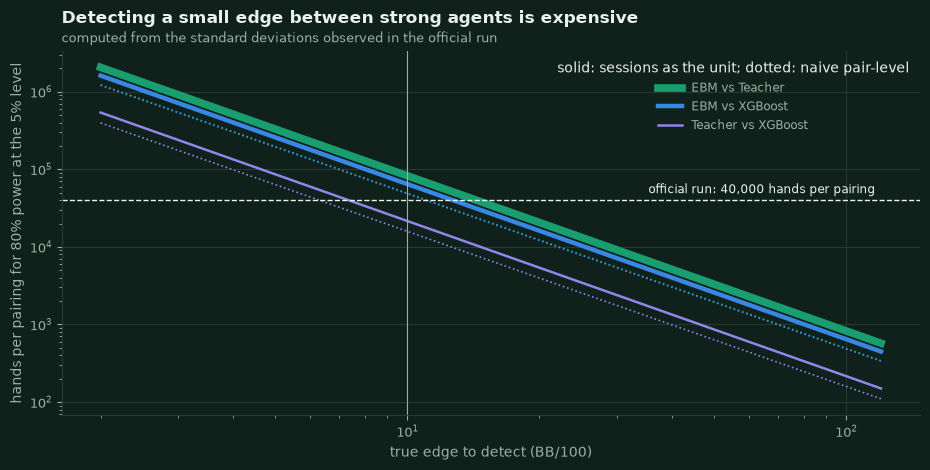

**[saved]** Halving the edge to be detected quadruples the data. For `EBM vs Teacher` a 10 BB/100 edge needs about 82,457 hands at the session level - 2.1x the official run - while the naive pair-level calculation would suggest 49,089. **The official run can only reliably resolve differences of roughly 7-14 BB/100 or more between strong agents**; a true +10 would be detected in only 50-97% of repetitions. These requirements use the standard deviations of the *corrected* run; they are lower than those the legacy protocol would have implied because a session now fluctuates much less (SD of a session 37-72 BB/100 here; section 6.5 measures the legacy values on the same deals and discusses why).

In [23]:
Z_ALPHA, Z_POWER = float(stats.norm.ppf(0.975)), float(stats.norm.ppf(POWER_LEVEL))
KEY_MATCHUPS = [("EBM", "Teacher"), ("EBM", "XGBoost"), ("Teacher", "XGBoost")]  # orientation as stored (first label sorts first)
power_rows, power_data = [], {}
for a, b in KEY_MATCHUPS:
    session = RES.session_profits(a, b)
    pair = RES.ci_samples(a, b, "pair")  # BB/100-scaled duplicate-pair results
    sd_session, sd_pair = float(session.std(ddof=1)), float(pair.std(ddof=1))
    se_official = sd_session / np.sqrt(len(session))
    needed_sessions = ((Z_ALPHA + Z_POWER) * sd_session / POWER_TARGET_EDGE) ** 2
    needed_pairs = ((Z_ALPHA + Z_POWER) * sd_pair / POWER_TARGET_EDGE) ** 2
    power_data[a, b] = (sd_session, sd_pair)
    power_rows.append(
        {
            "pairing": f"`{a} vs {b}`",
            "SD of a 200-hand session (BB/100)": f"{sd_session:.0f}",
            f"sessions for {POWER_TARGET_EDGE:.0f} BB/100 at {pct(POWER_LEVEL)} power": f"{needed_sessions:,.0f}",
            "hands needed": f"{needed_sessions * OFFICIAL_CFG.session_hands:,.0f}",
            "... if pairs were independent (naive)": f"{needed_pairs * 2:,.0f}",
            "official hands": f"{OFFICIAL_CFG.num_hands:,}",
            "power of the official run": pct(float(stats.norm.cdf(POWER_TARGET_EDGE / se_official - Z_ALPHA))),
            f"smallest edge detected with {pct(POWER_LEVEL)} power": f"{(Z_ALPHA + Z_POWER) * se_official:.0f}",
        }
    )
display(md_table(pd.DataFrame(power_rows)))

edges = np.geomspace(2, 120, 80)
fig, ax = plt.subplots(figsize=(9.4, 4.8))
for (a, b), color, width in zip(KEY_MATCHUPS, (nbp.SERIES[0], nbp.SERIES[1], nbp.SERIES[3]), (5.5, 3.2, 1.8)):  # EBM-Teacher and EBM-XGBoost are almost on top of each other
    sd_session, sd_pair = power_data[a, b]
    ax.plot(edges, ((Z_ALPHA + Z_POWER) * sd_session / edges) ** 2 * OFFICIAL_CFG.session_hands, color=color, linewidth=width, label=f"{a} vs {b}")
    ax.plot(edges, ((Z_ALPHA + Z_POWER) * sd_pair / edges) ** 2 * 2, color=color, linewidth=1.2, linestyle=":")
ax.axhline(OFFICIAL_CFG.num_hands, color=nbp.TEXT, linewidth=1.0, linestyle="--")
ax.annotate(f"official run: {OFFICIAL_CFG.num_hands:,} hands per pairing", (edges[-1], OFFICIAL_CFG.num_hands), xytext=(-4, 5), textcoords="offset points", ha="right", fontsize=8.5, color=nbp.TEXT)
ax.axvline(POWER_TARGET_EDGE, color=nbp.MUTED, linewidth=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("true edge to detect (BB/100)")
ax.set_ylabel(f"hands per pairing for {pct(POWER_LEVEL)} power at the 5% level")
ax.legend(loc="upper right", title="solid: sessions as the unit; dotted: naive pair-level", fontsize=8.5)
nbp.title(ax, "Detecting a small edge between strong agents is expensive", "computed from the standard deviations observed in the official run")
fig.tight_layout()
nbp.savefig("nb04_power", fig)
plt.show()
a0, b0 = KEY_MATCHUPS[0]
display(Markdown(
    f"**[saved]** Halving the edge to be detected quadruples the data. For `{a0} vs {b0}` a {POWER_TARGET_EDGE:.0f} BB/100 edge needs about "
    f"{((Z_ALPHA + Z_POWER) * power_data[a0, b0][0] / POWER_TARGET_EDGE) ** 2 * OFFICIAL_CFG.session_hands:,.0f} hands at the session level - "
    f"{((Z_ALPHA + Z_POWER) * power_data[a0, b0][0] / POWER_TARGET_EDGE) ** 2 * OFFICIAL_CFG.session_hands / OFFICIAL_CFG.num_hands:.1f}x the official run - while the naive pair-level calculation would "
    f"suggest {((Z_ALPHA + Z_POWER) * power_data[a0, b0][1] / POWER_TARGET_EDGE) ** 2 * 2:,.0f}. **The official run can only reliably resolve differences of roughly "
    f"{min(float(r[f'smallest edge detected with {pct(POWER_LEVEL)} power']) for r in power_rows):.0f}-{max(float(r[f'smallest edge detected with {pct(POWER_LEVEL)} power']) for r in power_rows):.0f} BB/100 or more between strong agents**; "
    f"a true +10 would be detected in only {min(float(r['power of the official run'].rstrip('%')) for r in power_rows):.0f}-{max(float(r['power of the official run'].rstrip('%')) for r in power_rows):.0f}% of repetitions. "
    f"These requirements use the standard deviations of the *corrected* run; they are lower than those the legacy protocol would have implied because a session now fluctuates much less (SD of a session {min(v[0] for v in power_data.values()):.0f}-{max(v[0] for v in power_data.values()):.0f} BB/100 here; section 6.5 measures the legacy values on the same deals and discusses why)."
))

### 6.4 Replication on new seeds `[fresh]`

The three pairings that decide the story - **EBM vs Teacher, EBM vs XGBoost, XGBoost vs Teacher** - are re-run from scratch with `REPLICATION_SEEDS` (new master seeds in the `eval` namespace, so new deals and
new agent streams; section 2.4 verified that none of those deals appeared before) and `REPLICATION_HANDS` hands each, with exactly the official protocol (the corrected two-table protocol, same session length, session-level
intervals). The question is not whether the numbers are identical but whether **the ordering replicates**: same sign, same verdict, and agreement with the official estimate within sampling error.

| pairing | official (seed 42) | replication, seed 101 | replication, seed 202 | all runs pooled |
|---|---|---|---|---|
| `EBM vs Teacher` | +37.0 [+26.8, +47.1] - wins | +10.4 [-1.9, +22.8] - no significant difference (z vs official -3.3) | +26.3 [+13.6, +39.0] - wins (z vs official -1.3) | +27.7 [+20.9, +34.4] (400 sessions) - wins |
| `EBM vs XGBoost` | +29.4 [+20.4, +38.3] - wins | +12.5 [-0.4, +25.5] - no significant difference (z vs official -2.1) | +20.6 [+6.6, +34.6] - wins (z vs official -1.0) | +23.0 [+16.5, +29.5] (400 sessions) - wins |
| `Teacher vs XGBoost` | -3.5 [-8.6, +1.7] - no significant difference | -1.7 [-7.3, +4.0] - no significant difference (z vs official +0.5) | -0.0 [-6.8, +6.8] - no significant difference (z vs official +0.8) | -2.2 [-5.5, +1.2] (400 sessions) - no significant difference |

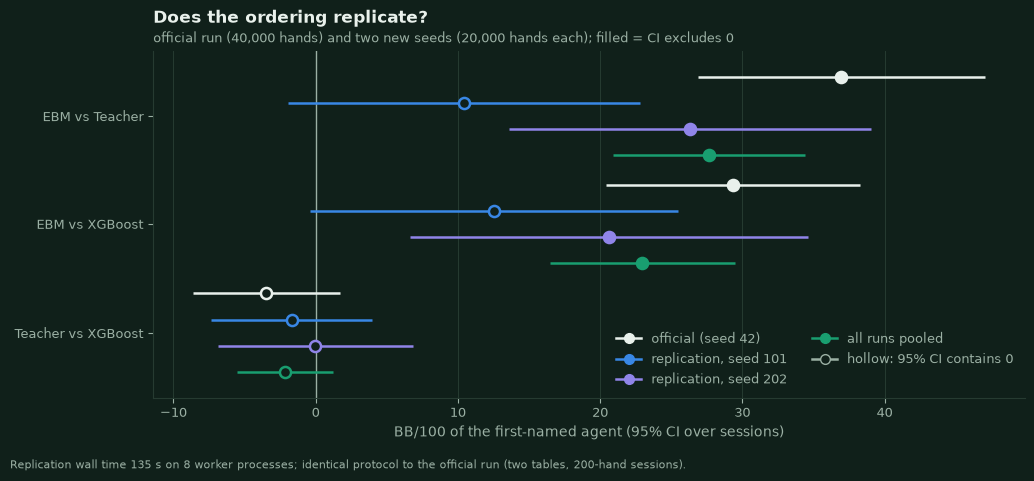

In [24]:
REPL_SPECS = {"EBM": AgentSpec("ebm", label="EBM"), "XGBoost": AgentSpec("xgboost", label="XGBoost"), "Teacher": AgentSpec("teacher", label="Teacher")}
repl_cfgs = {
    seed: MatchConfig(game=GAME, num_hands=REPLICATION_HANDS, seed=seed, duplicate=True, session_hands=OFFICIAL_CFG.session_hands, keep_hands=SILENT, n_workers=N_WORKERS, protocol=OFFICIAL_CFG.protocol)
    for seed in REPLICATION_SEEDS
}
assert all(seed != OFFICIAL_CFG.seed for seed in REPLICATION_SEEDS)
tasks, match_index = [], {}
for seed in REPLICATION_SEEDS:
    for a, b in KEY_MATCHUPS:
        index = len(match_index)
        match_index[index] = (seed, a, b)
        tasks += build_tasks(index, REPL_SPECS[a], REPL_SPECS[b], repl_cfgs[seed])
started = time.perf_counter()
chips: dict[int, dict[int, np.ndarray]] = {index: {} for index in match_index}
for session_result in execute_tasks(tasks, N_WORKERS):
    chips[session_result.match_index][session_result.session_index] = session_result.arrays.profit_chips
repl_seconds = time.perf_counter() - started

REPLICATION = {}  # (seed, a, b) -> UnitSamples of the first-named agent
for index, (seed, a, b) in match_index.items():
    REPLICATION[seed, a, b] = unit_samples(np.concatenate([chips[index][s] for s in sorted(chips[index])]), repl_cfgs[seed])
rows, forest = [], {name: ([], [], []) for name in ("official (seed 42)", *[f"replication, seed {s}" for s in REPLICATION_SEEDS], "all runs pooled")}
for a, b in KEY_MATCHUPS:
    official = t_estimate(RES.session_profits(a, b), unit="session")
    runs = {f"replication, seed {s}": t_estimate(REPLICATION[s, a, b].session, unit="session") for s in REPLICATION_SEEDS}
    pooled = t_estimate(np.concatenate([RES.session_profits(a, b), *(REPLICATION[s, a, b].session for s in REPLICATION_SEEDS)]), unit="session")
    row = {"pairing": f"`{a} vs {b}`", "official (seed 42)": ci_text(official.mean, official.ci_low, official.ci_high, 1) + f" - {verdict_word(official.ci_low, official.ci_high)}"}
    for name, e in runs.items():
        z = (e.mean - official.mean) / np.hypot(e.se, official.se)
        row[name] = ci_text(e.mean, e.ci_low, e.ci_high, 1) + f" - {verdict_word(e.ci_low, e.ci_high)} (z vs official {z:+.1f})"
    row["all runs pooled"] = ci_text(pooled.mean, pooled.ci_low, pooled.ci_high, 1) + f" ({pooled.n} sessions) - {verdict_word(pooled.ci_low, pooled.ci_high)}"
    rows.append(row)
    for name, e in {"official (seed 42)": official, **runs, "all runs pooled": pooled}.items():
        for lst, v in zip(forest[name], (e.mean, e.ci_low, e.ci_high)):
            lst.append(v)
display(md_table(pd.DataFrame(rows)))
fig, ax = plt.subplots(figsize=(10.4, 4.6))
nbp.forest_plot(
    ax, [f"{a} vs {b}" for a, b in KEY_MATCHUPS], {k: tuple(map(np.array, v)) for k, v in forest.items()},
    colors={"official (seed 42)": nbp.TEXT, f"replication, seed {REPLICATION_SEEDS[0]}": nbp.SERIES[1], f"replication, seed {REPLICATION_SEEDS[1]}": nbp.SERIES[3], "all runs pooled": nbp.SERIES[0]},
    x_label="BB/100 of the first-named agent (95% CI over sessions)",
)  # fmt: skip
nbp.title(ax, "Does the ordering replicate?", f"official run ({OFFICIAL_CFG.num_hands:,} hands) and two new seeds ({REPLICATION_HANDS:,} hands each); filled = CI excludes 0")
nbp.footnote(fig, f"Replication wall time {repl_seconds:.0f} s on {N_WORKERS} worker processes; identical protocol to the official run (two tables, 200-hand sessions).")
fig.tight_layout()
nbp.savefig("nb04_replication", fig)
plt.show()

In [25]:
REPL_ESTIMATES = {(a, b): [t_estimate(REPLICATION[seed, a, b].session, unit="session") for seed in REPLICATION_SEEDS] for a, b in KEY_MATCHUPS}
POOLED = {(a, b): t_estimate(np.concatenate([RES.session_profits(a, b), *(REPLICATION[seed, a, b].session for seed in REPLICATION_SEEDS)]), unit="session") for a, b in KEY_MATCHUPS}
OFFICIAL_E = {(a, b): t_estimate(RES.session_profits(a, b), unit="session") for a, b in KEY_MATCHUPS}
def cochran_q(estimates) -> float:
    """p-value of the hypothesis that the runs estimate the same value (inverse-variance weights, session-level standard errors)."""
    weights = np.array([1.0 / e.se**2 for e in estimates])
    means = np.array([e.mean for e in estimates])
    q = float((weights * (means - (weights * means).sum() / weights.sum()) ** 2).sum())
    return float(stats.chi2.sf(q, len(estimates) - 1))


HETEROGENEITY = {k: cochran_q([OFFICIAL_E[k], *REPL_ESTIMATES[k]]) for k in KEY_MATCHUPS}
same_sign = {k: [np.sign(e.mean) == np.sign(OFFICIAL_E[k].mean) for e in runs] for k, runs in REPL_ESTIMATES.items()}
same_verdict = {k: [verdict_word(e.ci_low, e.ci_high) == verdict_word(OFFICIAL_E[k].ci_low, OFFICIAL_E[k].ci_high) for e in runs] for k, runs in REPL_ESTIMATES.items()}
zs = [(e.mean - OFFICIAL_E[k].mean) / np.hypot(e.se, OFFICIAL_E[k].se) for k, runs in REPL_ESTIMATES.items() for e in runs]
pooled_sd = POOLED["Teacher", "XGBoost"]
display(Markdown(f"""
**Summary of the statistical checks `[saved]` `[fresh]`.**

* **The sign and the order replicate; the size is less certain than a single interval suggests.** {sum(sum(v) for v in same_sign.values())} of {sum(len(v) for v in same_sign.values())} replicate estimates have the sign of the official one, and the official verdict is reproduced in {sum(sum(v) for v in same_verdict.values())} of {sum(len(v) for v in same_verdict.values())} replicate runs (`EBM vs Teacher`: {sum(same_verdict['EBM', 'Teacher'])} of {len(REPLICATION_SEEDS)}, `EBM vs XGBoost`: {sum(same_verdict['EBM', 'XGBoost'])} of {len(REPLICATION_SEEDS)},
  `Teacher vs XGBoost`: {sum(same_verdict['Teacher', 'XGBoost'])} of {len(REPLICATION_SEEDS)}); the replicate estimates are within |z| = {max(abs(z) for z in zs):.1f} of the official one. A test of equality of the three runs of a pairing (Cochran's Q, session-level standard errors) gives p = {HETEROGENEITY['EBM', 'Teacher']:.3f} (`EBM vs Teacher`), {HETEROGENEITY['EBM', 'XGBoost']:.3f} (`EBM vs XGBoost`), {HETEROGENEITY['Teacher', 'XGBoost']:.3f} (`Teacher vs XGBoost`){' - for EBM vs Teacher the runs differ more than their intervals allow, which is either bad luck (three tests were made) or a variance component this analysis does not model; the sessions of a run use disjoint deals and deterministic agents, so there is no obvious source' if HETEROGENEITY['EBM', 'Teacher'] < 0.05 else ' - the three runs are compatible with one common value'}. Pooled over {POOLED['EBM', 'Teacher'].n} independent sessions ({POOLED['EBM', 'Teacher'].n * OFFICIAL_CFG.session_hands:,} hands per pairing):
  EBM > Teacher {ci_text(POOLED['EBM', 'Teacher'].mean, POOLED['EBM', 'Teacher'].ci_low, POOLED['EBM', 'Teacher'].ci_high, 1)}, EBM > XGBoost {ci_text(POOLED['EBM', 'XGBoost'].mean, POOLED['EBM', 'XGBoost'].ci_low, POOLED['EBM', 'XGBoost'].ci_high, 1)}, and Teacher vs XGBoost
  {ci_text(pooled_sd.mean, pooled_sd.ci_low, pooled_sd.ci_high, 1)} - still {verdict_word(pooled_sd.ci_low, pooled_sd.ci_high)}. The EBM edge over the Teacher is {'smaller in both replicates than in the official run' if all(e.mean < OFFICIAL_E['EBM', 'Teacher'].mean for e in REPL_ESTIMATES['EBM', 'Teacher']) else 'not systematically smaller in the replicates'} ({', '.join(f'{e.mean:+.0f}' for e in REPL_ESTIMATES['EBM', 'Teacher'])} vs {OFFICIAL_E['EBM', 'Teacher'].mean:+.0f}): **the best point estimate of the EBM's edge over the Teacher is the pooled one**, not the official run's alone.
* **Honest limits.** A +{POWER_TARGET_EDGE:.0f} BB/100 edge would need {((Z_ALPHA + Z_POWER) * power_data['EBM', 'Teacher'][0] / POWER_TARGET_EDGE) ** 2 * OFFICIAL_CFG.session_hands:,.0f} hands between strong agents (6.3); the official run and both replications together contribute {POOLED['EBM', 'Teacher'].n * OFFICIAL_CFG.session_hands:,} hands per pairing. The XGBoost-Teacher difference is
  therefore {'*resolved*' if pooled_sd.ci_low > 0 or pooled_sd.ci_high < 0 else '*unresolved*, not zero'}: the pooled `Teacher vs XGBoost` standard error is {pooled_sd.se:.1f} BB/100, so at this size only differences above about {(Z_ALPHA + Z_POWER) * pooled_sd.se:.1f} BB/100 are detected with {pct(POWER_LEVEL)} power.
"""))


**Summary of the statistical checks `[saved]` `[fresh]`.**

* **The sign and the order replicate; the size is less certain than a single interval suggests.** 6 of 6 replicate estimates have the sign of the official one, and the official verdict is reproduced in 4 of 6 replicate runs (`EBM vs Teacher`: 1 of 2, `EBM vs XGBoost`: 1 of 2,
  `Teacher vs XGBoost`: 2 of 2); the replicate estimates are within |z| = 3.3 of the official one. A test of equality of the three runs of a pairing (Cochran's Q, session-level standard errors) gives p = 0.004 (`EBM vs Teacher`), 0.098 (`EBM vs XGBoost`), 0.719 (`Teacher vs XGBoost`) - for EBM vs Teacher the runs differ more than their intervals allow, which is either bad luck (three tests were made) or a variance component this analysis does not model; the sessions of a run use disjoint deals and deterministic agents, so there is no obvious source. Pooled over 400 independent sessions (80,000 hands per pairing):
  EBM > Teacher +27.7 [+20.9, +34.4], EBM > XGBoost +23.0 [+16.5, +29.5], and Teacher vs XGBoost
  -2.2 [-5.5, +1.2] - still no significant difference. The EBM edge over the Teacher is smaller in both replicates than in the official run (+10, +26 vs +37): **the best point estimate of the EBM's edge over the Teacher is the pooled one**, not the official run's alone.
* **Honest limits.** A +10 BB/100 edge would need 82,457 hands between strong agents (6.3); the official run and both replications together contribute 80,000 hands per pairing. The XGBoost-Teacher difference is
  therefore *unresolved*, not zero: the pooled `Teacher vs XGBoost` standard error is 1.7 BB/100, so at this size only differences above about 4.8 BB/100 are detected with 80% power.


### 6.5 What the protocol change did, on the same deals `[fresh]`

The three key pairings are replayed under the **legacy single-table protocol** with the official seed - the same deals, the same label order - for the first `LEGACY_COMPARE_SESSIONS` sessions, and compared with the same sessions of the corrected official run
(`RES.session_profits(...)[:n]`, `RES.pair_profits(...)`). Both are honest estimates of *different games*: the legacy game lets the second play of a deal learn from the first, the corrected one does not. What we compare is the estimate, its spread and the dependence between pairs.

In [26]:
legacy_matches = {
    f"{a} vs {b}": (REPL_SPECS[a], REPL_SPECS[b], match_config(LEGACY_COMPARE_SESSIONS * OFFICIAL_CFG.session_hands, OFFICIAL_CFG.seed, SINGLE_TABLE)) for a, b in KEY_MATCHUPS
}
started = time.perf_counter()
LEGACY = run_matches(legacy_matches)
legacy_seconds = time.perf_counter() - started
n_legacy = LEGACY_COMPARE_SESSIONS
rows, BEFORE_AFTER = [], {}
for a, b in KEY_MATCHUPS:
    legacy_results = LEGACY[f"{a} vs {b}"]
    legacy_sessions, legacy_pairs = sessions_bb100(legacy_results), pairs_bb(legacy_results).reshape(n_legacy, -1)
    corrected_sessions = RES.session_profits(a, b)[:n_legacy]
    corrected_pairs = RES.pair_profits(a, b).reshape(OFFICIAL_CFG.num_sessions, -1)[:n_legacy]
    e_legacy, e_corrected = t_estimate(legacy_sessions, unit="session"), t_estimate(corrected_sessions, unit="session")
    pair_se = lambda pairs: float(np.std(pairs.ravel() * 50.0, ddof=1) / np.sqrt(pairs.size))  # noqa: E731 - SE of the mean pair result in BB/100
    BEFORE_AFTER[a, b] = dict(legacy=e_legacy, corrected=e_corrected, sd=(legacy_sessions.std(ddof=1), corrected_sessions.std(ddof=1)), icc=(icc_of(legacy_pairs), icc_of(corrected_pairs)),
                              ratio=(e_legacy.se / pair_se(legacy_pairs), e_corrected.se / pair_se(corrected_pairs)))  # fmt: skip
    ba = BEFORE_AFTER[a, b]
    rows.append(
        {"pairing": f"`{a} vs {b}`", "legacy protocol": ci_text(e_legacy.mean, e_legacy.ci_low, e_legacy.ci_high, 1), "corrected protocol": ci_text(e_corrected.mean, e_corrected.ci_low, e_corrected.ci_high, 1),
         "SD of a session (BB/100): legacy / corrected": f"{ba['sd'][0]:.0f} / {ba['sd'][1]:.0f}", "SE of the match: legacy / corrected": f"{e_legacy.se:.1f} / {e_corrected.se:.1f}",
         "ICC of pairs in a session: legacy / corrected": f"{100 * ba['icc'][0]:.2f}% / {100 * ba['icc'][1]:.2f}%", "session SE / pair SE: legacy / corrected": f"{ba['ratio'][0]:.2f} / {ba['ratio'][1]:.2f}"}
    )  # fmt: skip
display(md_table(pd.DataFrame(rows)))
ratios_se = [ba["legacy"].se / ba["corrected"].se for ba in BEFORE_AFTER.values()]
display(Markdown(
    f"**[fresh]** ({legacy_seconds:.0f} s; {n_legacy} sessions = {n_legacy * OFFICIAL_CFG.session_hands:,} hands per pairing, identical deals under both protocols.) The corrected protocol changes the picture in three ways. "
    f"**(1) The estimates move:** "
    + "; ".join(f"`{a} vs {b}` {ba['legacy'].mean:+.0f} -> {ba['corrected'].mean:+.0f}" for (a, b), ba in BEFORE_AFTER.items())
    + f" BB/100 (legacy -> corrected; the legacy numbers carry the first-mover artifact of 6.2). "
    + (
        "Note that for `EBM vs Teacher` the legacy estimate is *higher* although the first-named agent (the EBM) is the one disadvantaged in the identical-Teacher test of 6.2: the artifact is not a constant offset against the first-named agent, it changes how adaptive agents influence each other, "
        "so its effect on a pairing of two *different* agents cannot be read off the A/A test. "
        if BEFORE_AFTER["EBM", "Teacher"]["legacy"].mean > BEFORE_AFTER["EBM", "Teacher"]["corrected"].mean and AA_LEGACY["mean"] < 0 else ""
    )
    +
    f"**(2) The intervals shrink:** the standard error of the match result is {min(ratios_se):.1f}-{max(ratios_se):.1f} times smaller (session SD {min(ba['sd'][0] / ba['sd'][1] for ba in BEFORE_AFTER.values()):.2f}-{max(ba['sd'][0] / ba['sd'][1] for ba in BEFORE_AFTER.values()):.2f} times smaller), "
    f"so for the same number of hands the corrected protocol resolves differences about {min(ratios_se):.1f}-{max(ratios_se):.1f} times smaller. "
    f"**(3) The dependence between pairs shrinks:** the intraclass correlation of the pairs of a session falls from {100 * min(ba['icc'][0] for ba in BEFORE_AFTER.values()):.2f}-{100 * max(ba['icc'][0] for ba in BEFORE_AFTER.values()):.2f}% to "
    f"{100 * min(ba['icc'][1] for ba in BEFORE_AFTER.values()):.2f}-{100 * max(ba['icc'][1] for ba in BEFORE_AFTER.values()):.2f}%, and the ratio of the session-level to the pair-level standard error from {min(ba['ratio'][0] for ba in BEFORE_AFTER.values()):.2f}-{max(ba['ratio'][0] for ba in BEFORE_AFTER.values()):.2f} to "
    f"{min(ba['ratio'][1] for ba in BEFORE_AFTER.values()):.2f}-{max(ba['ratio'][1] for ba in BEFORE_AFTER.values()):.2f}."
))

| pairing | legacy protocol | corrected protocol | SD of a session (BB/100): legacy / corrected | SE of the match: legacy / corrected | ICC of pairs in a session: legacy / corrected | session SE / pair SE: legacy / corrected |
|---|---|---|---|---|---|---|
| `EBM vs Teacher` | +68.9 [+40.6, +97.2] | +37.9 [+21.0, +54.9] | 127 / 76 | 14.2 / 8.5 | 2.14% / 1.03% | 1.77 / 1.42 |
| `EBM vs XGBoost` | +39.8 [+17.8, +61.9] | +30.5 [+17.0, +44.0] | 99 / 61 | 11.1 / 6.8 | 1.01% / 0.36% | 1.41 / 1.16 |
| `Teacher vs XGBoost` | -6.5 [-29.2, +16.2] | -3.7 [-11.7, +4.3] | 102 / 36 | 11.4 / 4.0 | 1.97% / 0.50% | 1.72 / 1.22 |

**[fresh]** (59 s; 80 sessions = 16,000 hands per pairing, identical deals under both protocols.) The corrected protocol changes the picture in three ways. **(1) The estimates move:** `EBM vs Teacher` +69 -> +38; `EBM vs XGBoost` +40 -> +31; `Teacher vs XGBoost` -6 -> -4 BB/100 (legacy -> corrected; the legacy numbers carry the first-mover artifact of 6.2). Note that for `EBM vs Teacher` the legacy estimate is *higher* although the first-named agent (the EBM) is the one disadvantaged in the identical-Teacher test of 6.2: the artifact is not a constant offset against the first-named agent, it changes how adaptive agents influence each other, so its effect on a pairing of two *different* agents cannot be read off the A/A test. **(2) The intervals shrink:** the standard error of the match result is 1.6-2.8 times smaller (session SD 1.63-2.84 times smaller), so for the same number of hands the corrected protocol resolves differences about 1.6-2.8 times smaller. **(3) The dependence between pairs shrinks:** the intraclass correlation of the pairs of a session falls from 1.01-2.14% to 0.36-1.03%, and the ratio of the session-level to the pair-level standard error from 1.41-1.77 to 1.16-1.42.

**Why the intervals got tighter** *(speculation, consistent with the numbers above; not tested separately)*. In the legacy single table, the two plays of a deal were consecutive hands of one game with shared agents and opponent statistics. Whatever the second play learned about the first
(6.2) and every drift of the shared statistics moved *both* plays - and, through the memory of the game, the following pairs - in the same direction: a session-level random effect that the pair sum does not cancel. With two independent tables a pair consists of two games that share the cards
and nothing else; each table's statistics drift on their own, the cross-play leak is gone, and the random path of one table is not the path of the other. The fresh numbers above are the evidence for the *size* of the effect (smaller session SD, smaller ICC); the mechanism behind it is not established here.

## 7. Playing-style differences

Definitions (the package's `PlayerTally`): **VPIP** = share of hands in which the player voluntarily put chips in preflop (call, bet or raise beyond the forced blind); **PFR** = share of hands with a preflop raise;
**3-bet** = re-raises of an open-raise divided by the situations in which that was possible; **aggression factor (AF)** = (bets + raises) / calls; **post-flop aggression frequency** = (bets + raises) / all post-flop actions;
**fold / call / raise frequency** split *all* decisions (call = check or call); **showdown rate** = share of hands that reach a showdown; **wins at showdown** = share of showdowns won.
A style is always a style *against someone*: the official numbers pool each agent's six opponents (three of which are the weak bots), so the tables also show the strong agents against the weak bots and against
the other strong agents separately.

### 7.1 Overall style `[saved]`

In [27]:
STYLE = RES.style_table().set_index("agent").loc[ORDER]
STREET = RES.per_street_table()
LATENCY = RES.latency_table().set_index("agent")


def tally_vs(agent: str, opponents) -> PlayerTally:
    """The agent's pooled counters over its matches against ``opponents`` (read from the stored per-match tallies)."""
    parts = []
    for opponent in opponents:
        match = RES.match_summary(agent, opponent)
        parts.append(PlayerTally.from_dict(match["players"]["a" if match["a"] == agent else "b"]["tally"]))
    return sum_tallies(parts)


style_columns = [
    ("vpip", "VPIP"), ("pfr", "PFR"), ("three_bet", "3-bet"), ("aggression_factor", "AF"), ("aggression_freq_postflop", "post-flop aggr. freq."),
    ("fold_freq", "fold freq."), ("call_freq", "check/call freq."), ("raise_freq", "bet/raise freq."), ("showdown_rate", "showdown rate"), ("showdown_win_rate", "wins at showdown"),
]  # fmt: skip
display(md_table(
    STYLE[[c for c, _ in style_columns]].rename(columns=dict(style_columns)).reset_index().assign(agent=lambda f: "`" + f["agent"] + "`").pipe(
        lambda f: f.assign(**{name: f[name].map(lambda v: "-" if np.isnan(v) else (f"{v:.2f}" if name == "AF" else pct(v))) for _, name in style_columns})
    )
))
tier_style = []
for agent in STRONG:
    for label, opponents in (("weak bots", WEAK), ("other strong agents", [o for o in STRONG if o != agent])):
        m = tally_vs(agent, opponents).metrics()
        tier_style.append({"agent": f"`{agent}`", "against": label, "VPIP": pct(m["vpip"]), "PFR": pct(m["pfr"]), "3-bet": pct(m["three_bet"]), "AF": f"{m['aggression_factor']:.2f}",
                           "post-flop aggr. freq.": pct(m["aggression_freq_postflop"]), "fold freq.": pct(m["fold_freq"]), "showdown rate": pct(m["showdown_rate"]), "wins at showdown": pct(m["showdown_win_rate"])})  # fmt: skip
display(Markdown("The four strong agents against the two kinds of opponent (against the other strong agents each agent meets three opponents; no agent plays itself):"))
display(md_table(pd.DataFrame(tier_style)))

| agent | VPIP | PFR | 3-bet | AF | post-flop aggr. freq. | fold freq. | check/call freq. | bet/raise freq. | showdown rate | wins at showdown |
|---|---|---|---|---|---|---|---|---|---|---|
| `EBM` | 82% | 51% | 15% | 1.66 | 33% | 12% | 50% | 38% | 38% | 53% |
| `Teacher` | 82% | 51% | 15% | 1.56 | 32% | 12% | 51% | 37% | 38% | 52% |
| `XGBoost` | 82% | 51% | 15% | 1.57 | 32% | 12% | 51% | 37% | 38% | 52% |
| `GA` | 69% | 50% | 8% | 1.78 | 25% | 18% | 49% | 33% | 32% | 53% |
| `Random` | 77% | 63% | 60% | 5.09 | 68% | 13% | 23% | 64% | 34% | 43% |
| `CallStation` | 89% | 0% | 0% | 0.00 | 0% | 0% | 100% | 0% | 95% | 48% |
| `Maniac` | 93% | 82% | 80% | 6.68 | 81% | 0% | 20% | 80% | 48% | 38% |

The four strong agents against the two kinds of opponent (against the other strong agents each agent meets three opponents; no agent plays itself):

| agent | against | VPIP | PFR | 3-bet | AF | post-flop aggr. freq. | fold freq. | showdown rate | wins at showdown |
|---|---|---|---|---|---|---|---|---|---|
| `EBM` | weak bots | 76% | 53% | 13% | 1.60 | 34% | 12% | 50% | 56% |
| `EBM` | other strong agents | 87% | 49% | 16% | 1.72 | 32% | 13% | 25% | 45% |
| `XGBoost` | weak bots | 76% | 53% | 13% | 1.55 | 33% | 12% | 51% | 56% |
| `XGBoost` | other strong agents | 88% | 49% | 16% | 1.61 | 31% | 12% | 25% | 43% |
| `GA` | weak bots | 64% | 54% | 7% | 2.46 | 28% | 19% | 39% | 55% |
| `GA` | other strong agents | 74% | 45% | 8% | 1.35 | 23% | 16% | 25% | 50% |
| `Teacher` | weak bots | 76% | 53% | 13% | 1.54 | 33% | 12% | 51% | 56% |
| `Teacher` | other strong agents | 87% | 49% | 16% | 1.59 | 31% | 12% | 25% | 43% |

### 7.2 The five abstract actions, all-in frequency and decision latency `[fresh]`

The stored official tally knows fold / check / call / bet / raise, but not *which* raise (half pot, pot, all-in) and not all-in frequencies. A **style probe** replays a smaller round-robin
(`STYLE_PROBE_HANDS` hands per pairing, new seed, **every hand kept**, `run_tournament` + `full_history_path`) and counts the abstract action of every decision. The probe also gives decision
latencies measured with only `N_WORKERS` busy processes (the official run used 21 and shared the machine).

In [28]:
PROBE_ROOT = ARTIFACTS_DIR / "tmp" / "nb04_style_probe"
shutil.rmtree(PROBE_ROOT, ignore_errors=True)
probe_cfg = MatchConfig(game=GAME, num_hands=STYLE_PROBE_HANDS, seed=STYLE_PROBE_SEED, duplicate=True, session_hands=100, n_workers=N_WORKERS,
                        keep_hands=KeepHandsPolicy(first=0, biggest_pots=0, biggest_wins_each=0, all_hands=True))  # fmt: skip
probe_specs = [AgentSpec(kind, label=label) for kind, label in (("ebm", "EBM"), ("xgboost", "XGBoost"), ("ga", "GA"), ("teacher", "Teacher"), ("random", "Random"), ("call_station", "CallStation"), ("maniac", "Maniac"))]
started = time.perf_counter()
probe_dir = run_tournament(probe_specs, probe_cfg, run_name="nb04-style-probe", out_dir=PROBE_ROOT, mark_latest=False)
PROBE = load_results(probe_dir)
probe_seconds = time.perf_counter() - started

import gzip  # noqa: E402
from collections import Counter  # noqa: E402

ACTIONS = ("FOLD", "CHECK_CALL", "RAISE_SMALL", "RAISE_POT", "ALL_IN")
action_counts = {agent: Counter() for agent in AGENTS}
hands_seen, hands_all_in = Counter(), Counter()
for a, b in PROBE.pairings():
    with gzip.open(PROBE.full_history_path(a, b), "rt", encoding="utf-8") as fh:
        for line in fh:
            record = json.loads(line)["record"]
            all_in_seen = [False, False]
            for event, decision in zip(record["events"], record["decisions"]):
                action_counts[(a, b)[event["seat"]]][decision["abstract"]] += 1
                all_in_seen[event["seat"]] |= bool(event["all_in"])
            for seat, agent in enumerate((a, b)):
                hands_seen[agent] += 1
                hands_all_in[agent] += all_in_seen[seat]
MIX = pd.DataFrame({agent: [action_counts[agent][name] / sum(action_counts[agent].values()) for name in ACTIONS] for agent in ORDER}, index=ACTIONS).T
ALL_IN_HANDS = pd.Series({agent: hands_all_in[agent] / hands_seen[agent] for agent in ORDER})
PROBE_LATENCY = PROBE.latency_table().set_index("agent").loc[ORDER]
display(md_table(
    MIX.rename(columns={"FOLD": "fold", "CHECK_CALL": "check/call", "RAISE_SMALL": "raise 1/2 pot", "RAISE_POT": "raise pot", "ALL_IN": "all-in"}).assign(**{"hands with an all-in": ALL_IN_HANDS})
    .map(pct).reset_index(names="agent").assign(agent=lambda f: "`" + f["agent"] + "`")
))
display(Markdown(
    f"**[fresh]** {probe_seconds:.0f} s, {len(PROBE.pairings()) * STYLE_PROBE_HANDS:,} hands, {sum(sum(c.values()) for c in action_counts.values()):,} decisions. "
    f"Median decision latency (probe, {N_WORKERS} workers): " + ", ".join(f"`{a}` {PROBE_LATENCY.loc[a, 'median_ms']:.2f} ms" for a in ORDER)
    + "; official run (21 workers on a shared machine): " + ", ".join(f"`{a}` {LATENCY.loc[a, 'median_ms']:.2f} ms" for a in ORDER) + "."
))

| agent | fold | check/call | raise 1/2 pot | raise pot | all-in | hands with an all-in |
|---|---|---|---|---|---|---|
| `EBM` | 13% | 49% | 27% | 9% | 1% | 9% |
| `Teacher` | 13% | 51% | 26% | 9% | 1% | 10% |
| `XGBoost` | 13% | 50% | 26% | 10% | 1% | 10% |
| `GA` | 18% | 50% | 21% | 11% | 1% | 6% |
| `Random` | 13% | 23% | 21% | 21% | 22% | 47% |
| `CallStation` | 0% | 100% | 0% | 0% | 0% | 12% |
| `Maniac` | 0% | 19% | 0% | 75% | 6% | 30% |

**[fresh]** 21 s, 21,000 hands, 127,636 decisions. Median decision latency (probe, 8 workers): `EBM` 1.39 ms, `Teacher` 0.34 ms, `XGBoost` 1.75 ms, `GA` 0.19 ms, `Random` 0.02 ms, `CallStation` 0.00 ms, `Maniac` 0.01 ms; official run (21 workers on a shared machine): `EBM` 2.11 ms, `Teacher` 0.40 ms, `XGBoost` 2.63 ms, `GA` 0.33 ms, `Random` 0.03 ms, `CallStation` 0.01 ms, `Maniac` 0.02 ms.

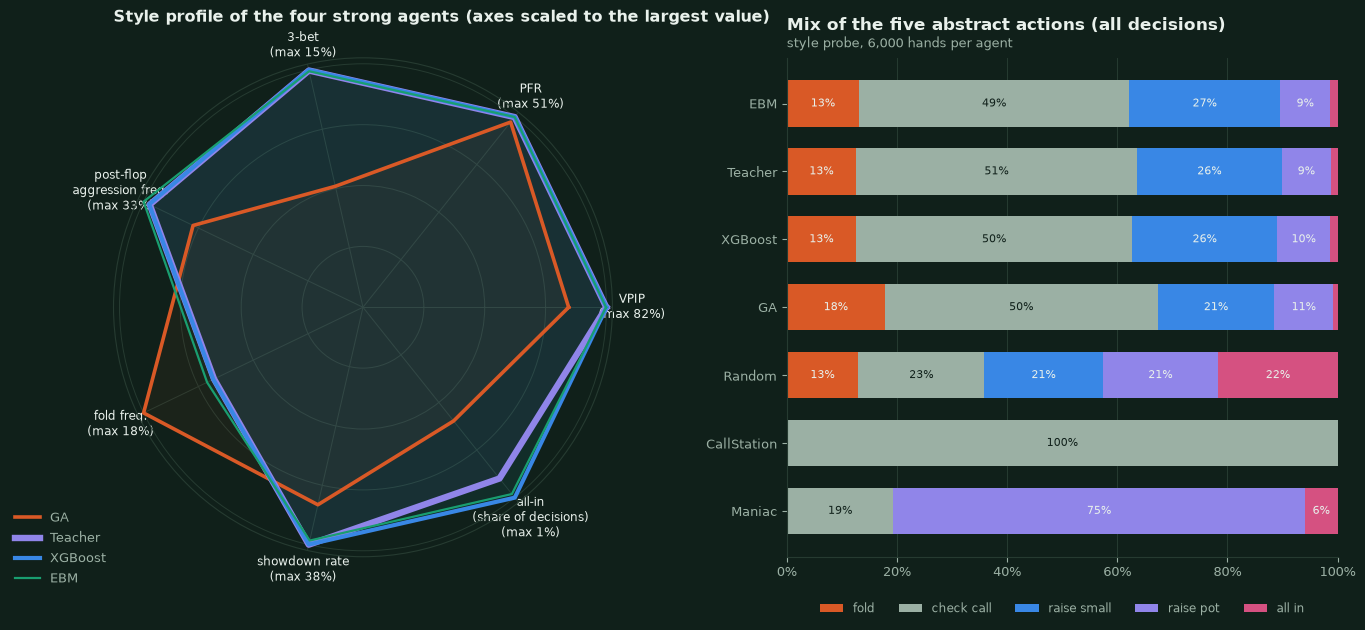

In [29]:
# ---- radar: seven style axes of the four strong agents, each normalised by the largest value among them (the bots are in the bar chart) ----
AXES = [
    ("VPIP", STYLE["vpip"]), ("PFR", STYLE["pfr"]), ("3-bet", STYLE["three_bet"]), ("post-flop\naggression freq.", STYLE["aggression_freq_postflop"]),
    ("fold freq.", STYLE["fold_freq"]), ("showdown rate", STYLE["showdown_rate"]), ("all-in\n(share of decisions)", MIX["ALL_IN"]),
]  # fmt: skip
angles = np.linspace(0, 2 * np.pi, len(AXES), endpoint=False)
fig = plt.figure(figsize=(14.0, 6.4))
ax = fig.add_subplot(1, 2, 1, projection="polar")
ax_bars = fig.add_subplot(1, 2, 2)
ax.set_facecolor(nbp.SURFACE)
AXIS_MAX = {name: series[list(STRONG)].max() for name, series in AXES}
for agent, width in zip(("GA", "Teacher", "XGBoost", "EBM"), (2.6, 4.6, 3.0, 1.6)):  # EBM, XGBoost and Teacher are nearly on top of each other: draw them from thick to thin
    values = np.array([series[agent] / AXIS_MAX[name] for name, series in AXES])
    closed = np.append(values, values[0])
    ax.plot(np.append(angles, angles[0]), closed, color=AGENT_COLORS[agent], linewidth=width, label=agent)
    ax.fill(np.append(angles, angles[0]), closed, color=AGENT_COLORS[agent], alpha=0.06)
ax.set_xticks(angles, [f"{name}\n(max {AXIS_MAX[name]:.0%})" for name, _ in AXES], fontsize=8.5, color=nbp.TEXT)
ax.set_yticks([0.25, 0.5, 0.75, 1.0], ["", "", "", ""])
ax.grid(color=nbp.GRID)
ax.spines["polar"].set_color(nbp.GRID)
ax.legend(loc="lower left", bbox_to_anchor=(-0.22, -0.08), fontsize=9)
ax.set_title("Style profile of the four strong agents (axes scaled to the largest value)", loc="left", pad=26, fontsize=11.5, fontweight="bold", color=nbp.TEXT)
bottom = np.zeros(len(ORDER))
ACTION_COLORS = {"FOLD": nbp.SERIES[2], "CHECK_CALL": nbp.MUTED, "RAISE_SMALL": nbp.SERIES[1], "RAISE_POT": nbp.SERIES[3], "ALL_IN": nbp.SERIES[5]}
for name in ACTIONS:
    ax_bars.barh(range(len(ORDER)), MIX[name], left=bottom, color=ACTION_COLORS[name], height=0.68, label=name.lower().replace("_", " "))
    for i, (v, b0) in enumerate(zip(MIX[name], bottom)):
        if v > 0.045:
            ax_bars.text(b0 + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color=nbp.SURFACE if name in ("CHECK_CALL",) else nbp.TEXT)
    bottom += MIX[name].to_numpy()
ax_bars.set_yticks(range(len(ORDER)), ORDER)
ax_bars.invert_yaxis()
ax_bars.set_xlim(0, 1)
ax_bars.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax_bars.grid(axis="y", visible=False)
ax_bars.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncols=5, fontsize=8.5)
nbp.title(ax_bars, "Mix of the five abstract actions (all decisions)", f"style probe, {STYLE_PROBE_HANDS * 6:,} hands per agent")
fig.tight_layout()
nbp.savefig("nb04_style_radar", fig)
plt.show()

### 7.3 Behaviour per street and where the profit comes from `[saved]`

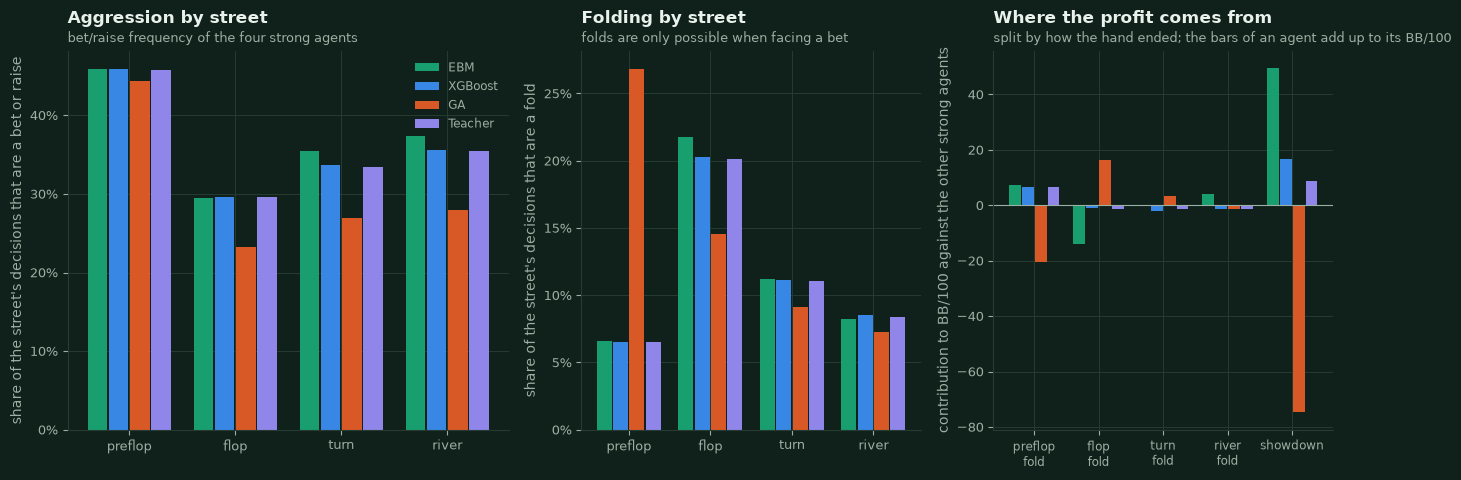

**[saved]** Contribution to BB/100 against the other three strong agents by how the hand ended, with the share of hands ending that way in parentheses (preflop/flop/turn/river = a fold on that street):

| agent | ends at preflop | ends at flop | ends at turn | ends at river | ends at showdown | total BB/100 |
|---|---|---|---|---|---|---|
| `EBM` | +7.2 (16%) | -14.0 (36%) | -0.0 (13%) | +4.1 (9%) | +49.5 (25%) | +46.8 |
| `XGBoost` | +6.7 (16%) | -1.1 (36%) | -2.0 (13%) | -1.2 (9%) | +16.5 (25%) | +19.0 |
| `GA` | -20.5 (29%) | +16.3 (25%) | +3.2 (12%) | -1.4 (9%) | -74.8 (25%) | -77.2 |
| `Teacher` | +6.7 (17%) | -1.2 (36%) | -1.2 (13%) | -1.5 (9%) | +8.7 (25%) | +11.4 |

In [30]:
STREETS = ("preflop", "flop", "turn", "river")
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.9), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
bar_w, offsets = 0.2, np.arange(len(STRONG)) - (len(STRONG) - 1) / 2
for k, agent in enumerate(STRONG):
    sub = STREET[STREET["agent"] == agent].set_index("street").loc[list(STREETS)]
    ax.bar(np.arange(4) + offsets[k] * bar_w, sub["raise_freq"], width=bar_w * 0.92, color=AGENT_COLORS[agent], label=agent)
ax.set_xticks(range(4), STREETS)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("share of the street's decisions that are a bet or raise")
ax.legend(fontsize=8.5)
nbp.title(ax, "Aggression by street", "bet/raise frequency of the four strong agents")
ax = axes[1]
for k, agent in enumerate(STRONG):
    sub = STREET[STREET["agent"] == agent].set_index("street").loc[list(STREETS)]
    ax.bar(np.arange(4) + offsets[k] * bar_w, sub["fold_freq"], width=bar_w * 0.92, color=AGENT_COLORS[agent])
ax.set_xticks(range(4), STREETS)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("share of the street's decisions that are a fold")
nbp.title(ax, "Folding by street", "folds are only possible when facing a bet")
ax = axes[2]
END_ORDER = ["preflop", "flop", "turn", "river", "showdown"]
strong_tally = {agent: tally_vs(agent, [o for o in STRONG if o != agent]) for agent in STRONG}
for k, agent in enumerate(STRONG):
    contribution = pd.DataFrame(strong_tally[agent].profit_by_end()).set_index("ended").loc[END_ORDER, "bb_per_100_contribution"]
    ax.bar(np.arange(5) + offsets[k] * bar_w, contribution, width=bar_w * 0.92, color=AGENT_COLORS[agent])
ax.axhline(0, color=nbp.MUTED, linewidth=0.8)
ax.set_xticks(range(5), [f"{e}\n{'fold' if e != 'showdown' else ''}".strip() for e in END_ORDER], fontsize=8.5)
ax.set_ylabel("contribution to BB/100 against the other strong agents")
nbp.title(ax, "Where the profit comes from", "split by how the hand ended; the bars of an agent add up to its BB/100")
fig.tight_layout()
nbp.savefig("nb04_style_streets", fig)
plt.show()

ends_rows = []
for agent in STRONG:
    split = pd.DataFrame(strong_tally[agent].profit_by_end()).set_index("ended").loc[END_ORDER]
    ends_rows.append({"agent": f"`{agent}`", **{f"ends at {e}": f"{split.loc[e, 'bb_per_100_contribution']:+.1f} ({pct(split.loc[e, 'share_of_hands'])})" for e in END_ORDER}, "total BB/100": f"{split['bb_per_100_contribution'].sum():+.1f}"})
display(Markdown("**[saved]** Contribution to BB/100 against the other three strong agents by how the hand ended, with the share of hands ending that way in parentheses (preflop/flop/turn/river = a fold on that street):"))
display(md_table(pd.DataFrame(ends_rows)))

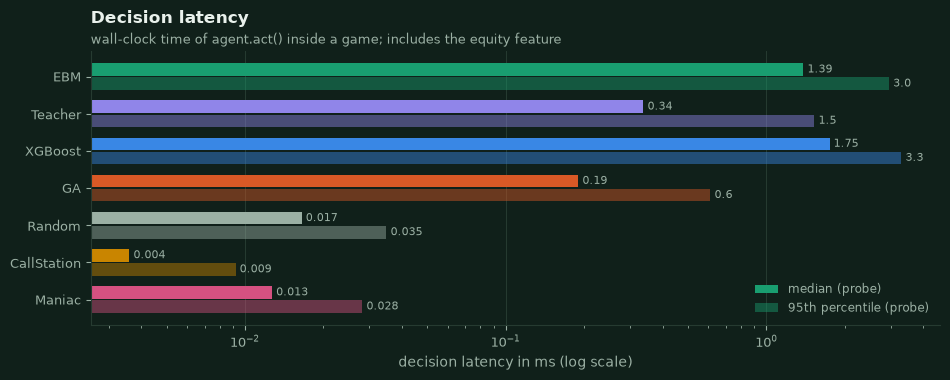

In [31]:
fig, ax = plt.subplots(figsize=(9.6, 3.9))
y = np.arange(len(ORDER))
ax.barh(y - 0.19, PROBE_LATENCY["median_ms"], height=0.34, color=[AGENT_COLORS[a] for a in ORDER], label="median (probe)")
ax.barh(y + 0.19, PROBE_LATENCY["p95_ms"], height=0.34, color=[AGENT_COLORS[a] for a in ORDER], alpha=0.45, label="95th percentile (probe)")
for yi, (m, p) in enumerate(zip(PROBE_LATENCY["median_ms"], PROBE_LATENCY["p95_ms"])):
    ax.annotate(f"{m:.3f}" if m < 0.1 else f"{m:.2f}", (m, yi - 0.19), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, color=nbp.MUTED)
    ax.annotate(f"{p:.3f}" if p < 0.1 else f"{p:.1f}", (p, yi + 0.19), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, color=nbp.MUTED)
ax.set_yticks(y, ORDER)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("decision latency in ms (log scale)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8.5)
nbp.title(ax, "Decision latency", "wall-clock time of agent.act() inside a game; includes the equity feature")
fig.tight_layout()
nbp.savefig("nb04_latency", fig)
plt.show()

In [32]:
def personality(agent: str) -> str:
    row, mix = STYLE.loc[agent], MIX.loc[agent]
    return (
        f"`{agent}`: VPIP {pct(row['vpip'])}, PFR {pct(row['pfr'])}, 3-bet {pct(row['three_bet'])}, aggression factor {row['aggression_factor']:.2f}, post-flop aggression frequency {pct(row['aggression_freq_postflop'])}; folds {pct(row['fold_freq'])} of its decisions, "
        f"reaches showdown in {pct(row['showdown_rate'])} of its hands and wins {pct(row['showdown_win_rate'])} of them; all-in is {pct(mix['ALL_IN'], 1)} of its decisions and an all-in happens in {pct(ALL_IN_HANDS[agent])} of its hands; median decision {PROBE_LATENCY.loc[agent, 'median_ms']:.2f} ms."
    )


family = ["EBM", "XGBoost", "Teacher"]
spread = {name: STYLE.loc[family, column].max() - STYLE.loc[family, column].min() for column, name in (("vpip", "VPIP"), ("pfr", "PFR"), ("three_bet", "3-bet"), ("aggression_freq_postflop", "post-flop aggression"), ("fold_freq", "fold frequency"), ("showdown_rate", "showdown rate"))}
pre = STREET[STREET["street"] == "preflop"].set_index("agent")
flop_fold_ends = {a: pd.DataFrame(strong_tally[a].profit_by_end()).set_index("ended").loc["flop", "bb_per_100_contribution"] for a in STRONG}
showdown_ends = {a: pd.DataFrame(strong_tally[a].profit_by_end()).set_index("ended").loc["showdown", "bb_per_100_contribution"] for a in STRONG}
PERSONALITY_LINES = "\n".join(f"* {personality(a)}" for a in ORDER)
display(Markdown("**The personalities in numbers `[saved]` `[fresh]`** (official run pooled over each agent's six opponents; action mix and all-in from the style probe):" + "\n\n" + PERSONALITY_LINES))
display(Markdown(f"""
**What the numbers say.**

* **EBM, XGBoost and the Teacher play almost the same style**: their VPIP, PFR, 3-bet, post-flop aggression, fold and showdown frequencies differ by at most {max(spread.values()) * 100:.1f} percentage points (largest: {max(spread, key=spread.get)}). The one visible difference is that the EBM is a little more aggressive: aggression factor
  {STYLE.loc['EBM', 'aggression_factor']:.2f} against {STYLE.loc['Teacher', 'aggression_factor']:.2f} (Teacher) and {STYLE.loc['XGBoost', 'aggression_factor']:.2f} (XGBoost), bet/raise frequency {pct(STYLE.loc['EBM', 'raise_freq'], 1)} against {pct(STYLE.loc['Teacher', 'raise_freq'], 1)} and {pct(STYLE.loc['XGBoost', 'raise_freq'], 1)} -
  a small difference in a statistic that the Teacher reads (section 9 asks whether it matters).
* **The GA is a different animal**: tighter before the flop (VPIP {pct(STYLE.loc['GA', 'vpip'])}; it folds {pct(pre.loc['GA', 'fold_freq'])} of its preflop decisions against {pct(pre.loc['Teacher', 'fold_freq'])} for the Teacher), with {1 - STYLE.loc['GA', 'three_bet'] / STYLE.loc['Teacher', 'three_bet']:.0%} fewer 3-bets ({pct(STYLE.loc['GA', 'three_bet'])} against {pct(STYLE.loc['Teacher', 'three_bet'])}), less post-flop
  aggression ({pct(STYLE.loc['GA', 'aggression_freq_postflop'])} against {pct(STYLE.loc['Teacher', 'aggression_freq_postflop'])}) and more folds ({pct(STYLE.loc['GA', 'fold_freq'])} against {pct(STYLE.loc['Teacher', 'fold_freq'])}). Against the other strong agents its profit sits in the wrong places: {flop_fold_ends['GA']:+.0f} BB/100 from hands that end with a flop fold
  (the Teacher {flop_fold_ends['Teacher']:+.0f}) but {showdown_ends['GA']:+.0f} at showdown (the Teacher {showdown_ends['Teacher']:+.0f}) - it wins {pct(strong_tally['GA'].metrics()['showdown_win_rate'])} of its showdowns against the strong agents (the Teacher {pct(strong_tally['Teacher'].metrics()['showdown_win_rate'])}) yet ends with a large net loss at showdown: it loses more chips in the showdowns it loses than it wins in the ones it wins.
* **The bots are caricatures**: the CallStation never folds and never raises (VPIP {pct(STYLE.loc['CallStation', 'vpip'])}, showdown in {pct(STYLE.loc['CallStation', 'showdown_rate'])} of its hands), the Maniac bets or raises {pct(STYLE.loc['Maniac', 'raise_freq'])} of the time and never folds, Random is all-in in {pct(MIX.loc['Random', 'ALL_IN'])} of its decisions.
* **Latency.** All agents decide in milliseconds ({', '.join(f"`{a}` {PROBE_LATENCY.loc[a, 'median_ms']:.2f}" for a in STRONG)} ms median in the probe); the official run played {meta['hands_per_second'] / meta['n_workers_used']:.0f} hands per second per worker including the equity estimates. The Teacher (features and rules, no model) needs {PROBE_LATENCY.loc['Teacher', 'median_ms']:.2f} ms per decision; the EBM needs {PROBE_LATENCY.loc['EBM', 'median_ms']:.2f} ms (the saved benchmark of its model alone: {EBM_META['inference']['predict_proba_median_ms']:.2f} ms) and
  XGBoost {PROBE_LATENCY.loc['XGBoost', 'median_ms']:.2f} ms ({XGB_META['inference']['predict_proba_median_ms']:.2f} ms) `[saved]`.
"""))

**The personalities in numbers `[saved]` `[fresh]`** (official run pooled over each agent's six opponents; action mix and all-in from the style probe):

* `EBM`: VPIP 82%, PFR 51%, 3-bet 15%, aggression factor 1.66, post-flop aggression frequency 33%; folds 12% of its decisions, reaches showdown in 38% of its hands and wins 53% of them; all-in is 1.3% of its decisions and an all-in happens in 9% of its hands; median decision 1.39 ms.
* `Teacher`: VPIP 82%, PFR 51%, 3-bet 15%, aggression factor 1.56, post-flop aggression frequency 32%; folds 12% of its decisions, reaches showdown in 38% of its hands and wins 52% of them; all-in is 1.2% of its decisions and an all-in happens in 10% of its hands; median decision 0.34 ms.
* `XGBoost`: VPIP 82%, PFR 51%, 3-bet 15%, aggression factor 1.57, post-flop aggression frequency 32%; folds 12% of its decisions, reaches showdown in 38% of its hands and wins 52% of them; all-in is 1.4% of its decisions and an all-in happens in 10% of its hands; median decision 1.75 ms.
* `GA`: VPIP 69%, PFR 50%, 3-bet 8%, aggression factor 1.78, post-flop aggression frequency 25%; folds 18% of its decisions, reaches showdown in 32% of its hands and wins 53% of them; all-in is 0.8% of its decisions and an all-in happens in 6% of its hands; median decision 0.19 ms.
* `Random`: VPIP 77%, PFR 63%, 3-bet 60%, aggression factor 5.09, post-flop aggression frequency 68%; folds 13% of its decisions, reaches showdown in 34% of its hands and wins 43% of them; all-in is 21.7% of its decisions and an all-in happens in 47% of its hands; median decision 0.02 ms.
* `CallStation`: VPIP 89%, PFR 0%, 3-bet 0%, aggression factor 0.00, post-flop aggression frequency 0%; folds 0% of its decisions, reaches showdown in 95% of its hands and wins 48% of them; all-in is 0.0% of its decisions and an all-in happens in 12% of its hands; median decision 0.00 ms.
* `Maniac`: VPIP 93%, PFR 82%, 3-bet 80%, aggression factor 6.68, post-flop aggression frequency 81%; folds 0% of its decisions, reaches showdown in 48% of its hands and wins 38% of them; all-in is 6.0% of its decisions and an all-in happens in 30% of its hands; median decision 0.01 ms.


**What the numbers say.**

* **EBM, XGBoost and the Teacher play almost the same style**: their VPIP, PFR, 3-bet, post-flop aggression, fold and showdown frequencies differ by at most 0.9 percentage points (largest: post-flop aggression). The one visible difference is that the EBM is a little more aggressive: aggression factor
  1.66 against 1.56 (Teacher) and 1.57 (XGBoost), bet/raise frequency 37.7% against 37.0% and 37.1% -
  a small difference in a statistic that the Teacher reads (section 9 asks whether it matters).
* **The GA is a different animal**: tighter before the flop (VPIP 69%; it folds 27% of its preflop decisions against 7% for the Teacher), with 49% fewer 3-bets (8% against 15%), less post-flop
  aggression (25% against 32%) and more folds (18% against 12%). Against the other strong agents its profit sits in the wrong places: +16 BB/100 from hands that end with a flop fold
  (the Teacher -1) but -75 at showdown (the Teacher +9) - it wins 50% of its showdowns against the strong agents (the Teacher 43%) yet ends with a large net loss at showdown: it loses more chips in the showdowns it loses than it wins in the ones it wins.
* **The bots are caricatures**: the CallStation never folds and never raises (VPIP 89%, showdown in 95% of its hands), the Maniac bets or raises 80% of the time and never folds, Random is all-in in 22% of its decisions.
* **Latency.** All agents decide in milliseconds (`EBM` 1.39, `XGBoost` 1.75, `GA` 0.19, `Teacher` 0.34 ms median in the probe); the official run played 100 hands per second per worker including the equity estimates. The Teacher (features and rules, no model) needs 0.34 ms per decision; the EBM needs 1.39 ms (the saved benchmark of its model alone: 0.55 ms) and
  XGBoost 1.75 ms (1.57 ms) `[saved]`.


## 8. Interesting hands and decisions

Three hands, chosen by a stated rule to show something specific. The two from the official sample are replayed **exactly** (section 2.3 explained why a saved session can be re-run bit for bit) so that we know the observation every agent had at every decision,
including its opponent statistics. The replay uses the package's own duplicate-protocol code (`play_duplicate_deals`) with a recorder wrapped around the agents; because the two tables of a session are independent, a hand is reproduced by replaying its session up to its deal.
For selected decisions the other agents are then asked, *offline*, what they would do with the very same observation, and their explanations are shown side by side.
A hand table shows both players' hole cards - a **post-hoc spectator view** from `HandRecord.replay()`; the agents themselves never saw them. A single hand proves nothing about strength.

1. **A call that depends on a statistic**: EBM vs Teacher, from the official sample of the EBM's biggest wins (the first one in which the Teacher's call would have been a fold had its belief about the EBM's aggression been neutral).
2. **A Maniac pays off**: EBM vs Maniac, the first hand of the official sample of the EBM's biggest wins in which the EBM calls a post-flop bet.
3. **A semi-bluff of the GA** (a fresh, seeded scan of GA vs Teacher deals played with the duplicate protocol).

In [33]:
@dataclasses.dataclass(frozen=True)
class RecordedDecision:
    table: int
    seat: int
    obs: object
    decision: object


class ObservationRecorder(Agent):
    """Plays exactly like ``inner`` and keeps every observation it is shown with the decision it returns (including the explanation the decision carries)."""

    architecture = "recorder"

    def __init__(self, inner: Agent, table: int, seat: int, log: list) -> None:
        self.inner, self.table, self.seat, self.log, self.name = inner, table, seat, log, inner.name

    def reset(self, seed: int | None = None) -> None:
        self.inner.reset(seed)

    def act(self, obs):
        decision = self.inner.act(obs)
        self.log.append(RecordedDecision(self.table, self.seat, obs, decision))
        return decision

    def end_hand(self, summary) -> None:
        self.inner.end_hand(summary)


def play_recorded(make_inner_agents, deals, protocol: str = TWO_TABLE):
    """Play ``deals`` with the package's duplicate protocol and record every decision. ``make_inner_agents(table)`` returns the two (already reset) agents of a table.
    Returns ``(hands, log)``: the ``DuplicateHand`` list in layout order (hand 2p + t is deal p at table t) and the list of ``RecordedDecision``."""
    log: list[RecordedDecision] = []

    def make_agents(table):
        a, b = make_inner_agents(table)
        return ObservationRecorder(a, 0 if table is None else table, 0, log), ObservationRecorder(b, 0 if table is None else table, 1, log)

    return list(play_duplicate_deals(GAME, deals, make_agents, protocol)), log


def hand_steps(hands, log, table: int, position: int):
    """The decisions of one hand as ``[(seat, observation, decision, event)]`` (events and decisions of a hand are in the same order)."""
    decisions = [d for d in log if d.table == table and d.obs.hand_number == position]
    events = hands[2 * position + table].record.events
    return [(d.seat, d.obs, d.decision, e) for d, e in zip(decisions, events)]


KIND_OF = {"EBM": "ebm", "XGBoost": "xgboost", "GA": "ga", "Teacher": "teacher", "Random": "random", "CallStation": "call_station", "Maniac": "maniac"}


def replay_official_hand(a: str, b: str, hand_index: int, cfg: MatchConfig = OFFICIAL_CFG):
    """Re-play the session that contains ``hand_index`` of the official pairing up to that hand: same deals, same agent streams, same opponent statistics, same protocol code.
    Returns ``(HandRecord, steps)``."""
    first, second = official_stem(a, b)
    specs = (AgentSpec(KIND_OF[first], label=first), AgentSpec(KIND_OF[second], label=second))
    key = match_key(first, second)
    session_index, local = divmod(hand_index, cfg.session_hands)
    position, table = divmod(local, 2)  # layout: [table 0 deal 0, table 1 deal 0, table 0 deal 1, ...]
    first_deal = session_index * cfg.session_hands // cfg.hands_per_unit
    deals = [Deal.from_seed(deal_seed(cfg.seed, key, first_deal + q)) for q in range(position + 1)]

    def make_inner(t):
        pair = (create_agent(specs[0]), create_agent(specs[1]))
        for agent, spec in zip(pair, specs):
            agent.name = spec.label
            agent.reset(agent_seed(cfg.seed, key, spec.label, session_index, t))
        return pair

    hands, log = play_recorded(make_inner, deals, cfg.protocol)
    return hands[2 * position + table].record, hand_steps(hands, log, table, position)


def official_sample_hands(a: str, b: str, tag: str) -> list[tuple[int, object]]:
    info = RES.sample_hands_info(tag, a, b)
    return [(int(h), rec) for h, rec in zip(info["hand_index"], RES.sample_hands(tag, a, b))]


def replay_checked(a: str, b: str, hand_index: int, stored):
    """Replay a sample hand and assert that it reproduces the stored record exactly."""
    record, steps = replay_official_hand(a, b, hand_index)
    assert record.events == stored.events and record.result == stored.result, "the replay must reproduce the stored hand exactly"
    return record, steps


ACTION_TEXT = {"FOLD": "fold", "CHECK_CALL": "check/call", "RAISE_SMALL": "raise 1/2 pot", "RAISE_POT": "raise pot", "ALL_IN": "all-in"}
STREET_NAME = {Street.PREFLOP: "preflop", Street.FLOP: "flop", Street.TURN: "turn", Street.RIVER: "river"}


def hand_story(record, names: tuple[str, str]) -> Markdown:
    """Header and action table of a hand (post-hoc spectator view: hole cards of both players are shown)."""
    deal = record.deal
    holes = {record.button_seat: deal.button_hole, 1 - record.button_seat: deal.bb_hole}
    views = list(record.replay())
    rows = []
    for i, (event, decision) in enumerate(zip(record.events, record.decisions)):
        before = views[i]
        rows.append(
            {
                "street": event.street.name.lower(), "board": pretty(before.board), "pot": before.pot,
                "player": f"{names[event.seat]} ({'button' if event.seat == record.button_seat else 'big blind'})",
                "action": f"{event.kind} {event.chips}" if event.chips else event.kind, "abstract": ACTION_TEXT.get(decision.abstract, decision.abstract),
                "all-in": "yes" if event.all_in else "",
            }
        )
    head = (
        f"**{names[0]}** holds {pretty(holes[0])}, **{names[1]}** holds {pretty(holes[1])}; board {pretty(record.result.board)}. "
        f"Result: {names[0]} {record.result.payoffs[0] / GAME.big_blind:+.0f} BB, {names[1]} {record.result.payoffs[1] / GAME.big_blind:+.0f} BB "
        f"({'showdown' if record.result.showdown else 'no showdown'})."
    )
    return Markdown(head + "\n\n" + md_table(pd.DataFrame(rows)).data)


def fresh_panel() -> dict[str, Agent]:
    panel = {"EBM": create_agent("ebm"), "XGBoost": create_agent("xgboost"), "GA": GeneticAgent.load(name="GA"), "Teacher": create_agent("teacher")}
    for i, agent in enumerate(panel.values()):
        agent.reset(derive_seed("test", "nb04-panel", i))
    return panel


def format_value(value) -> str:
    return "(" + ", ".join(f"{v:.2f}" for v in value) + ")" if isinstance(value, (list, tuple)) else f"{value:.2f}"


def ask_panel(obs) -> dict[str, dict]:
    """Every agent decides and explains the SAME observation (offline: nothing is played)."""
    answers = {}
    for name, agent in fresh_panel().items():
        decision = agent.act(obs)
        explanation = agent.explain(obs, decision)
        answers[name] = {"action": decision.abstract.name, "summary": explanation.summary, "details": explanation.details}
    return answers


def panel_table(obs) -> tuple[Markdown, dict]:
    answers = ask_panel(obs)
    rows = []
    for name, answer in answers.items():
        if name in ("EBM", "XGBoost"):
            top = answer["details"]["top_features"][:4]
            why = "; ".join(f"`{f['feature']}` = {format_value(f['value'])} ({f['contribution']:+.2f})" for f in top)
            kind = "top contributions to the chosen action's log-odds"
        elif name == "GA":
            why, kind = answer["summary"].replace("->", "=>"), "rule trace"
        else:
            why, kind = answer["summary"], "rule trace"
        rows.append({"agent": name, "would play": ACTION_TEXT[answer["action"]], "explanation type": kind, "explanation": why})
    return md_table(pd.DataFrame(rows)), answers


MADE_HAND = ("high card", "one pair", "two pair", "three of a kind", "straight", "flush", "full house", "four of a kind", "straight flush")
display(Markdown("Replay and recording helpers defined: `play_recorded`, `replay_official_hand`, `hand_story`, `panel_table`."))

Replay and recording helpers defined: `play_recorded`, `replay_official_hand`, `hand_story`, `panel_table`.

In [34]:
from poker_arena.equity import made_hand_category  # noqa: E402

DECISIONS = {}  # key -> (title, observation, answers) for the explanation figure
teacher_probe = create_agent("teacher")


def teacher_calls_that_could_flip(steps):
    """The Teacher's calls of a bet in this hand, with what it would have done had its belief about the opponent's aggression been the neutral prior."""
    out = []
    for seat, obs, decision, event in steps:
        if seat == 1 and obs.to_call > 0 and decision.abstract.name == "CHECK_CALL":
            neutral_obs = dataclasses.replace(obs, opponent_stats=dataclasses.replace(obs.opponent_stats, aggression=NEUTRAL_STATS.aggression))
            out.append((obs, event, teacher_probe.act(neutral_obs).abstract.name, neutral_obs))
    return out


chosen = None
for hand_index, stored in official_sample_hands("EBM", "Teacher", "biggest_win_a"):
    record1, steps1 = replay_checked("EBM", "Teacher", hand_index, stored)
    flips = [c for c in teacher_calls_that_could_flip(steps1) if c[2] == "FOLD"]
    if flips and chosen is None:
        chosen = (hand_index, record1, steps1, flips[-1])
        break
if chosen is None:  # no such hand in the sample: take the first one and its last Teacher call
    hand_index, stored = official_sample_hands("EBM", "Teacher", "biggest_win_a")[0]
    record1, steps1 = replay_checked("EBM", "Teacher", hand_index, stored)
    last_call = teacher_calls_that_could_flip(steps1)[-1]
    chosen = (hand_index, record1, steps1, last_call)
hand_index, record1, steps1, (obs, event, neutral_action, neutral_obs) = chosen
hand1_flips = neutral_action == "FOLD"
numbers_seen = teacher_probe.explain(obs, teacher_probe.act(obs)).details["numbers"]
numbers_neutral = teacher_probe.explain(neutral_obs, teacher_probe.act(neutral_obs)).details["numbers"]
table, answers = panel_table(obs)
DECISIONS["call"] = (f"The Teacher facing a bet on the {STREET_NAME[obs.street]}", obs, answers)
display(Markdown(f"### Hand 1 - EBM vs Teacher: a Teacher call {'that depends on a statistic' if hand1_flips else ''} `[replay]`"))
display(hand_story(record1, ("EBM", "Teacher")))
display(Markdown(
    f"(Official sample hand {hand_index}; replayed exactly.) The Teacher **calls** a bet on the {STREET_NAME[obs.street]} (the call costs {event.chips} chips; the pot holds {obs.pot} before it) holding {pretty(obs.my_hole)} on {pretty(obs.board)} "
    f"({MADE_HAND[made_hand_category(obs.my_hole, obs.board)]}). All four agents are asked this decision; the Teacher's own opponent statistics at that moment are in the observation: it believes the EBM's post-flop aggression is "
    f"**{obs.opponent_stats.aggression:.2f}** (neutral prior {NEUTRAL_STATS.aggression:.2f}) after {obs.opponent_stats.hands} hands at this table."
))
display(table)
display(Markdown(
    f"**[replay]** Equity against a random hand is {numbers_seen['equity']:.0%} either way. With the aggression statistic the Teacher actually had, the range penalty is {numbers_seen['penalty']:.0%} and the adjusted equity "
    f"{numbers_seen['adj_equity']:.0%} against a price of {numbers_seen['required_equity']:.0%} - **{ACTION_TEXT[answers['Teacher']['action']]}**. If the statistic had been the neutral {NEUTRAL_STATS.aggression:.2f}, the penalty would be "
    f"{numbers_neutral['penalty']:.0%}, the adjusted equity {numbers_neutral['adj_equity']:.0%} - **{ACTION_TEXT[neutral_action]}**."
    + (" The decision hangs on one smoothed statistic, a thread that section 9 pulls on." if hand1_flips else " (No hand of the sample flips; the thread of section 9 is shown by the statistic's effect on the penalty.)")
))

### Hand 1 - EBM vs Teacher: a Teacher call that depends on a statistic `[replay]`

**EBM** holds 2♠ T♠, **Teacher** holds 8♦ A♥; board J♥ T♥ 8♠ 3♠ 6♠. Result: EBM +100 BB, Teacher -100 BB (showdown).

| street | board | pot | player | action | abstract | all-in |
|---|---|---|---|---|---|---|
| preflop | - | 15 | EBM (button) | raise 15 | raise 1/2 pot |  |
| preflop | - | 30 | Teacher (big blind) | raise 50 | raise pot |  |
| preflop | - | 80 | EBM (button) | call 40 | check/call |  |
| flop | J♥ T♥ 8♠ | 120 | Teacher (big blind) | bet 60 | raise 1/2 pot |  |
| flop | J♥ T♥ 8♠ | 180 | EBM (button) | call 60 | check/call |  |
| turn | J♥ T♥ 8♠ 3♠ | 240 | Teacher (big blind) | bet 120 | raise 1/2 pot |  |
| turn | J♥ T♥ 8♠ 3♠ | 360 | EBM (button) | call 120 | check/call |  |
| river | J♥ T♥ 8♠ 3♠ 6♠ | 480 | Teacher (big blind) | bet 240 | raise 1/2 pot |  |
| river | J♥ T♥ 8♠ 3♠ 6♠ | 720 | EBM (button) | raise 760 | all-in | yes |
| river | J♥ T♥ 8♠ 3♠ 6♠ | 1480 | Teacher (big blind) | call 520 | check/call | yes |

(Official sample hand 235; replayed exactly.) The Teacher **calls** a bet on the river (the call costs 520 chips; the pot holds 1480 before it) holding 8♦ A♥ on J♥ T♥ 8♠ 3♠ 6♠ (one pair). All four agents are asked this decision; the Teacher's own opponent statistics at that moment are in the observation: it believes the EBM's post-flop aggression is **0.64** (neutral prior 0.40) after 17 hands at this table.

| agent | would play | explanation type | explanation |
|---|---|---|---|
| EBM | check/call | top contributions to the chosen action's log-odds | `equity_minus_pot_odds` = 0.38 (+1.88); `opp_raised_this_street` = 1.00 (+0.77); `equity x opp_fold_to_bet` = (0.64, 0.39) (-0.56); `i_raised_this_street` = 1.00 (+0.52) |
| XGBoost | check/call | top contributions to the chosen action's log-odds | `equity_minus_pot_odds` = 0.38 (+2.01); `opp_aggression` = 0.64 (-0.57); `pot_bb` = 148.00 (+0.56); `opp_pfr` = 0.34 (-0.47) |
| GA | check/call | rule trace | river: equity 0.60 => adjusted 0.60 (+0.00 position, -0.00 deep stacks); adjusted >= required 0.38: pot odds 0.26 + call_margin +0.04 + fold_big_bet 0.12 + adapt_aggression -0.05 => call. |
| Teacher | check/call | rule trace | Call: equity 64% less 28% for the bettor's range is 36%, above the 31% price (pot odds 26%). |

**[replay]** Equity against a random hand is 64% either way. With the aggression statistic the Teacher actually had, the range penalty is 28% and the adjusted equity 36% against a price of 31% - **check/call**. If the statistic had been the neutral 0.40, the penalty would be 47%, the adjusted equity 17% - **fold**. The decision hangs on one smoothed statistic, a thread that section 9 pulls on.

In [35]:
chosen2 = None
for hand_index2, stored2 in official_sample_hands("EBM", "Maniac", "biggest_win_a"):
    record2, steps2 = replay_checked("EBM", "Maniac", hand_index2, stored2)
    calls = [s for s in steps2 if s[0] == 0 and s[1].street != Street.PREFLOP and s[1].to_call > 0 and s[2].abstract.name == "CHECK_CALL"]
    if calls and record2.result.showdown:
        chosen2 = (hand_index2, record2, steps2, calls[0])
        break
hand_index2, record2, steps2, call2 = chosen2
maniac_hole = record2.deal.button_hole if record2.button_seat == 1 else record2.deal.bb_hole
display(Markdown("### Hand 2 - EBM vs Maniac: the Maniac pays off `[replay]`"))
display(hand_story(record2, ("EBM", "Maniac")))
obs2 = call2[1]
table, answers = panel_table(obs2)
DECISIONS["maniac"] = (f"The EBM facing a Maniac bet on the {STREET_NAME[obs2.street]}", obs2, answers)
display(Markdown(
    f"(Official sample hand {hand_index2}; replayed exactly.) At showdown the Maniac shows **{MADE_HAND[made_hand_category(maniac_hole, record2.result.board)]}** and the EBM **{MADE_HAND[made_hand_category(record2.deal.bb_hole if record2.button_seat == 1 else record2.deal.button_hole, record2.result.board)]}**. "
    f"Asked about the EBM's first call of a post-flop bet (hand {pretty(obs2.my_hole)}, board {pretty(obs2.board)}, {obs2.to_call} to call, pot {obs2.pot} including the bets; observed Maniac aggression "
    f"{obs2.opponent_stats.aggression:.2f}, fold-to-bet {obs2.opponent_stats.fold_to_bet:.2f}):"
))
display(table)

### Hand 2 - EBM vs Maniac: the Maniac pays off `[replay]`

**EBM** holds K♦ 4♣, **Maniac** holds T♥ 2♥; board K♣ 8♠ 5♥ J♥ 6♠. Result: EBM +100 BB, Maniac -100 BB (showdown).

| street | board | pot | player | action | abstract | all-in |
|---|---|---|---|---|---|---|
| preflop | - | 15 | EBM (button) | raise 15 | raise 1/2 pot |  |
| preflop | - | 30 | Maniac (big blind) | raise 50 | raise pot |  |
| preflop | - | 80 | EBM (button) | call 40 | check/call |  |
| flop | K♣ 8♠ 5♥ | 120 | Maniac (big blind) | bet 120 | raise pot |  |
| flop | K♣ 8♠ 5♥ | 240 | EBM (button) | call 120 | check/call |  |
| turn | K♣ 8♠ 5♥ J♥ | 360 | Maniac (big blind) | bet 360 | raise pot |  |
| turn | K♣ 8♠ 5♥ J♥ | 720 | EBM (button) | call 360 | check/call |  |
| river | K♣ 8♠ 5♥ J♥ 6♠ | 1080 | Maniac (big blind) | bet 460 | all-in | yes |
| river | K♣ 8♠ 5♥ J♥ 6♠ | 1540 | EBM (button) | call 460 | check/call | yes |

(Official sample hand 4; replayed exactly.) At showdown the Maniac shows **high card** and the EBM **one pair**. Asked about the EBM's first call of a post-flop bet (hand K♦ 4♣, board K♣ 8♠ 5♥, 120 to call, pot 240 including the bets; observed Maniac aggression 0.40, fold-to-bet 0.33):

| agent | would play | explanation type | explanation |
|---|---|---|---|
| EBM | check/call | top contributions to the chosen action's log-odds | `equity_minus_pot_odds` = 0.50 (+2.78); `equity x opp_fold_to_bet` = (0.83, 0.33) (-0.94); `equity` = 0.83 (+0.86); `opp_raised_this_street` = 1.00 (+0.77) |
| XGBoost | check/call | top contributions to the chosen action's log-odds | `equity_minus_pot_odds` = 0.50 (+2.69); `opp_aggression` = 0.40 (-1.55); `pot_odds` = 0.33 (-1.18); `equity` = 0.83 (+0.92) |
| GA | check/call | rule trace | flop: equity 0.87 => adjusted 0.84 (-0.00 position, -0.02 deep stacks); adjusted >= required 0.60: pot odds 0.33 + call_margin +0.04 + fold_big_bet 0.23 + adapt_aggression -0.00 => call. |
| Teacher | check/call | rule trace | Call: equity 83% less 26% for the bettor's range is 57%, above the 36% price (pot odds 33%). |

In [36]:
# Hand 3: a fresh, seeded scan for a GA semi-bluff that wins the pot immediately (GA vs Teacher; the GA's decisions carry their explanations)
SCAN_DEALS = 300
scan_deals = [Deal.from_seed(derive_seed("test", "nb04-ga-scan", "deal", p)) for p in range(SCAN_DEALS)]


def make_scan_agents(table):
    ga, teacher = GeneticAgent.load(name="GA"), create_agent("teacher")
    ga.reset(derive_seed("test", "nb04-ga-scan", "ga", table))
    teacher.reset(derive_seed("test", "nb04-ga-scan", "teacher", table))
    return ga, teacher


scan_hands, scan_log = play_recorded(make_scan_agents, scan_deals, TWO_TABLE)
candidates = []
for table in (0, 1):
    for position in range(SCAN_DEALS):
        steps = hand_steps(scan_hands, scan_log, table, position)
        for k, (seat, obs, decision, event) in enumerate(steps):
            if seat == 0 and decision.explanation is not None and "semi-bluff" in decision.explanation.summary and event.kind in ("bet", "raise") and k + 1 < len(steps) and steps[k + 1][3].kind == "fold":
                candidates.append((event.chips, table, position, k, steps))
best_chips, best_table, best_position, k3, steps3 = max(candidates, key=lambda c: (c[0], -c[2], -c[1]))
record3 = scan_hands[2 * best_position + best_table].record
display(Markdown("### Hand 3 - GA vs Teacher: a semi-bluff `[demo]`"))
display(Markdown(f"(Fresh scan of {SCAN_DEALS} deals x 2 tables, seed namespace `test`: {len(candidates)} hands in which the GA's semi-bluff bet or raise was followed by an immediate fold; the largest one is shown.)"))
display(hand_story(record3, ("GA", "Teacher")))
ga_obs = steps3[k3][1]
table, answers = panel_table(ga_obs)
DECISIONS["bluff"] = ("The GA's semi-bluff", ga_obs, answers)
display(Markdown(
    f"The GA's own explanation, produced at the time of the decision: *{steps3[k3][2].explanation.summary.replace('->', '=>')}* The other agents on the same observation "
    f"(hand {pretty(ga_obs.my_hole)}, board {pretty(ga_obs.board)}, pot {ga_obs.pot}, {ga_obs.to_call} to call; the GA row is a fresh draw of its private random coins, so it can differ from what was played):"
))
display(table)

### Hand 3 - GA vs Teacher: a semi-bluff `[demo]`

(Fresh scan of 300 deals x 2 tables, seed namespace `test`: 17 hands in which the GA's semi-bluff bet or raise was followed by an immediate fold; the largest one is shown.)

**GA** holds K♣ 6♣, **Teacher** holds Q♦ A♠; board 5♣ K♦ 4♣. Result: GA +12 BB, Teacher -12 BB (no showdown).

| street | board | pot | player | action | abstract | all-in |
|---|---|---|---|---|---|---|
| preflop | - | 15 | GA (button) | raise 15 | raise 1/2 pot |  |
| preflop | - | 30 | Teacher (big blind) | raise 50 | raise pot |  |
| preflop | - | 80 | GA (button) | call 40 | check/call |  |
| flop | 5♣ K♦ 4♣ | 120 | Teacher (big blind) | bet 60 | raise 1/2 pot |  |
| flop | 5♣ K♦ 4♣ | 180 | GA (button) | raise 300 | raise pot |  |
| flop | 5♣ K♦ 4♣ | 480 | Teacher (big blind) | fold | fold |  |

The GA's own explanation, produced at the time of the decision: *flop: equity 0.86 => adjusted 0.82 (-0.00 position, -0.03 deep stacks); draw and coin 0.23 < semi-bluff probability 0.39 (semi_bluff_freq 0.46 -0.08 adaptation) => semi-bluff raise (pot-size).* The other agents on the same observation (hand K♣ 6♣, board 5♣ K♦ 4♣, pot 180, 60 to call; the GA row is a fresh draw of its private random coins, so it can differ from what was played):

| agent | would play | explanation type | explanation |
|---|---|---|---|
| EBM | raise 1/2 pot | top contributions to the chosen action's log-odds | `equity` = 0.88 (-4.28); `equity_minus_pot_odds` = 0.62 (+2.31); `opp_raised_this_street` = 1.00 (-2.19); `flush_draw` = 1.00 (+1.76) |
| XGBoost | raise 1/2 pot | top contributions to the chosen action's log-odds | `straight_outs` = 0.00 (-2.21); `equity_minus_pot_odds` = 0.62 (+2.08); `num_raises_street` = 1.00 (-1.82); `equity` = 0.88 (-1.16) |
| GA | raise pot | rule trace | flop: equity 0.88 => adjusted 0.84 (-0.00 position, -0.03 deep stacks); draw and coin 0.02 < semi-bluff probability 0.39 (semi_bluff_freq 0.46 -0.08 adaptation) => semi-bluff raise (pot-size). |
| Teacher | raise 1/2 pot | rule trace | Raise for value: equity 88% >= 86% even against a betting range. |

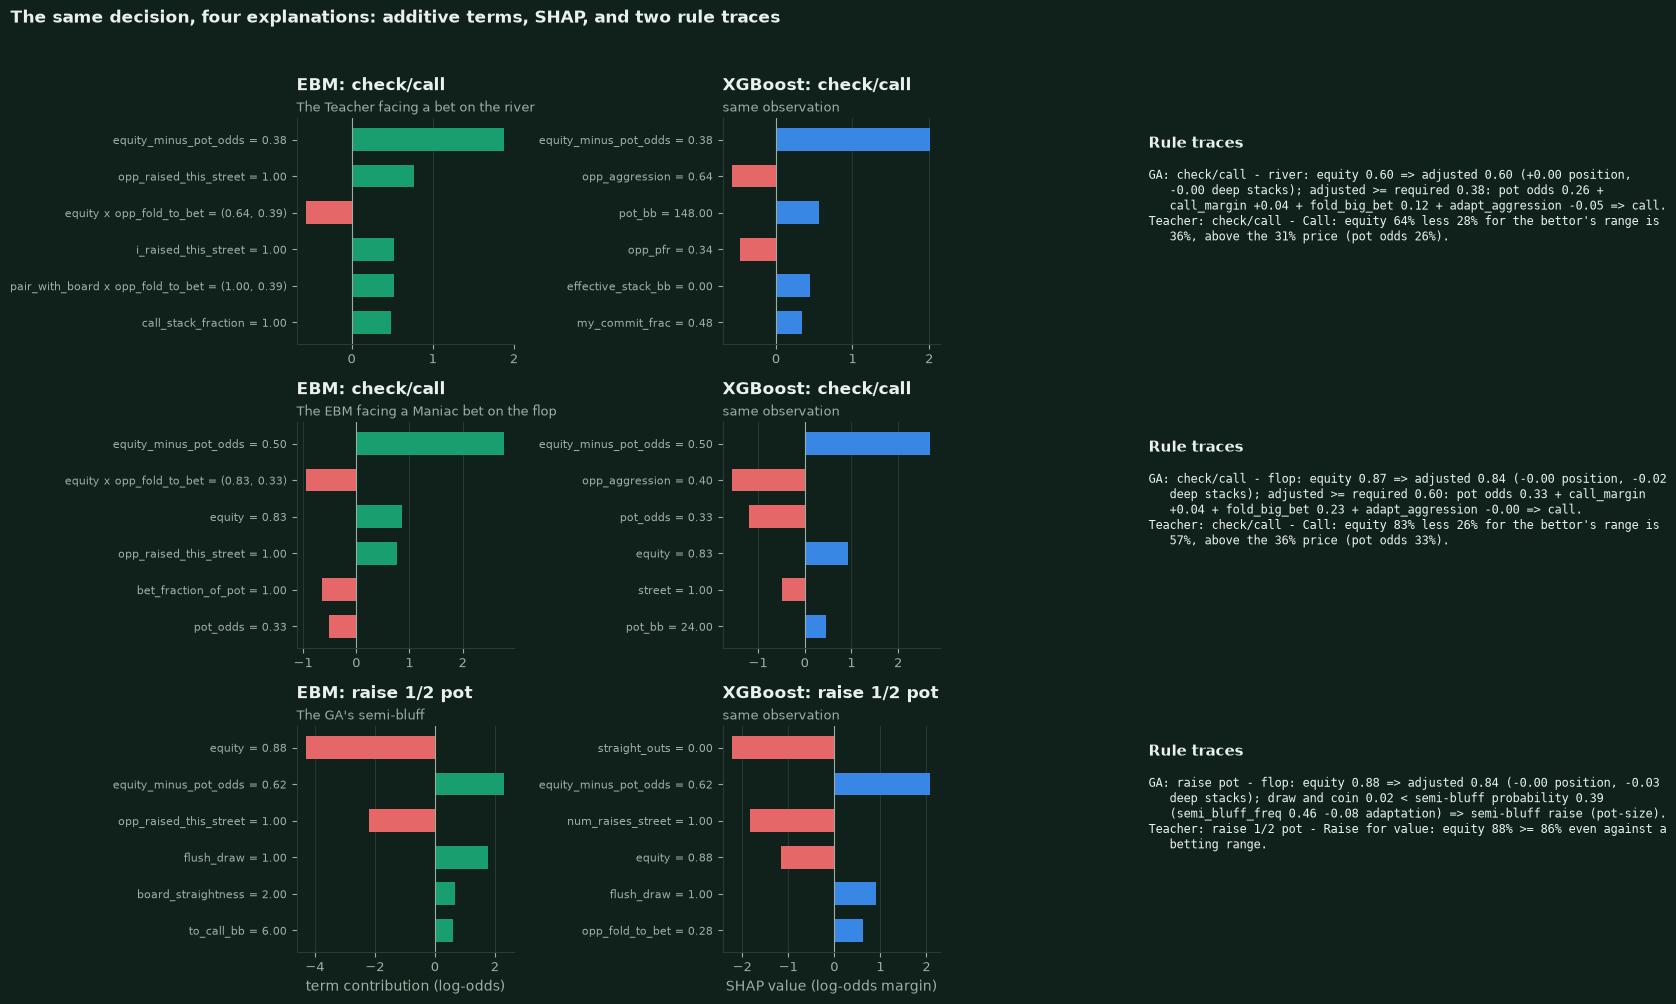

In [37]:
fig, axes = plt.subplots(len(DECISIONS), 3, figsize=(15.5, 3.4 * len(DECISIONS)), gridspec_kw={"width_ratios": [1, 1, 1.05]})
TOP = 6
for row, (key, (title, obs, answers)) in enumerate(DECISIONS.items()):
    for col, name in enumerate(("EBM", "XGBoost")):
        ax = axes[row, col]
        items = answers[name]["details"]["top_features"][:TOP]
        labels = [f"{f['feature']} = {format_value(f['value'])}" for f in items]
        values = [f["contribution"] for f in items]
        ax.barh(range(len(items)), values, color=[AGENT_COLORS[name] if v >= 0 else nbp.WARM for v in values], height=0.62)
        ax.set_yticks(range(len(items)), labels, fontsize=8.2)
        ax.invert_yaxis()
        ax.axvline(0, color=nbp.MUTED, linewidth=0.8)
        ax.grid(axis="y", visible=False)
        unit = "term contribution (log-odds)" if name == "EBM" else "SHAP value (log-odds margin)"
        ax.set_xlabel(unit if row == len(DECISIONS) - 1 else "")
        nbp.title(ax, f"{name}: {ACTION_TEXT[answers[name]['action']]}", title if col == 0 else "same observation")
    ax = axes[row, 2]
    ax.axis("off")
    text = "\n".join(
        textwrap.fill(f"{name}: {ACTION_TEXT[answers[name]['action']]} - " + answers[name]["summary"].replace("->", "=>"), 74, subsequent_indent="   ") for name in ("GA", "Teacher")
    )
    ax.text(0.0, 0.92, "Rule traces", fontsize=11, fontweight="bold", color=nbp.TEXT, va="top", transform=ax.transAxes)
    ax.text(0.0, 0.78, text, fontsize=8.6, color=nbp.TEXT, va="top", transform=ax.transAxes, family="monospace")
fig.suptitle("The same decision, four explanations: additive terms, SHAP, and two rule traces", x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=nbp.TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.96))
nbp.savefig("nb04_decision_explanations", fig)
plt.show()

In [38]:
lines = []
for key, (title, obs, answers) in DECISIONS.items():
    actions = {name: answers[name]["action"] for name in answers}
    counts = pd.Series(actions).value_counts()
    majority = counts.index[0]
    odd = [f"`{n}` ({ACTION_TEXT[a]})" for n, a in actions.items() if a != majority]
    lines.append(
        f"* **{title}**: {'all four agents choose the same action (' + ACTION_TEXT[majority] + ')' if not odd else f'{counts.iloc[0]} agents choose ' + ACTION_TEXT[majority] + ', but ' + ', '.join(odd) + ' play(s) a different action'}; "
        f"top-ranked components: EBM `{answers['EBM']['details']['top_features'][0]['feature']}`, XGBoost `{answers['XGBoost']['details']['top_features'][0]['feature']}`."
    )
display(Markdown(
    "**What the side-by-side shows `[demo]`.**\n\n" + "\n".join(lines) + "\n\n"
    "The additive and SHAP explanations answer the question *which inputs moved the model's score*, in the units of the model (log-odds); they list correlated quantities (`equity`, `equity_minus_pot_odds`, `pot_odds`) side by side and do not say *why a poker player would "
    "call*. The rule traces answer *which rule fired and what it compared*: they are readable by a poker player but only as good as the rules. None of the four explains the decision in terms of the opponent's range or of the *other agent's statistic*"
    + (" - which is exactly what decided hand 1 (the Teacher's trace *does* show the penalty, but not that the penalty was a function of a belief about the opponent that could have been different)." if hand1_flips else ".")
))

**What the side-by-side shows `[demo]`.**

* **The Teacher facing a bet on the river**: all four agents choose the same action (check/call); top-ranked components: EBM `equity_minus_pot_odds`, XGBoost `equity_minus_pot_odds`.
* **The EBM facing a Maniac bet on the flop**: all four agents choose the same action (check/call); top-ranked components: EBM `equity_minus_pot_odds`, XGBoost `equity_minus_pot_odds`.
* **The GA's semi-bluff**: 3 agents choose raise 1/2 pot, but `GA` (raise pot) play(s) a different action; top-ranked components: EBM `equity`, XGBoost `straight_outs`.

The additive and SHAP explanations answer the question *which inputs moved the model's score*, in the units of the model (log-odds); they list correlated quantities (`equity`, `equity_minus_pot_odds`, `pot_odds`) side by side and do not say *why a poker player would call*. The rule traces answer *which rule fired and what it compared*: they are readable by a poker player but only as good as the rules. None of the four explains the decision in terms of the opponent's range or of the *other agent's statistic* - which is exactly what decided hand 1 (the Teacher's trace *does* show the penalty, but not that the penalty was a function of a belief about the opponent that could have been different).

## 9. Investigating "the EBM beats its own teacher"

**Why this needs an investigation.** The EBM was trained to *imitate* the Teacher: it reproduces the Teacher's action on nearly all validation states (section 1 lists the exact agreement) and, by construction, it has no idea of poker beyond what the
Teacher's labels contain. Yet the EBM beats the Teacher head to head, in the official run and (section 6.4) on new seeds. "A student that beats its teacher" invites stories - *it generalises better*, *it smooths the
teacher's mistakes*, *it found a better strategy*. We do not start from a story. We list the candidate explanations, test each with an experiment that could contradict it, and keep **evidence** apart from **speculation**.

| # | candidate explanation | what would be true if it held | test (section) |
|---|---|---|---|
| H1 | **luck, or a winner's curse** from selecting the DAgger round on validation BB/100 | the edge shrinks to 0 on new seeds, and is absent in the saved validation of the unselected rounds | replication (6.4), saved validation (9.1) |
| H2 | **the EBM is generally better** than the Teacher | it also earns more against *other* opponents and in a static game | bots (4, 9.1), static game (9.3) |
| H3 | **any slightly different, imperfect copy beats the Teacher** because the Teacher is exploitable | random deviations of the same size also beat it; the size of the edge follows the agreement level | noisy Teachers, XGBoost (9.3) |
| H4 | **a better fixed strategy**: better decisions given the same information | with the opponent statistics switched off the EBM still wins | static game (9.3) |
| H5 | **a different, less costly use of opponent statistics** (adaptation) | the edge lives in the statistic-dependent behaviour: it vanishes when statistics are hidden, one channel carries it, and the models react differently to it | ablations (9.3), sensitivity (9.4) |
| H6 | **a protocol artifact** (the legacy single-table duplicate protocol had a first-mover artifact) | the edge differs with the protocol on the same deals, or an identical copy of the Teacher also earns it | A/A tests (6.2), legacy vs corrected on the same deals (6.5) |

### 9.1 What the saved artifacts already say `[saved]`

*Specificity.* Section 4 compared the EBM with the Teacher against the three bots (its first test of generality); section 9.3 adds a static game. *Selection.* The EBM's training pipeline measured
every DAgger round against the Teacher on **validation** deals (namespace `dataset_val`, never `eval`) and kept the round with the best mean BB/100 - a winner's-curse risk. The per-round numbers are in the metadata
(produced by the training scripts, **with the legacy single-table duplicate protocol** and pair-level intervals - section 6.2 shows that protocol favours the second-moving agent and section 6.1 that pair-level intervals are not the honest ones - so read them as a rough guide, not as evidence):

In [39]:
saved_rounds = []
for model, doc in (("EBM", EBM_META), ("XGBoost", XGB_META)):
    for record in doc["dagger"]:
        teacher_result = record["policy_validation"]["teacher"]
        saved_rounds.append(
            {
                "model": model, "DAgger round": f"{record['round']}" + (" (behaviour cloning only)" if record["round"] == 0 else "") + (" - selected" if record["selected"] else ""),
                "BB/100 vs Teacher [pair-level 95% CI]": ci_text(teacher_result["bb_per_100"], *teacher_result["ci95_pairs"], 0), "validation pairs": teacher_result["pairs"],
                "masked agreement with Teacher": pct(record["bc_validation"]["masked_accuracy"], 1),
            }
        )
display(md_table(pd.DataFrame(saved_rounds)))

| model | DAgger round | BB/100 vs Teacher [pair-level 95% CI] | validation pairs | masked agreement with Teacher |
|---|---|---|---|---|
| EBM | 0 (behaviour cloning only) | +106 [+45, +167] | 500 | 97.9% |
| EBM | 1 | +37 [-31, +105] | 500 | 98.1% |
| EBM | 2 | +15 [-46, +75] | 500 | 98.3% |
| EBM | 3 - selected | +61 [+7, +114] | 500 | 97.9% |
| XGBoost | 0 (behaviour cloning only) | +8 [-34, +50] | 1000 | 99.7% |
| XGBoost | 1 | -6 [-45, +33] | 1000 | 99.8% |
| XGBoost | 2 | -0 [-42, +42] | 1000 | 99.8% |
| XGBoost | 3 - selected | -3 [-44, +37] | 1000 | 99.8% |

### 9.2 Where do the EBM's decisions differ from the Teacher's? A replay with a shadow `[replay]`

The first `SHADOW_SESSIONS` sessions of the official EBM vs Teacher and XGBoost vs Teacher matches (two tables each) are replayed with a **shadow**: a wrapper that lets the model decide exactly as before but also asks the Teacher's
policy what it would have done *on the very same observation* (same hole cards, same board, same opponent statistics) and logs both. The wrapper changes nothing - the replayed sessions must reproduce the saved
session results exactly, which is asserted. Every decision of the model seat is then labelled "agrees" or "deviates", with the Teacher's rule and its **margin** (how far the deciding quantity was from the
threshold that would have flipped the decision).

In [40]:
SHADOW_COLUMNS = ["session", "table", "tag", "hand", "street", "button", "own", "teacher", "rule", "margin", "equity", "opp_aggression", "facing"]  # "hand" = the deal index p of the table's game (hand p of table t is layout hand 2p + t)


class ShadowAgent(Agent):
    """Plays exactly like ``inner`` and logs, for every decision, what the reference policy (the canonical Teacher) would have done on the same observation."""

    architecture = "shadow"

    def __init__(self, inner: Agent, reference: TeacherPolicy | None = None) -> None:
        self.inner, self.reference, self.rows = inner, reference or TeacherPolicy(), []

    def reset(self, seed: int | None = None) -> None:
        self.inner.reset(seed)
        self.rows = []

    def act(self, obs):
        decision = self.inner.act(obs)
        x = build_features(obs)
        ref = self.reference.decide_features(x, obs.abstract_mask)
        self.rows.append(("shadow", obs.hand_number, int(obs.street), int(obs.is_button), int(decision.abstract), int(ref.action), ref.rule, ref.margin,
                          float(x[FEATURE_INDEX["equity"]]), float(x[FEATURE_INDEX["opp_aggression"]]), int(obs.to_call > 0)))  # fmt: skip
        return decision

    def end_hand(self, summary) -> None:
        self.inner.end_hand(summary)


def official_hero_sessions(hero: str, opponent: str) -> np.ndarray:
    """The saved session results of the official pairing from the hero's point of view."""
    return RES.session_profits(hero, opponent)  # a's BB/100 against b, whichever order the pairing is stored in


shadow_experiments = {
    name: dict(factories={name: (lambda k=KIND_OF[name]: ShadowAgent(create_agent(k))), "Teacher": make_teacher}, hero=name, opponent="Teacher", seed=OFFICIAL_CFG.seed,
               sessions=SHADOW_SESSIONS, order="first" if name < "Teacher" else "second")  # fmt: skip
    for name in ("EBM", "XGBoost")
}
started = time.perf_counter()
SHADOW = run_experiments(shadow_experiments)
shadow_seconds = time.perf_counter() - started
for name, run in SHADOW.items():
    assert np.allclose(run.sessions, official_hero_sessions(name, "Teacher")[:SHADOW_SESSIONS], atol=1e-9), "the shadow must not change a single session result"
display(Markdown(
    f"**[replay]** {shadow_seconds:.0f} s. For both models the {SHADOW_SESSIONS} replayed sessions ({SHADOW_SESSIONS * OFFICIAL_CFG.session_hands:,} hands) reproduce the saved official session results to the last digit, "
    f"so everything below describes the official games themselves (the first {SHADOW_SESSIONS} of {OFFICIAL_CFG.num_sessions} sessions: EBM {SHADOW['EBM'].sessions.mean():+.1f} BB/100 there, XGBoost {SHADOW['XGBoost'].sessions.mean():+.1f}, "
    f"against {official_hero_sessions('EBM', 'Teacher').mean():+.1f} and {official_hero_sessions('XGBoost', 'Teacher').mean():+.1f} over all sessions)."
))

**[replay]** 22 s. For both models the 50 replayed sessions (10,000 hands) reproduce the saved official session results to the last digit, so everything below describes the official games themselves (the first 50 of 200 sessions: EBM +45.4 BB/100 there, XGBoost +1.3, against +37.0 and +3.5 over all sessions).

In [41]:
ACTION_SHORT = ["fold", "check/call", "1/2 pot", "pot", "all-in"]
DECISIONS_LOG, HAND_LOG = {}, {}
for name, run in SHADOW.items():
    log = pd.DataFrame([r for r in run.rows if r[2] == "shadow"], columns=SHADOW_COLUMNS)
    log["deviates"] = log["own"] != log["teacher"]
    log["pair"] = log["hand"]  # both plays of deal p (one per table) form pair p
    log["layout_hand"] = 2 * log["hand"] + log["table"]
    DECISIONS_LOG[name] = log
    profit = pd.concat(
        [pd.DataFrame({"session": s, "hand": np.arange(len(r.arrays)), "profit_bb": run.sign * r.arrays.profit_chips / GAME.big_blind}) for s, r in enumerate(run.results)]
    )
    profit["pair"] = profit["hand"] // 2
    HAND_LOG[name] = profit

# agreement table
rows = []
for name, log in DECISIONS_LOG.items():
    by_street = log.groupby("street")["deviates"].mean()
    rows.append(
        {"model": f"`{name}`", "decisions logged": f"{len(log):,}", "agrees with the Teacher on the same observation": pct(1 - log["deviates"].mean(), 1),
         **{f"deviates {s}": pct(by_street[i], 1) for i, s in enumerate(("preflop", "flop", "turn", "river"))},
         "saved agreement (validation states)": pct((EBM_META if name == "EBM" else XGB_META)["imitation"]["masked_accuracy"], 1)}
    )  # fmt: skip
display(md_table(pd.DataFrame(rows)))

# the nature of the EBM's deviations
ebm_log = DECISIONS_LOG["EBM"]
confusion = pd.crosstab(pd.Series(ebm_log["teacher"].map(dict(enumerate(ACTION_SHORT))), name="Teacher"), pd.Series(ebm_log["own"].map(dict(enumerate(ACTION_SHORT))), name="EBM")).reindex(index=ACTION_SHORT, columns=ACTION_SHORT, fill_value=0)
top_deviations = ebm_log[ebm_log["deviates"]].groupby(["teacher", "own"]).size().sort_values(ascending=False).head(4)
top_rules = ebm_log[ebm_log["deviates"]].groupby("rule").size().sort_values(ascending=False).head(4)
display(Markdown(
    "**[replay]** The four most frequent kinds of EBM deviation (Teacher action -> EBM action, share of all deviations): "
    + "; ".join(f"{ACTION_SHORT[t]} -> {ACTION_SHORT[o]} {n / ebm_log['deviates'].sum():.0%}" for (t, o), n in top_deviations.items())
    + ". Teacher rules that fire in the deviating states: " + ", ".join(f"`{r}` ({n / ebm_log['deviates'].sum():.0%})" for r, n in top_rules.items()) + "."
))

| model | decisions logged | agrees with the Teacher on the same observation | deviates preflop | deviates flop | deviates turn | deviates river | saved agreement (validation states) |
|---|---|---|---|---|---|---|---|
| `EBM` | 30,213 | 97.0% | 0.5% | 4.6% | 5.1% | 2.3% | 97.9% |
| `XGBoost` | 30,263 | 99.6% | 0.1% | 0.6% | 0.7% | 0.4% | 99.8% |

**[replay]** The four most frequent kinds of EBM deviation (Teacher action -> EBM action, share of all deviations): check/call -> 1/2 pot 32%; 1/2 pot -> check/call 28%; check/call -> fold 21%; fold -> check/call 8%. Teacher rules that fire in the deviating states: `check_weak` (31%), `call_odds` (22%), `cbet_bluff` (16%), `semi_bluff_bet` (9%).

In [42]:
# accounting by duplicate pair: pairs in which the model deviated at least once (in either of the two hands) vs pairs without any deviation
account_rows, account = [], {}
for name in ("EBM", "XGBoost"):
    any_dev = DECISIONS_LOG[name].groupby(["session", "pair"])["deviates"].any().rename("any_deviation")
    pairs = HAND_LOG[name].groupby(["session", "pair"])["profit_bb"].sum().to_frame().join(any_dev, how="left").fillna({"any_deviation": False})
    n_pairs = len(pairs)
    for flag, label in ((False, "no deviation in either hand"), (True, "at least one deviation")):
        sub = pairs[pairs["any_deviation"] == flag]["profit_bb"]
        account[name, flag] = (len(sub) / n_pairs, sub.sum() / (2 * n_pairs) * 100.0, sub.mean(), sub.std(ddof=1) / np.sqrt(len(sub)))
        account_rows.append(
            {"model": f"`{name}`", "duplicate pairs": label, "share of pairs": pct(len(sub) / n_pairs, 1), "contribution to BB/100": f"{sub.sum() / (2 * n_pairs) * 100.0:+.1f}",
             "mean BB per pair ± SE": f"{sub.mean():+.2f} ± {sub.std(ddof=1) / np.sqrt(len(sub)):.2f}"}
        )
display(md_table(pd.DataFrame(account_rows)))
clean, dirty = account["EBM", False], account["EBM", True]
display(Markdown(
    f"**[replay]** The EBM deviates from the Teacher in only {pct(ebm_log['deviates'].mean(), 1)} of its decisions, in {pct(dirty[0], 0)} of the duplicate pairs at least once. **{clean[1] / (clean[1] + dirty[1]):.0%} of its BB/100 in these sessions comes from the pairs "
    f"in which it never deviated** ({clean[1]:+.1f} of {clean[1] + dirty[1]:+.1f} BB/100; mean {clean[2]:+.2f} ± {clean[3]:.2f} BB per pair, {'clearly above 0' if clean[2] > 2 * clean[3] else 'not clearly above 0'}). In such a pair the EBM played, at both tables, move for move what the Teacher would have played on the same observations, "
    f"while a pair of identical Teachers earns exactly nothing (A/A, section 6.2). "
    + ("So the edge is not the sum of the profits of the deviating decisions in the hands where they happen. A clean pair can still earn something because the two tables are not in the same state: deviations in *other* pairs of the session changed the statistics that the two agents hold about each other, differently at the two tables. "
       "Whether and how that matters is what the controlled experiments of 9.3 test."
       if clean[1] > 0.5 * (clean[1] + dirty[1]) else "So the edge is carried mainly by the pairs in which the EBM deviated at least once (per deviating pair it earns more than per clean pair), although the share of clean pairs is large.")
))

| model | duplicate pairs | share of pairs | contribution to BB/100 | mean BB per pair ± SE |
|---|---|---|---|---|
| `EBM` | no deviation in either hand | 84.4% | +31.0 | +0.74 ± 0.13 |
| `EBM` | at least one deviation | 15.6% | +14.4 | +1.84 ± 0.67 |
| `XGBoost` | no deviation in either hand | 97.6% | -0.1 | -0.00 ± 0.07 |
| `XGBoost` | at least one deviation | 2.4% | +1.4 | +1.15 ± 2.60 |

**[replay]** The EBM deviates from the Teacher in only 3.0% of its decisions, in 16% of the duplicate pairs at least once. **68% of its BB/100 in these sessions comes from the pairs in which it never deviated** (+31.0 of +45.4 BB/100; mean +0.74 ± 0.13 BB per pair, clearly above 0). In such a pair the EBM played, at both tables, move for move what the Teacher would have played on the same observations, while a pair of identical Teachers earns exactly nothing (A/A, section 6.2). So the edge is not the sum of the profits of the deviating decisions in the hands where they happen. A clean pair can still earn something because the two tables are not in the same state: deviations in *other* pairs of the session changed the statistics that the two agents hold about each other, differently at the two tables. Whether and how that matters is what the controlled experiments of 9.3 test.

In [43]:
# the official data (all 200 sessions): by how the hand ended, and how the Teacher reacts to each model
ends = {}
for hero in ("EBM", "XGBoost"):
    split = pd.DataFrame(RES.profit_by_end_table(vs="Teacher")).query("agent == @hero").set_index("ended").loc[["preflop", "flop", "turn", "river", "showdown"]]
    ends[hero] = split["bb_per_100_contribution"]
teacher_streets = {m: RES.per_street_table(vs=m).query("agent == 'Teacher'").set_index("street").loc[["flop", "turn", "river"]] for m in ("EBM", "XGBoost")}
display(Markdown(
    "**[saved]** Where the models' BB/100 against the Teacher comes from, by how the hand ended (all 200 official sessions; a fold on a street ends the hand there): "
    + "; ".join(f"`{hero}`: " + ", ".join(f"{end} {value:+.1f}" for end, value in series.items()) for hero, series in ends.items())
    + ". How the **Teacher** itself behaves against each (flop / turn / river): fold frequency "
    + "; ".join(f"vs `{m}` " + " / ".join(pct(v, 1) for v in table["fold_freq"]) for m, table in teacher_streets.items())
    + ", bet/raise frequency " + "; ".join(f"vs `{m}` " + " / ".join(pct(v, 1) for v in table["raise_freq"]) for m, table in teacher_streets.items())
    + f". For the EBM {ends['EBM']['showdown'] / ends['EBM'].sum():.0%} of the total comes from hands that reach showdown" + (" (a **showdown** edge: it wins more chips in the hands that are played to the end)" if ends["EBM"]["showdown"] > 0.5 * ends["EBM"].sum() else "") + (f"; it is *behind* in the hands that end with a flop fold ({ends['EBM']['flop']:+.1f})" if ends["EBM"]["flop"] < 0 else "") + "."
))

**[saved]** Where the models' BB/100 against the Teacher comes from, by how the hand ended (all 200 official sessions; a fold on a street ends the hand there): `EBM`: preflop +0.6, flop -12.2, turn +1.0, river +4.3, showdown +43.2; `XGBoost`: preflop +0.1, flop -0.2, turn -0.1, river +0.2, showdown +3.5. How the **Teacher** itself behaves against each (flop / turn / river): fold frequency vs `EBM` 18.3% / 12.6% / 13.4%; vs `XGBoost` 19.5% / 12.4% / 12.9%, bet/raise frequency vs `EBM` 32.4% / 27.3% / 25.2%; vs `XGBoost` 32.0% / 30.5% / 27.9%. For the EBM 117% of the total comes from hands that reach showdown (a **showdown** edge: it wins more chips in the hands that are played to the end); it is *behind* in the hands that end with a flop fold (-12.2).

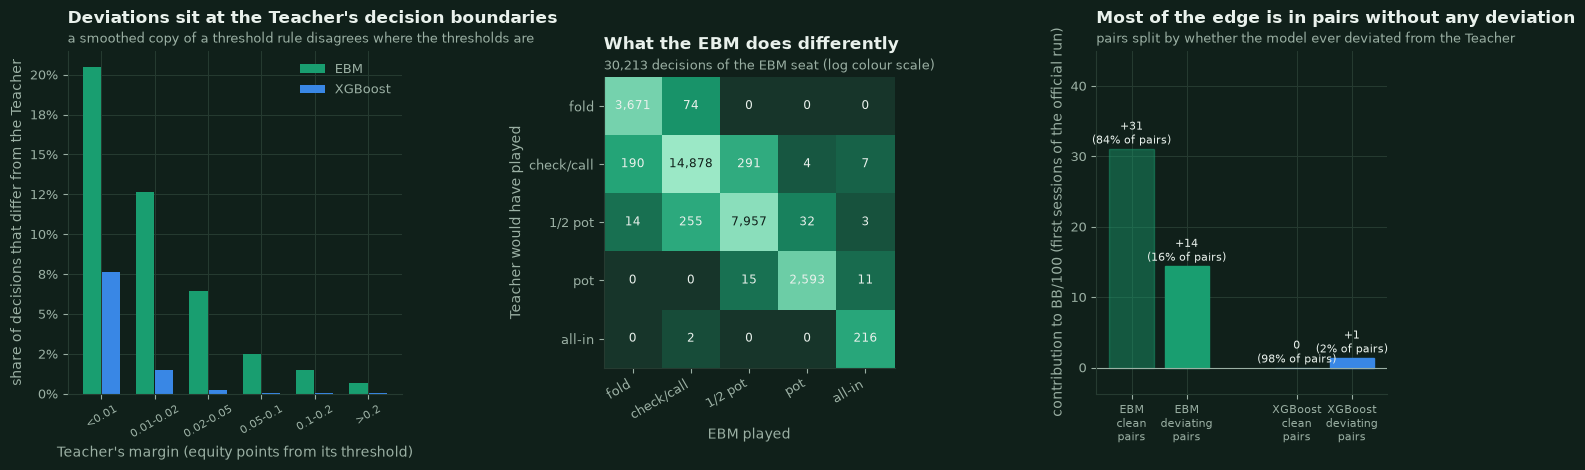

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.8), gridspec_kw={"width_ratios": [1.15, 1, 1]})
ax = axes[0]
edges_m = [0, 0.01, 0.02, 0.05, 0.1, 0.2, 10]
labels_m = ["<0.01", "0.01-0.02", "0.02-0.05", "0.05-0.1", "0.1-0.2", ">0.2"]
for name, offset in (("EBM", -0.18), ("XGBoost", 0.18)):
    log = DECISIONS_LOG[name]
    rate = log.groupby(pd.cut(log["margin"], edges_m, labels=labels_m, include_lowest=True), observed=False)["deviates"].mean()
    ax.bar(np.arange(len(rate)) + offset, rate.to_numpy(), width=0.34, color=AGENT_COLORS[name], label=name)
ax.set_xticks(range(len(labels_m)), labels_m, fontsize=8, rotation=30)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Teacher's margin (equity points from its threshold)")
ax.set_ylabel("share of decisions that differ from the Teacher")
ax.legend()
nbp.title(ax, "Deviations sit at the Teacher's decision boundaries", "a smoothed copy of a threshold rule disagrees where the thresholds are")
ax = axes[1]
image = ax.imshow(np.log10(confusion.to_numpy() + 1), cmap=nbp.SEQUENTIAL)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{confusion.iloc[i, j]:,}", ha="center", va="center", fontsize=8.6, color=nbp.TEXT if confusion.iloc[i, j] < confusion.to_numpy().max() * 0.3 else nbp.SURFACE)
ax.set_xticks(range(5), ACTION_SHORT, rotation=30, ha="right")
ax.set_yticks(range(5), ACTION_SHORT)
ax.set_xlabel("EBM played")
ax.set_ylabel("Teacher would have played")
ax.grid(False)
nbp.title(ax, "What the EBM does differently", f"{len(ebm_log):,} decisions of the EBM seat (log colour scale)")
ax = axes[2]
for k, name in enumerate(("EBM", "XGBoost")):
    for j, flag in enumerate((False, True)):
        share, contribution, mean_pair, se_pair = account[name, flag]
        ax.bar(k * 3 + j, contribution, color=AGENT_COLORS[name], alpha=1.0 if flag else 0.45, width=0.8, edgecolor=AGENT_COLORS[name])
        ax.annotate(f"{'0' if abs(contribution) < 0.5 else format(contribution, '+.0f')}\n({pct(share)} of pairs)", (k * 3 + j, contribution), xytext=(0, 4 if contribution >= -0.5 else -24), textcoords="offset points", ha="center", fontsize=8, color=nbp.TEXT)
ax.set_xticks([0, 1, 3, 4], ["EBM\nclean\npairs", "EBM\ndeviating\npairs", "XGBoost\nclean\npairs", "XGBoost\ndeviating\npairs"], fontsize=8)
ax.set_ylim(min(-0.12 * max(clean[1], dirty[1]), -3), 1.45 * max(clean[1], dirty[1], 1))
ax.axhline(0, color=nbp.MUTED, linewidth=0.8)
ax.set_ylabel("contribution to BB/100 (first sessions of the official run)")
nbp.title(ax, "Most of the edge is in pairs without any deviation" if clean[1] > dirty[1] else "Most of the edge is in pairs with a deviation", "pairs split by whether the model ever deviated from the Teacher")
fig.tight_layout()
nbp.savefig("nb04_ebm_vs_teacher_deviations", fig)
plt.show()

**A concrete deviation `[replay]`.** The most frequent kind of EBM deviation on the flop is "the Teacher would check or call, the EBM bets or raises half the pot". The cell replays one such hand exactly - the one whose result is closest to the *median* result of all hands that contain such a deviation (not the best one) - and asks all four agents about the deviating decision:

In [45]:
log = DECISIONS_LOG["EBM"]
profit_of = HAND_LOG["EBM"].set_index(["session", "hand"])["profit_bb"]
kind = log[(log["street"] == 1) & (log["teacher"] == 1) & (log["own"] == 2)].drop_duplicates(["session", "layout_hand"]).copy()
kind["profit_bb"] = [profit_of[(s, h)] for s, h in zip(kind["session"], kind["layout_hand"])]
median_profit = float(kind["profit_bb"].median())
pick = kind.iloc[int(np.argmin(np.abs(kind["profit_bb"].to_numpy() - median_profit)))]
hand_index = int(pick["session"]) * OFFICIAL_CFG.session_hands + int(pick["layout_hand"])
record4, steps4 = replay_official_hand("EBM", "Teacher", hand_index)
assert abs(record4.result.payoffs[0] / GAME.big_blind - pick["profit_bb"]) < 1e-9, "the replay must reproduce the logged result"
reference_policy = TeacherPolicy()
deviating = next(s for s in steps4 if s[0] == 0 and s[2].abstract.name == "RAISE_SMALL" and s[1].street == Street.FLOP and int(reference_policy.decide(s[1]).action) == 1)
display(Markdown(
    f"### Hand 4 - a typical flop deviation of the EBM (official session {int(pick['session'])}, layout hand {int(pick['layout_hand'])}: deal {int(pick['hand'])} at table {int(pick['table'])}) `[replay]`\n\n"
    f"{len(kind)} hands in the replayed sessions contain a flop decision of this form; they have a mean result of {kind['profit_bb'].mean():+.2f} ± {kind['profit_bb'].std(ddof=1) / np.sqrt(len(kind)):.2f} BB for the EBM (median {median_profit:+.1f}) - "
    f"far too noisy to say anything about the quality of such deviations. The hand shown is the one closest to the median."
))
display(hand_story(record4, ("EBM", "Teacher")))
table, answers = panel_table(deviating[1])
display(Markdown(f"At the deviating decision (hand {pretty(deviating[1].my_hole)}, board {pretty(deviating[1].board)}, pot {deviating[1].pot}) the four agents answer as follows (the EBM row is what was played, the Teacher row what it would have played):"))
display(table)

### Hand 4 - a typical flop deviation of the EBM (official session 0, layout hand 153: deal 76 at table 1) `[replay]`

160 hands in the replayed sessions contain a flop decision of this form; they have a mean result of +3.04 ± 1.90 BB for the EBM (median +2.0) - far too noisy to say anything about the quality of such deviations. The hand shown is the one closest to the median.

**EBM** holds 5♥ A♠, **Teacher** holds 3♠ Q♥; board 9♣ 4♦ 9♠. Result: EBM +2 BB, Teacher -2 BB (no showdown).

| street | board | pot | player | action | abstract | all-in |
|---|---|---|---|---|---|---|
| preflop | - | 15 | Teacher (button) | raise 15 | raise 1/2 pot |  |
| preflop | - | 30 | EBM (big blind) | call 10 | check/call |  |
| flop | 9♣ 4♦ 9♠ | 40 | EBM (big blind) | bet 20 | raise 1/2 pot |  |
| flop | 9♣ 4♦ 9♠ | 60 | Teacher (button) | fold | fold |  |

At the deviating decision (hand 5♥ A♠, board 9♣ 4♦ 9♠, pot 40) the four agents answer as follows (the EBM row is what was played, the Teacher row what it would have played):

| agent | would play | explanation type | explanation |
|---|---|---|---|
| EBM | raise 1/2 pot | top contributions to the chosen action's log-odds | `equity` = 0.56 (+2.16); `equity_minus_pot_odds` = 0.56 (+1.71); `opp_raised_this_street` = 0.00 (+1.27); `board_straightness` = 1.00 (+0.75) |
| XGBoost | check/call | top contributions to the chosen action's log-odds | `opp_fold_to_bet` = 0.43 (+1.91); `pot_odds` = 0.00 (+0.90); `opp_aggression` = 0.86 (+0.64); `i_have_initiative` = 0.00 (+0.60) |
| GA | raise pot | rule trace | flop: equity 0.60 => adjusted 0.55 (+0.00 position, -0.06 deep stacks); weak hand, coin 0.02 < bluff probability 0.04 => bluff (pot-size). |
| Teacher | check/call | rule trace | Check: equity 56% is below the 58% value line and no bluff applies. |

### 9.3 Controlled experiments `[fresh]`

All experiments below are the same kind of match: a **Variant** against the canonical **Teacher**, `CONTROL_SESSIONS` sessions of 200 hands, master seed `CONTROL_SEED` (namespace `eval`), *the same deals for every
variant* (the deals depend only on the two labels), and the official **two-table** protocol (every session = two independent tables on the same deals, section 2). The order-balancing workaround of the first version of this notebook is not needed any more: the protocol itself has no first-mover advantage.
Intervals are session-level t-intervals as everywhere. What differs is only *who the Variant is*:

* **Reference**: a second, identical Teacher (A/A) - what "no difference" looks like in this protocol. Under two tables it is not just *close* to 0: two deterministic copies mirror each other, so it is exactly 0 with a zero-width interval (section 6.2).
* **The imitators**: the EBM and the XGBoost agent themselves.
* **Random deviations**: the Teacher, but with probability `eps` it plays a uniformly random legal action instead (`MixedPolicyAgent`, the package's exploration wrapper). If "any imperfect copy beats the Teacher" were true, these copies should win.
* **Adaptation switched off**: an agent is shown the neutral prior instead of the opponent statistics (`SeesLess`, alpha = 0). A cell "X blind vs Teacher blind" is a *static* game: both are stateless functions of the observation.
* **A Teacher that under-reacts**: the Teacher with its opponent statistics shrunk towards the prior by `alpha` (1 = canonical, 0 = blind), and a Teacher blind to *one* statistic only.
* **A larger static game**: the two static-game rows are repeated with `STATIC_SESSIONS` sessions on other deals (`STATIC_SEED`), because a static game has a small variance and the question "is the EBM simply a better fixed strategy?" deserves a tighter interval.

Every Variant is wrapped (outermost) in the `ShadowAgent` of 9.2, so its **realized agreement with the canonical Teacher** on the observations it really faced is measured too.

In [46]:
class StatsLogger(Agent):
    """Logs the post-flop opponent statistics that its owner sees at every decision (``role`` names the owner); changes nothing."""

    architecture = "logger"

    def __init__(self, inner: Agent, role: str) -> None:
        self.inner, self.role, self.rows = inner, role, []

    def reset(self, seed: int | None = None) -> None:
        self.inner.reset(seed)
        self.rows = []

    def act(self, obs):
        if obs.street != Street.PREFLOP:
            s = obs.opponent_stats
            self.rows.append(("stats", self.role, s.aggression, s.fold_to_bet))
        return self.inner.act(obs)

    def end_hand(self, summary) -> None:
        self.inner.end_hand(summary)


def noisy_teacher(eps: float) -> Agent:
    return MixedPolicyAgent(create_agent("teacher"), create_agent("random"), eps, f"Teacher+{eps:.0%} noise")


blind = lambda make: (lambda: SeesLess(make(), 0.0))  # noqa: E731
logged_teacher = lambda: StatsLogger(make_teacher(), "teacher")  # noqa: E731 - the canonical Teacher, logging what it believes about its opponent
shadowed = lambda make: (lambda: ShadowAgent(make()))  # noqa: E731

CONTROLS = {  # name -> (group, hero factory, opponent factory); the hero is always called "Variant"
    "Teacher copy (A/A)": ("reference", lambda: ShadowAgent(StatsLogger(make_teacher(), "variant")), logged_teacher),
    "Teacher blind copy (A/A)": ("reference", shadowed(blind(make_teacher)), blind(make_teacher)),
    "EBM": ("imitators", lambda: ShadowAgent(StatsLogger(make_ebm(), "variant")), logged_teacher),
    "XGBoost": ("imitators", lambda: ShadowAgent(StatsLogger(make_xgb(), "variant")), logged_teacher),
    **{f"Teacher + {eps:.0%} random actions": ("random deviations", (lambda e=eps: ShadowAgent(noisy_teacher(e))), make_teacher) for eps in (0.01, 0.03, 0.10)},
    "EBM blind vs Teacher blind": ("adaptation off", shadowed(blind(make_ebm)), blind(make_teacher)),
    "XGBoost blind vs Teacher blind": ("adaptation off", shadowed(blind(make_xgb)), blind(make_teacher)),
    "EBM sees vs Teacher blind": ("adaptation off", shadowed(make_ebm), blind(make_teacher)),
    "XGBoost sees vs Teacher blind": ("adaptation off", shadowed(make_xgb), blind(make_teacher)),
    "Teacher sees vs Teacher blind": ("adaptation off", shadowed(make_teacher), blind(make_teacher)),
    "EBM blind vs Teacher sees": ("adaptation off", shadowed(blind(make_ebm)), make_teacher),
    "EBM vs Teacher blind to aggression": ("adaptation grid", shadowed(make_ebm), lambda: SeesLess(make_teacher(), 0.0, ("aggression",))),
    "Teacher copy vs Teacher blind to aggression": ("adaptation grid", shadowed(make_teacher), lambda: SeesLess(make_teacher(), 0.0, ("aggression",))),
    "EBM vs Teacher that sees only aggression": ("adaptation grid", shadowed(make_ebm), lambda: SeesLess(make_teacher(), 0.0, tuple(c for c in OPPONENT_CHANNELS if c != "aggression"))),
    "Teacher copy vs Teacher that sees only aggression": ("adaptation grid", shadowed(make_teacher), lambda: SeesLess(make_teacher(), 0.0, tuple(c for c in OPPONENT_CHANNELS if c != "aggression"))),
    **{f"Teacher with statistics x{alpha:g}": ("damped Teacher", (lambda a=alpha: ShadowAgent(SeesLess(make_teacher(), a))), make_teacher) for alpha in (0.9, 0.75, 0.5, 0.0)},
    **{f"Teacher blind to {channel}": ("one statistic", (lambda c=channel: ShadowAgent(SeesLess(make_teacher(), 0.0, (c,)))), make_teacher) for channel in ("aggression", "pfr", "fold_to_bet")},
}
started = time.perf_counter()
CONTROL_RUNS = run_experiments(
    {name: dict(factories={"Variant": hero, "Teacher": opponent}, hero="Variant", opponent="Teacher", seed=CONTROL_SEED, sessions=CONTROL_SESSIONS) for name, (_, hero, opponent) in CONTROLS.items()}
)
control_seconds = time.perf_counter() - started
CONTROL_GROUP = {name: group for name, (group, _, _) in CONTROLS.items()}
CONTROL_HANDS = sum(len(r.sessions) * OFFICIAL_CFG.session_hands for r in CONTROL_RUNS.values())
started = time.perf_counter()
STATIC_RUNS = run_experiments(
    {
        f"{name} (larger sample)": dict(factories={"Variant": hero, "Teacher": opponent}, hero="Variant", opponent="Teacher", seed=STATIC_SEED, sessions=STATIC_SESSIONS)
        for name, hero, opponent in (("EBM blind vs Teacher blind", shadowed(blind(make_ebm)), blind(make_teacher)), ("XGBoost blind vs Teacher blind", shadowed(blind(make_xgb)), blind(make_teacher)))
    }
)
static_seconds = time.perf_counter() - started
CONTROL_RUNS |= STATIC_RUNS
CONTROL_GROUP |= {name: "adaptation off, larger sample" for name in STATIC_RUNS}


def agreement(run: CustomRun) -> float:
    rows = [r for r in run.rows if r[2] == "shadow"]
    return float(np.mean([r[6] == r[7] for r in rows])) if rows else float("nan")  # row = (session, table, "shadow", hand, street, button, own action, Teacher's action, ...)


def perceived(run: CustomRun, role: str, statistic: str) -> float:
    column = {"aggression": 4, "fold_to_bet": 5}[statistic]  # row = (session, table, "stats", role, aggression, fold_to_bet)
    values = [r[column] for r in run.rows if r[2] == "stats" and r[3] == role]
    return float(np.mean(values)) if values else float("nan")


rows = []
for name, run in CONTROL_RUNS.items():
    e = run.estimate
    rows.append(
        {"experiment (Variant vs canonical Teacher unless stated)": f"`{name}`", "group": CONTROL_GROUP[name], "sessions": e.n, "BB/100 [95% CI]": ci_text(e.mean, e.ci_low, e.ci_high, 0),
         "verdict for the Variant": verdict_word(e.ci_low, e.ci_high), "agrees with the Teacher": pct(agreement(run), 1) if not np.isnan(agreement(run)) else "-"}
    )  # fmt: skip
display(md_table(pd.DataFrame(rows)))
display(Markdown(
    f"**[fresh]** {control_seconds:.0f} s, {CONTROL_HANDS:,} hands in {len(CONTROLS)} experiments on the same deals (seed {CONTROL_SEED}); plus {static_seconds:.0f} s for the {len(STATIC_RUNS)} larger static-game experiments ({STATIC_SESSIONS} sessions each, seed {STATIC_SEED}, other deals)."
))

| experiment (Variant vs canonical Teacher unless stated) | group | sessions | BB/100 [95% CI] | verdict for the Variant | agrees with the Teacher |
|---|---|---|---|---|---|
| `Teacher copy (A/A)` | reference | 50 | +0 [+0, +0] | no significant difference | 100.0% |
| `Teacher blind copy (A/A)` | reference | 50 | +0 [+0, +0] | no significant difference | 91.5% |
| `EBM` | imitators | 50 | +28 [+4, +51] | wins | 96.8% |
| `XGBoost` | imitators | 50 | -1 [-9, +7] | no significant difference | 99.7% |
| `Teacher + 1% random actions` | random deviations | 50 | +13 [+2, +24] | wins | 99.1% |
| `Teacher + 3% random actions` | random deviations | 50 | -1 [-18, +16] | no significant difference | 97.7% |
| `Teacher + 10% random actions` | random deviations | 50 | -39 [-68, -10] | loses | 92.1% |
| `EBM blind vs Teacher blind` | adaptation off | 50 | +7 [-1, +15] | no significant difference | 88.5% |
| `XGBoost blind vs Teacher blind` | adaptation off | 50 | +2 [-2, +7] | no significant difference | 91.6% |
| `EBM sees vs Teacher blind` | adaptation off | 50 | -106 [-138, -74] | loses | 95.7% |
| `XGBoost sees vs Teacher blind` | adaptation off | 50 | -119 [-152, -87] | loses | 99.7% |
| `Teacher sees vs Teacher blind` | adaptation off | 50 | -124 [-157, -91] | loses | 100.0% |
| `EBM blind vs Teacher sees` | adaptation off | 50 | +152 [+119, +186] | wins | 93.2% |
| `EBM vs Teacher blind to aggression` | adaptation grid | 50 | -108 [-140, -75] | loses | 95.7% |
| `Teacher copy vs Teacher blind to aggression` | adaptation grid | 50 | -128 [-160, -96] | loses | 100.0% |
| `EBM vs Teacher that sees only aggression` | adaptation grid | 50 | -8 [-26, +9] | no significant difference | 96.7% |
| `Teacher copy vs Teacher that sees only aggression` | adaptation grid | 50 | -44 [-62, -26] | loses | 100.0% |
| `Teacher with statistics x0.9` | damped Teacher | 50 | +38 [+20, +56] | wins | 99.1% |
| `Teacher with statistics x0.75` | damped Teacher | 50 | +63 [+46, +80] | wins | 97.8% |
| `Teacher with statistics x0.5` | damped Teacher | 50 | +115 [+91, +140] | wins | 96.0% |
| `Teacher with statistics x0` | damped Teacher | 50 | +124 [+91, +157] | wins | 92.8% |
| `Teacher blind to aggression` | one statistic | 50 | +128 [+96, +160] | wins | 97.5% |
| `Teacher blind to pfr` | one statistic | 50 | +44 [+23, +66] | wins | 98.6% |
| `Teacher blind to fold_to_bet` | one statistic | 50 | -0 [-15, +15] | no significant difference | 97.7% |
| `EBM blind vs Teacher blind (larger sample)` | adaptation off, larger sample | 200 | +3 [-2, +7] | no significant difference | 88.5% |
| `XGBoost blind vs Teacher blind (larger sample)` | adaptation off, larger sample | 200 | +2 [-1, +5] | no significant difference | 91.5% |

**[fresh]** 151 s, 240,000 hands in 24 experiments on the same deals (seed 777); plus 66 s for the 2 larger static-game experiments (200 sessions each, seed 778, other deals).

**What does the Teacher believe about its opponent?** The Teacher's call decision depends on one smoothed statistic of its opponent, the post-flop **aggression** (bets + raises)/(bets + raises + calls) (section 8, hand 1). The three experiments with logging
record what each seat believed on average (post-flop decisions, all sessions pooled). *If a copy of the Teacher looks to the Teacher as aggressive as the EBM does, the EBM gains nothing from this channel.*

In [47]:
perception_rows = []
for name in ("Teacher copy (A/A)", "EBM", "XGBoost"):
    run = CONTROL_RUNS[name]
    perception_rows.append(
        {"Variant": f"`{name}`", "Teacher's belief about the Variant: aggression": f"{perceived(run, 'teacher', 'aggression'):.3f}", "Teacher's belief: fold-to-bet": f"{perceived(run, 'teacher', 'fold_to_bet'):.3f}",
         "Variant's belief about the Teacher: aggression": f"{perceived(run, 'variant', 'aggression'):.3f}", "Variant's belief: fold-to-bet": f"{perceived(run, 'variant', 'fold_to_bet'):.3f}"}
    )  # fmt: skip
display(md_table(pd.DataFrame(perception_rows)))
GAP = perceived(CONTROL_RUNS["EBM"], "teacher", "aggression") - perceived(CONTROL_RUNS["Teacher copy (A/A)"], "teacher", "aggression")
display(Markdown(
    f"**[fresh]** The neutral prior of every tracker is {NEUTRAL_STATS.aggression:.2f}. The Teacher believes the EBM to be **{GAP:+.3f}** more aggressive than it believes an identical Teacher copy to be "
    f"({perceived(CONTROL_RUNS['EBM'], 'teacher', 'aggression'):.3f} vs {perceived(CONTROL_RUNS['Teacher copy (A/A)'], 'teacher', 'aggression'):.3f}); for XGBoost the difference is "
    f"{perceived(CONTROL_RUNS['XGBoost'], 'teacher', 'aggression') - perceived(CONTROL_RUNS['Teacher copy (A/A)'], 'teacher', 'aggression'):+.3f}. With the Teacher's `aggression_slope` of {TeacherParams().aggression_slope} the range penalty it applies when facing a bet is {TeacherParams().aggression_slope * GAP:.3f} equity points {'smaller' if GAP > 0 else 'larger'} against the EBM than against a copy of itself. "
    + ("The Teacher therefore reads the EBM as the more aggressive player and defends lighter against it; section 7 shows the style statistics behind this." if GAP > 0.01 else "The two beliefs are nearly the same, so this channel can hardly explain a difference.")
))

| Variant | Teacher's belief about the Variant: aggression | Teacher's belief: fold-to-bet | Variant's belief about the Teacher: aggression | Variant's belief: fold-to-bet |
|---|---|---|---|---|
| `Teacher copy (A/A)` | 0.677 | 0.347 | 0.677 | 0.347 |
| `EBM` | 0.703 | 0.361 | 0.656 | 0.336 |
| `XGBoost` | 0.678 | 0.348 | 0.676 | 0.347 |

**[fresh]** The neutral prior of every tracker is 0.40. The Teacher believes the EBM to be **+0.025** more aggressive than it believes an identical Teacher copy to be (0.703 vs 0.677); for XGBoost the difference is +0.001. With the Teacher's `aggression_slope` of 0.8 the range penalty it applies when facing a bet is 0.020 equity points smaller against the EBM than against a copy of itself. The Teacher therefore reads the EBM as the more aggressive player and defends lighter against it; section 7 shows the style statistics behind this.

**Necessary and sufficient?** The cleanest causal handle is the *other* seat. Put the EBM and, as the yardstick, an identical Teacher copy against a Teacher that is (a) the canonical one, (b) blind to the aggression
statistic only, (c) able to see *only* the aggression statistic, (d) blind to everything. All eight runs use the same deals, so the EBM's advantage over the copy is a **paired** difference per session. If the EBM's edge needs the
Teacher to read its statistics, it must disappear in (d); if the aggression statistic is what matters, it must disappear in (b) and survive in (c).

In [48]:
GRID_OPPONENTS = {
    "canonical Teacher (sees every statistic)": ("EBM", "Teacher copy (A/A)"),
    "Teacher blind to aggression only": ("EBM vs Teacher blind to aggression", "Teacher copy vs Teacher blind to aggression"),
    "Teacher that sees aggression only": ("EBM vs Teacher that sees only aggression", "Teacher copy vs Teacher that sees only aggression"),
    "Teacher blind to every statistic": ("EBM sees vs Teacher blind", "Teacher sees vs Teacher blind"),
}
rows, GRID = [], {}
for opponent_name, (ebm_key, copy_key) in GRID_OPPONENTS.items():
    ebm_run, copy_run = CONTROL_RUNS[ebm_key], CONTROL_RUNS[copy_key]
    difference = ebm_run.sessions - copy_run.sessions  # same deals, same session index: paired
    e_ebm, e_copy, e_diff = ebm_run.estimate, copy_run.estimate, t_estimate(difference, unit="session")
    GRID[opponent_name] = (e_ebm, e_copy, e_diff)
    rows.append(
        {"the Teacher on the other side is ...": opponent_name, "EBM": ci_text(e_ebm.mean, e_ebm.ci_low, e_ebm.ci_high), "Teacher copy": ci_text(e_copy.mean, e_copy.ci_low, e_copy.ci_high),
         "EBM minus copy (paired by session)": ci_text(e_diff.mean, e_diff.ci_low, e_diff.ci_high) + f" - {verdict_word(e_diff.ci_low, e_diff.ci_high).replace('wins', 'EBM better').replace('loses', 'copy better')}"}
    )  # fmt: skip
display(md_table(pd.DataFrame(rows)))

| the Teacher on the other side is ... | EBM | Teacher copy | EBM minus copy (paired by session) |
|---|---|---|---|
| canonical Teacher (sees every statistic) | +28 [+4, +51] | +0 [+0, +0] | +28 [+4, +51] - EBM better |
| Teacher blind to aggression only | -108 [-140, -75] | -128 [-160, -96] | +20 [+10, +30] - EBM better |
| Teacher that sees aggression only | -8 [-26, +9] | -44 [-62, -26] | +36 [+16, +55] - EBM better |
| Teacher blind to every statistic | -106 [-138, -74] | -124 [-157, -91] | +18 [+7, +29] - EBM better |

**Whose use of the statistics matters?** The grid changes what the *Teacher on the other side* may see. The EBM's own use of the statistics can be switched off as well, which gives a 2 x 2 design: the EBM sees / is blind, the Teacher it plays sees / is blind. In each cell the EBM is compared with an **identical copy of the Teacher in the same situation**
(same deals, same opponent, paired by session). The difference between the two cells of a row is an **interaction contrast**: how much larger the EBM's advantage is because the Teacher on the other side reads statistics. If the Teacher's reading of the EBM were the whole story, the advantage
would be 0 in both cells of the right-hand column and the interaction would equal the full edge.

In [49]:
paired_diff = lambda run, copy: CONTROL_RUNS[run].sessions - (CONTROL_RUNS[copy].sessions if copy else 0.0)  # noqa: E731
CELLS = {  # (EBM, Teacher opponent) -> EBM minus an identical Teacher copy in the same situation, per session
    ("sees", "sees"): paired_diff("EBM", "Teacher copy (A/A)"),
    ("blind", "sees"): paired_diff("EBM blind vs Teacher sees", "Teacher with statistics x0"),
    ("sees", "blind"): paired_diff("EBM sees vs Teacher blind", "Teacher sees vs Teacher blind"),
    ("blind", "blind"): paired_diff("EBM blind vs Teacher blind", "Teacher blind copy (A/A)"),
}
CELL_E = {key: t_estimate(values, unit="session") for key, values in CELLS.items()}
INTERACTION = {
    "sees": t_estimate(CELLS["sees", "sees"] - CELLS["sees", "blind"], unit="session"),
    "blind": t_estimate(CELLS["blind", "sees"] - CELLS["blind", "blind"], unit="session"),
}
cell_text = lambda e: ci_text(e.mean, e.ci_low, e.ci_high) + (" *" if e.excludes_zero else "")  # noqa: E731
display(md_table(pd.DataFrame(
    [
        {"EBM": "reads statistics" if row == "sees" else "blind to statistics", "Teacher opponent reads statistics (canonical)": cell_text(CELL_E[row, "sees"]),
         "Teacher opponent is blind": cell_text(CELL_E[row, "blind"]), "interaction (reads minus blind)": cell_text(INTERACTION[row])}
        for row in ("sees", "blind")
    ]
)))
LARGE_STATIC = CONTROL_RUNS["EBM blind vs Teacher blind (larger sample)"].estimate
residual_sig = CELL_E["sees", "blind"].ci_low > 0
display(Markdown(
    f"**[fresh]** EBM minus an identical Teacher copy, BB/100 [95% CI over {CONTROL_SESSIONS} sessions of the same deals; `*` = excludes 0]. The advantage is positive in {sum(e.mean > 0 for e in CELL_E.values())} of the four cells and its interval excludes 0 in {sum(e.excludes_zero for e in CELL_E.values())}. "
    f"With the Teacher blind to every statistic it is {ci_text(CELL_E['sees', 'blind'].mean, CELL_E['sees', 'blind'].ci_low, CELL_E['sees', 'blind'].ci_high)} (EBM reading statistics) and {ci_text(CELL_E['blind', 'blind'].mean, CELL_E['blind', 'blind'].ci_low, CELL_E['blind', 'blind'].ci_high)} (static game); "
    f"the static game on {STATIC_SESSIONS} other sessions gives {ci_text(LARGE_STATIC.mean, LARGE_STATIC.ci_low, LARGE_STATIC.ci_high)} and the XGBoost version {ci_text(CONTROL_RUNS['XGBoost blind vs Teacher blind (larger sample)'].estimate.mean, CONTROL_RUNS['XGBoost blind vs Teacher blind (larger sample)'].estimate.ci_low, CONTROL_RUNS['XGBoost blind vs Teacher blind (larger sample)'].estimate.ci_high)}. "
    f"The interaction - the part of the edge that exists only because the Teacher reads statistics - is {ci_text(INTERACTION['sees'].mean, INTERACTION['sees'].ci_low, INTERACTION['sees'].ci_high)} when the EBM reads statistics and {ci_text(INTERACTION['blind'].mean, INTERACTION['blind'].ci_low, INTERACTION['blind'].ci_high)} when it does not. "
    + ("**Closing the Teacher's reading channel does not remove the edge**: a residual advantage remains that does not need the Teacher to read anything about the EBM."
       if residual_sig else "**Closing the Teacher's reading channel removes the edge** (its interval no longer excludes 0).")
))

| EBM | Teacher opponent reads statistics (canonical) | Teacher opponent is blind | interaction (reads minus blind) |
|---|---|---|---|
| reads statistics | +28 [+4, +51] * | +18 [+7, +29] * | +10 [-17, +37] |
| blind to statistics | +28 [+12, +44] * | +7 [-1, +15] | +21 [+7, +35] * |

**[fresh]** EBM minus an identical Teacher copy, BB/100 [95% CI over 50 sessions of the same deals; `*` = excludes 0]. The advantage is positive in 4 of the four cells and its interval excludes 0 in 3. With the Teacher blind to every statistic it is +18 [+7, +29] (EBM reading statistics) and +7 [-1, +15] (static game); the static game on 200 other sessions gives +3 [-2, +7] and the XGBoost version +2 [-1, +5]. The interaction - the part of the edge that exists only because the Teacher reads statistics - is +10 [-17, +37] when the EBM reads statistics and +21 [+7, +35] when it does not. **Closing the Teacher's reading channel does not remove the edge**: a residual advantage remains that does not need the Teacher to read anything about the EBM.

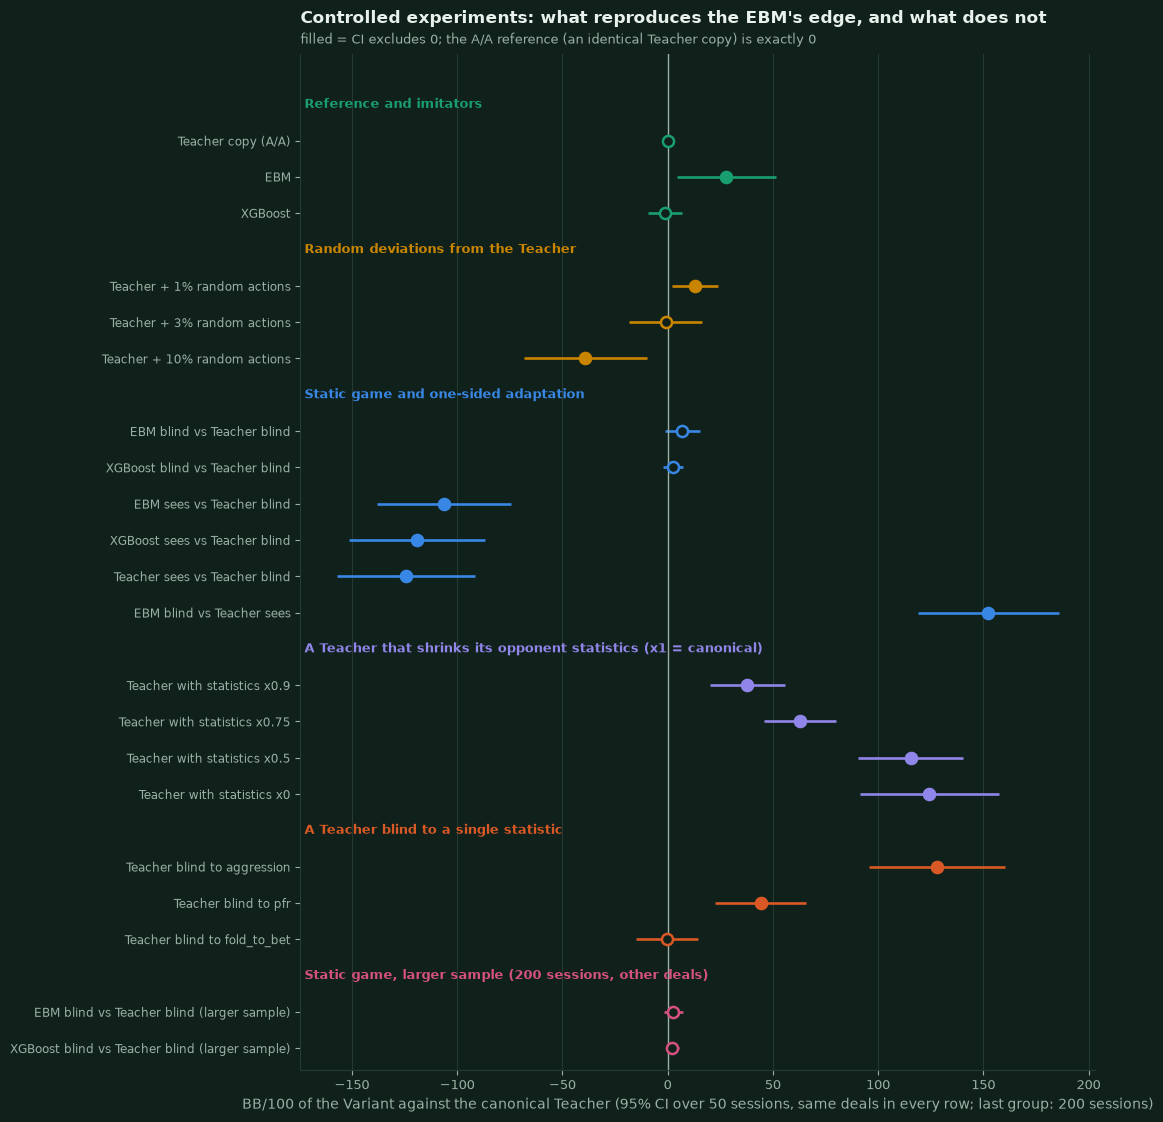

In [50]:
FOREST_GROUPS = [
    ("Reference and imitators", ["Teacher copy (A/A)", "EBM", "XGBoost"]),
    ("Random deviations from the Teacher", [f"Teacher + {eps:.0%} random actions" for eps in (0.01, 0.03, 0.10)]),
    ("Static game and one-sided adaptation", ["EBM blind vs Teacher blind", "XGBoost blind vs Teacher blind", "EBM sees vs Teacher blind", "XGBoost sees vs Teacher blind", "Teacher sees vs Teacher blind", "EBM blind vs Teacher sees"]),
    ("A Teacher that shrinks its opponent statistics (x1 = canonical)", [f"Teacher with statistics x{alpha:g}" for alpha in (0.9, 0.75, 0.5, 0.0)]),
    ("A Teacher blind to a single statistic", [f"Teacher blind to {channel}" for channel in ("aggression", "pfr", "fold_to_bet")]),
    (f"Static game, larger sample ({STATIC_SESSIONS} sessions, other deals)", ["EBM blind vs Teacher blind (larger sample)", "XGBoost blind vs Teacher blind (larger sample)"]),
]
GROUP_COLOR = {title: color for (title, _), color in zip(FOREST_GROUPS, (nbp.SERIES[0], nbp.SERIES[4], nbp.SERIES[1], nbp.SERIES[3], nbp.SERIES[2], nbp.SERIES[5]))}
n_rows = sum(len(names) for _, names in FOREST_GROUPS) + len(FOREST_GROUPS)
fig, ax = plt.subplots(figsize=(11.2, 0.36 * n_rows + 1.6))
y, ticks, tick_labels = 0.0, [], []
for title, names in FOREST_GROUPS:
    ax.annotate(title, (0.005, y), xycoords=("axes fraction", "data"), ha="left", va="center", fontsize=9, fontweight="bold", color=GROUP_COLOR[title])
    y += 1
    for name in names:
        e = CONTROL_RUNS[name].estimate
        filled = e.ci_low > 0 or e.ci_high < 0
        ax.hlines(y, e.ci_low, e.ci_high, color=GROUP_COLOR[title], linewidth=1.9)
        ax.plot(e.mean, y, "o", markersize=nbp.MARKER_SIZE, markerfacecolor=GROUP_COLOR[title] if filled else nbp.SURFACE, markeredgecolor=GROUP_COLOR[title], markeredgewidth=1.8, zorder=3)
        ticks.append(y)
        tick_labels.append(name)
        y += 1
ax.set_yticks(ticks, tick_labels, fontsize=8.6)
ax.set_ylim(y - 0.4, -1.4)
ax.axvline(0, color=nbp.MUTED, linewidth=1.0)
aa_estimate = CONTROL_RUNS["Teacher copy (A/A)"].estimate
if aa_estimate.ci_high - aa_estimate.ci_low > 1e-9:
    ax.axvspan(aa_estimate.ci_low, aa_estimate.ci_high, color=nbp.MUTED, alpha=0.13, linewidth=0)
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"BB/100 of the Variant against the canonical Teacher (95% CI over {CONTROL_SESSIONS} sessions, same deals in every row; last group: {STATIC_SESSIONS} sessions)")
ax.set_title("Controlled experiments: what reproduces the EBM's edge, and what does not", loc="left", pad=22)
ax.annotate("filled = CI excludes 0; the A/A reference (an identical Teacher copy) is exactly 0" if aa_estimate.ci_high - aa_estimate.ci_low <= 1e-9 else "shaded band: the A/A reference (an identical Teacher copy); filled = CI excludes 0", (0, 1), xycoords="axes fraction", xytext=(0, 5), textcoords="offset points", color=nbp.MUTED, fontsize=9, va="bottom")  # nbp.title would overlap on a tall panel
fig.tight_layout()
nbp.savefig("nb04_controls", fig)
plt.show()

### 9.4 Does the *size* of the deviation or its *direction* matter? Sensitivity of the three policies to opponent statistics `[fresh]`

The experiments above point at the opponent statistics. A direct, offline check of how each policy *uses* them: take real validation states in which a player faces a bet after the flop (`SENSITIVITY_STATES` random ones), change **one**
opponent statistic from a neutral value to the value of a competent-looking opponent while keeping everything else fixed, and count how often the chosen action changes. The Teacher reads exactly three statistics (post-flop **aggression** when facing a bet,
**fold-to-bet** when betting, **PFR** preflop), so any reaction of a model to the other ones is a *learned artefact*, and a weaker reaction to the one the Teacher does read is a *damped copy* of its rule.

In [51]:
SENSITIVITY_STATES = 5000
VAL = load_validation_frame()
X_ALL = VAL[list(FEATURE_NAMES)].to_numpy(np.float32)
L_ALL = VAL[list(LEGAL_COLUMNS)].to_numpy(bool)
facing_postflop = np.flatnonzero(((VAL["facing_bet"] > 0.5) & (VAL["street"] > 0.5)).to_numpy())
sample = np.random.default_rng(BOOTSTRAP_SEED).choice(facing_postflop, SENSITIVITY_STATES, replace=False)
X_S, L_S = X_ALL[sample], L_ALL[sample]
EBM_AGENT, XGB_AGENT, TEACHER_POLICY = create_agent("ebm"), create_agent("xgboost"), TeacherPolicy()
from poker_arena.agents.xgb_agent import class_probabilities  # noqa: E402


def decide_all(X: np.ndarray, L: np.ndarray) -> dict[str, np.ndarray]:
    """Greedy legal action of the three policies for a batch of feature vectors and legal masks (the agents' own decision rule: masked arg-max)."""
    p_ebm = np.zeros((len(X), 5))
    p_ebm[:, [int(c) for c in EBM_AGENT.model.classes_]] = EBM_AGENT.model.predict_proba(X)
    p_xgb = class_probabilities(XGB_AGENT.booster, X)
    return {
        "Teacher": np.array([int(TEACHER_POLICY.decide_features(x, l).action) for x, l in zip(X, L)]),
        "EBM": np.where(L, p_ebm, -1.0).argmax(axis=1),
        "XGBoost": np.where(L, p_xgb, -1.0).argmax(axis=1),
    }


SENSITIVITY_PROBES = {"aggression": ("opp_aggression", 0.40, 0.65), "fold-to-bet": ("opp_fold_to_bet", 0.40, 0.30), "PFR": ("opp_pfr", 0.30, 0.50)}  # neutral -> competent-looking
sens_rows, SENS = [], {}
for label, (feature, low, high) in SENSITIVITY_PROBES.items():
    decisions = {}
    for value in (low, high):
        X_probe = X_S.copy()
        X_probe[:, FEATURE_INDEX[feature]] = value
        decisions[value] = decide_all(X_probe, L_S)
    for model in ("Teacher", "EBM", "XGBoost"):
        flips = float(np.mean(decisions[low][model] != decisions[high][model]))
        folds_low, folds_high = float(np.mean(decisions[low][model] == 0)), float(np.mean(decisions[high][model] == 0))
        SENS[label, model] = (flips, folds_low, folds_high)
    sens_rows.append(
        {"statistic moved": f"`{feature}` {low:.2f} -> {high:.2f}", **{f"{model}: decisions that change": pct(SENS[label, model][0], 1) for model in ("Teacher", "EBM", "XGBoost")},
         **{f"{model}: fold rate": f"{pct(SENS[label, model][1])} -> {pct(SENS[label, model][2])}" for model in ("Teacher", "EBM", "XGBoost")}}
    )  # fmt: skip
display(md_table(pd.DataFrame(sens_rows)))
base = decide_all(X_S, L_S)
display(Markdown(
    f"**[fresh]** {SENSITIVITY_STATES:,} random validation states of post-flop decisions facing a bet. On the data's own statistics the EBM picks the Teacher's action in {pct(np.mean(base['EBM'] == base['Teacher']), 1)} of them, XGBoost in "
    f"{pct(np.mean(base['XGBoost'] == base['Teacher']), 1)}. Relative to the Teacher, the EBM reacts to the aggression statistic **{SENS['aggression', 'EBM'][0] / SENS['aggression', 'Teacher'][0]:.0%}** as often (XGBoost {SENS['aggression', 'XGBoost'][0] / SENS['aggression', 'Teacher'][0]:.0%}), "
    f"and it reacts to statistics the Teacher ignores in this situation (fold-to-bet: {pct(SENS['fold-to-bet', 'EBM'][0], 1)} of decisions change, PFR {pct(SENS['PFR', 'EBM'][0], 1)}; Teacher {pct(SENS['fold-to-bet', 'Teacher'][0], 1)} / {pct(SENS['PFR', 'Teacher'][0], 1)})."
))

| statistic moved | Teacher: decisions that change | EBM: decisions that change | XGBoost: decisions that change | Teacher: fold rate | EBM: fold rate | XGBoost: fold rate |
|---|---|---|---|---|---|---|
| `opp_aggression` 0.40 -> 0.65 | 16.9% | 14.9% | 16.9% | 81% -> 64% | 80% -> 65% | 81% -> 64% |
| `opp_fold_to_bet` 0.40 -> 0.30 | 0.0% | 1.0% | 0.2% | 48% -> 48% | 50% -> 50% | 48% -> 48% |
| `opp_pfr` 0.30 -> 0.50 | 0.0% | 3.6% | 0.2% | 48% -> 48% | 54% -> 51% | 49% -> 49% |

**[fresh]** 5,000 random validation states of post-flop decisions facing a bet. On the data's own statistics the EBM picks the Teacher's action in 95.8% of them, XGBoost in 99.0%. Relative to the Teacher, the EBM reacts to the aggression statistic **88%** as often (XGBoost 100%), and it reacts to statistics the Teacher ignores in this situation (fold-to-bet: 1.0% of decisions change, PFR 3.6%; Teacher 0.0% / 0.0%).

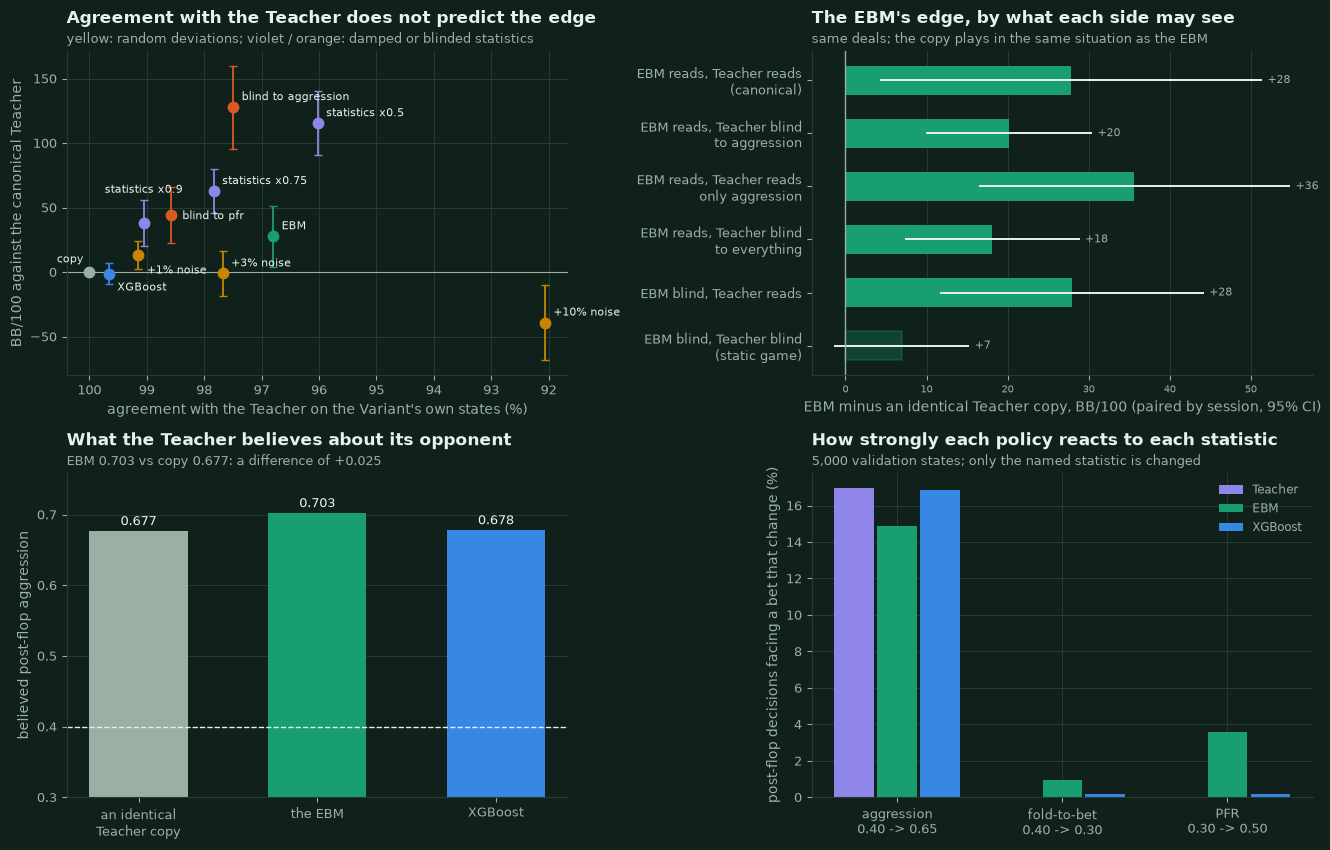

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(13.4, 8.6))
# (a) dose-response: realized agreement with the Teacher vs result
ax = axes[0, 0]
points = {"Teacher copy (A/A)": nbp.MUTED, "EBM": nbp.SERIES[0], "XGBoost": nbp.SERIES[1], "Teacher + 1% random actions": nbp.SERIES[4], "Teacher + 3% random actions": nbp.SERIES[4], "Teacher + 10% random actions": nbp.SERIES[4],
          "Teacher with statistics x0.9": nbp.SERIES[3], "Teacher with statistics x0.75": nbp.SERIES[3], "Teacher with statistics x0.5": nbp.SERIES[3], "Teacher blind to aggression": nbp.SERIES[2], "Teacher blind to pfr": nbp.SERIES[2]}  # fmt: skip
LABEL_OFFSET = {"Teacher copy (A/A)": (-4, 7, "right"), "XGBoost": (6, -12, "left"), "Teacher with statistics x0.9": (0, 22, "center"), "Teacher blind to pfr": (8, -3, "left"), "Teacher + 1% random actions": (6, -13, "left")}
for name, color in points.items():
    run = CONTROL_RUNS[name]
    e = run.estimate
    x = 100 * agreement(run)
    ax.errorbar(x, e.mean, yerr=[[e.mean - e.ci_low], [e.ci_high - e.mean]], fmt="o", color=color, markersize=7.5, capsize=3, linewidth=1.3)
    short = name.replace("Teacher + ", "+").replace(" random actions", " noise").replace("Teacher with statistics ", "statistics ").replace("Teacher blind to ", "blind to ").replace("Teacher copy (A/A)", "copy")
    dx, dy, align = LABEL_OFFSET.get(name, (6, 5, "left"))
    ax.annotate(short, (x, e.mean), xytext=(dx, dy), textcoords="offset points", fontsize=8, color=nbp.TEXT, ha=align)
ax.axhline(0, color=nbp.MUTED, linewidth=0.8)
ax.invert_xaxis()
ax.set_xlabel("agreement with the Teacher on the Variant's own states (%)")
ax.set_ylabel("BB/100 against the canonical Teacher")
nbp.title(ax, "Agreement with the Teacher does not predict the edge", "yellow: random deviations; violet / orange: damped or blinded statistics")
# (b) the EBM's advantage over an identical Teacher copy, by what each side may see
ax = axes[0, 1]
panel_b = {
    "EBM reads, Teacher reads\n(canonical)": CELL_E["sees", "sees"], "EBM reads, Teacher blind\nto aggression": GRID["Teacher blind to aggression only"][2], "EBM reads, Teacher reads\nonly aggression": GRID["Teacher that sees aggression only"][2],
    "EBM reads, Teacher blind\nto everything": CELL_E["sees", "blind"], "EBM blind, Teacher reads": CELL_E["blind", "sees"], "EBM blind, Teacher blind\n(static game)": CELL_E["blind", "blind"],
}  # fmt: skip
nbp.bar_with_ci(ax, list(panel_b), [e.mean for e in panel_b.values()], [e.ci_low for e in panel_b.values()], [e.ci_high for e in panel_b.values()], colors=nbp.SERIES[0], value_format="{:+.0f}")
ax.tick_params(axis="x", labelsize=7.2)
ax.set_xlabel("EBM minus an identical Teacher copy, BB/100 (paired by session, 95% CI)")
nbp.title(ax, "The EBM's edge, by what each side may see", "same deals; the copy plays in the same situation as the EBM")
# (c) beliefs
ax = axes[1, 0]
names = ["Teacher copy (A/A)", "EBM", "XGBoost"]
beliefs = [perceived(CONTROL_RUNS[n], "teacher", "aggression") for n in names]
ax.bar(range(3), beliefs, color=[nbp.MUTED, nbp.SERIES[0], nbp.SERIES[1]], width=0.55)
for i, v in enumerate(beliefs):
    ax.annotate(f"{v:.3f}", (i, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color=nbp.TEXT)
ax.axhline(NEUTRAL_STATS.aggression, color=nbp.TEXT, linestyle="--", linewidth=1.0)
ax.annotate("neutral prior 0.40", (2.45, NEUTRAL_STATS.aggression), xytext=(0, 4), textcoords="offset points", ha="right", fontsize=8.5, color=nbp.TEXT)
ax.set_xticks(range(3), ["an identical\nTeacher copy", "the EBM", "XGBoost"])
ax.set_ylim(0.3, max(beliefs) * 1.08)
ax.grid(axis="x", visible=False)
ax.set_ylabel("believed post-flop aggression")
nbp.title(ax, "What the Teacher believes about its opponent", f"EBM {beliefs[1]:.3f} vs copy {beliefs[0]:.3f}: a difference of {beliefs[1] - beliefs[0]:+.3f}")
# (d) sensitivity
ax = axes[1, 1]
width = 0.26
for k, model in enumerate(("Teacher", "EBM", "XGBoost")):
    ax.bar(np.arange(3) + (k - 1) * width, [100 * SENS[label, model][0] for label in SENSITIVITY_PROBES], width=width * 0.92, color=AGENT_COLORS[model], label=model)
ax.set_xticks(range(3), [f"{label}\n{low:.2f} -> {high:.2f}" for label, (feature, low, high) in SENSITIVITY_PROBES.items()], fontsize=9)
ax.set_ylabel("post-flop decisions facing a bet that change (%)")
ax.legend(fontsize=8.5)
nbp.title(ax, "How strongly each policy reacts to each statistic", f"{SENSITIVITY_STATES:,} validation states; only the named statistic is changed")
fig.tight_layout()
nbp.savefig("nb04_ebm_vs_teacher_mechanism", fig)
plt.show()

### 9.5 Putting the evidence together

The table lists each candidate explanation next to the experiment that could have refuted it, with the numbers (all computed above). "Supported" / "not supported" refer to *these experiments*; none of them is a proof.

In [53]:
ci_of = lambda e: ci_text(e.mean, e.ci_low, e.ci_high)  # noqa: E731
ebm_off = t_estimate(RES.session_profits("EBM", "Teacher"), unit="session")
ebm_rep = [t_estimate(REPLICATION[s, "EBM", "Teacher"].session, unit="session") for s in REPLICATION_SEEDS]
ebm_pooled = t_estimate(np.concatenate([RES.session_profits("EBM", "Teacher"), *(REPLICATION[s, "EBM", "Teacher"].session for s in REPLICATION_SEEDS)]), unit="session")
unselected = [r for r in EBM_META["dagger"] if not r["selected"]]
mine = pool_groups([RES.session_profits("EBM", b) for b in WEAK], weighting="equal", unit="session")
theirs = pool_groups([RES.session_profits("Teacher", b) for b in WEAK], weighting="equal", unit="session")
gap_bots, gap_se = mine.mean - theirs.mean, float(np.hypot(mine.se, theirs.se))
c = CONTROL_RUNS
noise_names = [f"Teacher + {eps:.0%} random actions" for eps in (0.01, 0.03, 0.10)]
noise_est = [c[n].estimate for n in noise_names]
g_canon, g_blind_agg, g_see_agg, g_blind_all = (GRID[k][2] for k in GRID)
cell = CELL_E
static_ebm, static_xgb = (c[f"{m} blind vs Teacher blind (larger sample)"].estimate for m in ("EBM", "XGBoost"))
aggr_ratio = SENS["aggression", "EBM"][0] / SENS["aggression", "Teacher"][0]
fmt = lambda name: ci_text(c[name].estimate.mean, c[name].estimate.ci_low, c[name].estimate.ci_high)  # noqa: E731
BA_EBM = BEFORE_AFTER["EBM", "Teacher"]
no_static_edge = static_ebm.ci_low <= 0 <= static_ebm.ci_high
only_smallest_noise = [e.ci_low > 0 for e in noise_est] == [True, False, False]

evidence = pd.DataFrame(
    [
        ["H1 luck / winner's curse", f"replication on {len(REPLICATION_SEEDS)} new seeds; saved validation of the DAgger rounds the EBM did not keep",
         f"EBM - Teacher: official {ci_of(ebm_off)}; new seeds " + ", ".join(ci_of(e) for e in ebm_rep) + f"; pooled {ci_of(ebm_pooled)}; equality of the three runs p = {HETEROGENEITY['EBM', 'Teacher']:.3f}; "
         f"unselected rounds' point estimates in the saved (legacy-protocol) validation: " + ", ".join(f"{r['policy_validation']['teacher']['bb_per_100']:+.0f}" for r in unselected),
         ("**not supported for the sign** (the pooled edge is clearly positive), **supported for the size**: the official estimate is the largest of the runs, so it probably overstates the edge" if ebm_pooled.ci_low > 0 and ebm_off.mean > max(e.mean for e in ebm_rep)
          else "**not supported** - the edge replicates in size and sign" if ebm_pooled.ci_low > 0 else "**cannot be excluded** - the pooled edge is not resolved")],
        ["H2 generally better", "EBM minus Teacher against the three bots; static game",
         f"bots, equal weight: {ci_text(gap_bots, gap_bots - 1.96 * gap_se, gap_bots + 1.96 * gap_se)}; static game (both blind, {STATIC_SESSIONS} sessions): {ci_of(static_ebm)}",
         "**not supported** - no edge against the bots, none in the static game" if (gap_bots - 1.96 * gap_se <= 0 <= gap_bots + 1.96 * gap_se) and no_static_edge else "**partly supported**"],
        ["H3 any imperfect copy wins", f"random deviations at {pct(agreement(c[noise_names[0]]))}-{pct(agreement(c[noise_names[-1]]))} agreement; XGBoost ({pct(agreement(c['XGBoost']), 1)} agreement)",
         f"A/A reference {fmt('Teacher copy (A/A)')} (exactly 0); noise copies: " + ", ".join(fmt(n) for n in noise_names) + f"; XGBoost {fmt('XGBoost')}",
         ("**not supported** - only the smallest noise level is nominally significant (one of the many rows of this section tested at 5%), the gain does not grow with the noise and the largest noise loses; XGBoost agrees most and does not win. A *systematic* tiny deviation does win (H5): the direction matters, not the size"
          if only_smallest_noise else "**see the table**: the pattern of the noise copies is not the one expected under H3 or its negation; the gain does not follow the amount of noise")],
        ["H4 a better fixed strategy", "both agents blind to opponent statistics (static game)", f"EBM {ci_of(static_ebm)}, XGBoost {ci_of(static_xgb)} ({STATIC_SESSIONS} sessions each; {CONTROL_SESSIONS} sessions on the common deals: EBM {fmt('EBM blind vs Teacher blind')})",
         "**not supported** - with identical information the three play equally well (any difference is smaller than the width of these intervals)" if no_static_edge else "**supported, but small** - the EBM wins the static game"],
        ["H5 less costly use of opponent statistics (adaptation)", "ablation grid, 2 x 2 design, beliefs, sensitivity",
         f"EBM minus a Teacher copy: {ci_of(cell['sees', 'sees'])} (both read statistics), {ci_of(cell['sees', 'blind'])} (Teacher blind), {ci_of(cell['blind', 'sees'])} (EBM blind), {ci_of(cell['blind', 'blind'])} (both blind); "
         f"Teacher blind to aggression only {ci_of(g_blind_agg)}, reading only aggression {ci_of(g_see_agg)}; the Teacher believes the EBM {GAP:+.3f} more aggressive than a copy; the EBM reacts to the aggression statistic {aggr_ratio:.0%} as often as the Teacher, XGBoost {SENS['aggression', 'XGBoost'][0] / SENS['aggression', 'Teacher'][0]:.0%}",
         ("**supported in a broader form than hypothesised**: no edge in the static game, an edge as soon as either side reads statistics; but **no single channel carries it** (it survives a Teacher blind to aggression, or to everything)" if no_static_edge and g_blind_agg.ci_low > 0 and g_blind_all.ci_low > 0
          else "**partly supported** - see the numbers")],
        ["H6 protocol artifact", "A/A tests (6.2); the same deals under the legacy and the corrected protocol (6.5)",
         f"identical Teachers: every pair sums to exactly 0 under two tables (largest {np.max(np.abs(AA_EXACT['pairs'])):.2f} BB), the first-named Teacher loses {-AA_LEGACY['mean']:.1f} ± {AA_LEGACY['se']:.1f} BB/100 under the legacy protocol; "
         f"EBM vs Teacher on the same deals: legacy {ci_text(BA_EBM['legacy'].mean, BA_EBM['legacy'].ci_low, BA_EBM['legacy'].ci_high)} -> corrected {ci_text(BA_EBM['corrected'].mean, BA_EBM['corrected'].ci_low, BA_EBM['corrected'].ci_high)}",
         ("**not an explanation of the edge** - it is present under the corrected protocol, where identical copies cancel exactly; the legacy artifact changed its size (the legacy numbers are not reliable), not its existence"
          if BA_EBM["corrected"].ci_low > 0 else "**cannot be excluded** - the edge is not resolved under the corrected protocol")],
    ],
    columns=["candidate", "experiment", "result", "verdict"],
)
display(md_table(evidence))

| candidate | experiment | result | verdict |
|---|---|---|---|
| H1 luck / winner's curse | replication on 2 new seeds; saved validation of the DAgger rounds the EBM did not keep | EBM - Teacher: official +37 [+27, +47]; new seeds +10 [-2, +23], +26 [+14, +39]; pooled +28 [+21, +34]; equality of the three runs p = 0.004; unselected rounds' point estimates in the saved (legacy-protocol) validation: +106, +37, +15 | **not supported for the sign** (the pooled edge is clearly positive), **supported for the size**: the official estimate is the largest of the runs, so it probably overstates the edge |
| H2 generally better | EBM minus Teacher against the three bots; static game | bots, equal weight: -3 [-30, +23]; static game (both blind, 200 sessions): +3 [-2, +7] | **not supported** - no edge against the bots, none in the static game |
| H3 any imperfect copy wins | random deviations at 99%-92% agreement; XGBoost (99.7% agreement) | A/A reference +0 [+0, +0] (exactly 0); noise copies: +13 [+2, +24], -1 [-18, +16], -39 [-68, -10]; XGBoost -1 [-9, +7] | **not supported** - only the smallest noise level is nominally significant (one of the many rows of this section tested at 5%), the gain does not grow with the noise and the largest noise loses; XGBoost agrees most and does not win. A *systematic* tiny deviation does win (H5): the direction matters, not the size |
| H4 a better fixed strategy | both agents blind to opponent statistics (static game) | EBM +3 [-2, +7], XGBoost +2 [-1, +5] (200 sessions each; 50 sessions on the common deals: EBM +7 [-1, +15]) | **not supported** - with identical information the three play equally well (any difference is smaller than the width of these intervals) |
| H5 less costly use of opponent statistics (adaptation) | ablation grid, 2 x 2 design, beliefs, sensitivity | EBM minus a Teacher copy: +28 [+4, +51] (both read statistics), +18 [+7, +29] (Teacher blind), +28 [+12, +44] (EBM blind), +7 [-1, +15] (both blind); Teacher blind to aggression only +20 [+10, +30], reading only aggression +36 [+16, +55]; the Teacher believes the EBM +0.025 more aggressive than a copy; the EBM reacts to the aggression statistic 88% as often as the Teacher, XGBoost 100% | **supported in a broader form than hypothesised**: no edge in the static game, an edge as soon as either side reads statistics; but **no single channel carries it** (it survives a Teacher blind to aggression, or to everything) |
| H6 protocol artifact | A/A tests (6.2); the same deals under the legacy and the corrected protocol (6.5) | identical Teachers: every pair sums to exactly 0 under two tables (largest 0.00 BB), the first-named Teacher loses 13.2 ± 3.0 BB/100 under the legacy protocol; EBM vs Teacher on the same deals: legacy +69 [+41, +97] -> corrected +38 [+21, +55] | **not an explanation of the edge** - it is present under the corrected protocol, where identical copies cancel exactly; the legacy artifact changed its size (the legacy numbers are not reliable), not its existence |

### 9.6 Conclusions of the investigation

In [54]:
noise_means = [e.mean for e in noise_est]
_share = ends["EBM"]["showdown"] / ends["EBM"].sum()
SHOWDOWN_TEXT = (f"It is a **showdown edge**: over all 200 official sessions the hands that reach showdown contribute {ends['EBM']['showdown']:+.1f} BB/100 of the {ends['EBM'].sum():+.1f} in total, hands that end with a flop fold {ends['EBM']['flop']:+.1f} (section 9.2)."
                 if _share > 0.5 else f"Only {_share:.0%} of it comes from hands that reach showdown (section 9.2).")
H6_TEXT = (f"The EBM-Teacher estimate on the same deals moves from {BA_EBM['legacy'].mean:+.0f} (legacy) to {BA_EBM['corrected'].mean:+.0f} BB/100 (corrected); the edge itself is {'still resolved' if BA_EBM['corrected'].ci_low > 0 else 'no longer resolved'} under the corrected protocol, so the legacy artifact is not what produced it.")
belief_ebm, belief_copy = perceived(c["EBM"], "teacher", "aggression"), perceived(c["Teacher copy (A/A)"], "teacher", "aggression")
display(Markdown(f"""
**Empirical findings.**

1. The EBM's edge over the Teacher is **real and replicable, but the official estimate is probably too high**: official run {ci_of(ebm_off)}, new seeds {', '.join(ci_of(e) for e in ebm_rep)}, pooled {ci_of(ebm_pooled)}, the controlled experiments of 9.3 on yet other deals {fmt('EBM')}
   (a test of equality of the three 20k-40k-hand runs gives p = {HETEROGENEITY['EBM', 'Teacher']:.3f}). {SHOWDOWN_TEXT} In the saved validation of the DAgger rounds (produced under the legacy protocol, so only a rough guide) {sum(r['policy_validation']['teacher']['bb_per_100'] > 0 for r in EBM_META['dagger'])} of {len(EBM_META['dagger'])} rounds have a positive point estimate.
2. It is **not general strength**: against the bots the EBM earns {ci_text(gap_bots, gap_bots - 1.96 * gap_se, gap_bots + 1.96 * gap_se)} BB/100 relative to the Teacher, and in a *static* game (both agents blind to opponent statistics) it earns {ci_of(static_ebm)} on {STATIC_SESSIONS} sessions (XGBoost {ci_of(static_xgb)}) - indistinguishable from the Teacher,
   with an upper limit of {static_ebm.ci_high:+.0f} against an edge of {ebm_pooled.mean:+.0f} BB/100 in the games that do read statistics.
3. It is **not caused by being an imperfect copy**: random deviations of 1%, 3% and 10% from the Teacher's actions give {', '.join(f'{m:+.0f}' for m in noise_means)} BB/100 (A/A reference {c['Teacher copy (A/A)'].estimate.mean:+.0f}; only the smallest level is nominally significant, the gain is not monotone in the amount of noise), and XGBoost, the closest copy
   ({pct(agreement(c['XGBoost']), 1)} agreement), gets {c['XGBoost'].estimate.mean:+.0f}. What *does* beat the Teacher is a small, **systematic** change in how it reacts to its opponent: shrinking its opponent statistics by only 10% (a Teacher that agrees with the canonical one in {pct(agreement(c['Teacher with statistics x0.9']), 1)} of its decisions) already
   wins {fmt('Teacher with statistics x0.9')} BB/100.
4. **The edge is an adaptation effect, but not a one-channel effect.** With both agents blind to the opponent statistics there is no resolvable edge ({ci_of(static_ebm)}). As soon as one side reads statistics the EBM beats an identical Teacher copy in the same situation: {ci_of(cell['sees', 'blind'])} when only the EBM reads them, {ci_of(cell['blind', 'sees'])} when only the Teacher reads them and
   {ci_of(cell['sees', 'sees'])} when both do. The Teacher's reading of the **aggression** statistic is not needed: the advantage is {ci_of(g_blind_agg)} when the Teacher is blind to aggression only, {ci_of(g_see_agg)} when aggression is the only statistic it reads and {ci_of(g_blind_all)} when it is blind to everything.
   Two routes can be told apart, both modest: (a) what the Teacher believes about the EBM - it rates the EBM {belief_ebm - belief_copy:+.3f} more aggressive than a copy of itself ({belief_ebm:.3f} vs {belief_copy:.3f}, a range penalty {TeacherParams().aggression_slope * GAP:.3f} equity points {'smaller' if GAP > 0 else 'larger'}); the part of the edge that exists only because the Teacher reads statistics is {ci_of(INTERACTION['blind'])} for a blind EBM and
   {ci_of(INTERACTION['sees'])} for a reading EBM; (b) the EBM's own reading of its opponent, which is damped (it reacts to the aggression statistic {aggr_ratio:.0%} as often as the Teacher, XGBoost {SENS['aggression', 'XGBoost'][0] / SENS['aggression', 'Teacher'][0]:.0%}) and therefore costs less: against a Teacher that is blind to everything the EBM loses {fmt('EBM sees vs Teacher blind')} BB/100, a Teacher copy {fmt('Teacher sees vs Teacher blind')}.
5. **The Teacher is miscalibrated against competent opponents.** Its trackers start at an aggression of {NEUTRAL_STATS.aggression:.2f} but competent opponents show about {belief_copy:.2f}; a Teacher blind to the aggression statistic beats the canonical Teacher by {fmt('Teacher blind to aggression')} BB/100, one blind to everything by {fmt('Teacher with statistics x0')}, and a Teacher blind to fold-to-bet neither gains nor loses
   ({fmt('Teacher blind to fold_to_bet')}). "Beating the Teacher" by reading its statistics a little less is therefore a weaker statement than it sounds.
6. **The protocol was not the explanation, but it mattered.** Under the legacy single-table protocol two identical Teachers did not cancel (the first-named one lost {-AA_LEGACY['mean']:.1f} ± {AA_LEGACY['se']:.1f} BB/100, z = {AA_LEGACY['mean'] / AA_LEGACY['se']:.1f}); under the corrected two-table protocol they cancel exactly (section 6.2). {H6_TEXT}
   **What changed in this section**: the first version of this analysis, written under the legacy protocol, concluded that a Teacher blind to the aggression statistic made the edge disappear and that the aggression channel was "necessary and nearly sufficient". Under the corrected protocol that conclusion does **not** hold - the edge survives such a Teacher
   (item 4) - while the miscalibration of the Teacher (item 5) and the absence of a static-game edge (item 2) do hold.

**Assumptions.** (a) `SeesLess` models "an agent that does not adapt": it shows the neutral prior, which is also what a fresh tracker shows in the first hands. (b) The shadow replay assumes that asking the Teacher policy on the same observation is a fair definition of "what the Teacher would have done" (its decision is a pure
function of the observation). (c) "Competent opponents look aggressive" is read from the statistic's value in these games, not from a model of poker. (d) An identical Teacher copy in the same situation is the right yardstick for "the EBM's advantage in that situation"; where the copy and its opponent have the same information it earns exactly 0 (the EBM's own result is then the advantage), elsewhere the copy is measured on the same deals.

**Speculation (not tested here).**

* The EBM's edge may be the footprint of a **damped copy of a costly reaction**: the Teacher's reading of the aggression statistic costs it chips, the EBM reads it {aggr_ratio:.0%} as often, XGBoost {SENS['aggression', 'XGBoost'][0] / SENS['aggression', 'Teacher'][0]:.0%} (and does not win), and a Teacher that shrinks the statistic by 10% wins. This dose-response fits the data, but with one trained model per architecture it rests on three points, and the interaction contrasts above are too wide to apportion the edge between the two routes.
* *Why* the EBM reacts less strongly and plays slightly more aggressively than the Teacher. It deviates mostly at the Teacher's decision boundaries (section 9.2); an additive model smooths threshold rules, and class-weighted training (`class_weight_power` = {EBM_META['class_weight_power']} up-weights the rare raise and all-in classes) may tilt the smoothed boundary towards raising.
  The experiments do not separate smoothing from re-weighting, nor from the effect of the DAgger states.
* A different training seed of the EBM may or may not show an edge of the same sign: the sign depends on a *side effect* of imitation (how strongly the learned model reacts to the opponent statistics), which no training objective controls. With one trained model per architecture this cannot be measured here.

**Limitations of the investigation.** The controlled experiments use {CONTROL_SESSIONS} sessions each (single rows have intervals of about ±{np.median([(r.estimate.ci_high - r.estimate.ci_low) / 2 for n, r in CONTROL_RUNS.items() if r.estimate.se > 0 and n not in STATIC_RUNS]):.0f} BB/100, median half-width; the paired differences are tighter); the replication shows that a single {CONTROL_SESSIONS}-session experiment can be off by tens of BB/100; the grid isolates one statistic at a time;
and what was found concerns the **Teacher as the opponent** - it is an interaction between two particular policies, not a property of the EBM against every opponent (against the bots there is no edge). It also shows something about the *framework*: the Teacher's exploitation rule is miscalibrated against competent opponents (neutral aggression {NEUTRAL_STATS.aggression:.2f}, observed about {belief_copy:.2f}), which makes "beating the Teacher" a weaker statement than it sounds.
"""))


**Empirical findings.**

1. The EBM's edge over the Teacher is **real and replicable, but the official estimate is probably too high**: official run +37 [+27, +47], new seeds +10 [-2, +23], +26 [+14, +39], pooled +28 [+21, +34], the controlled experiments of 9.3 on yet other deals +28 [+4, +51]
   (a test of equality of the three 20k-40k-hand runs gives p = 0.004). It is a **showdown edge**: over all 200 official sessions the hands that reach showdown contribute +43.2 BB/100 of the +37.0 in total, hands that end with a flop fold -12.2 (section 9.2). In the saved validation of the DAgger rounds (produced under the legacy protocol, so only a rough guide) 4 of 4 rounds have a positive point estimate.
2. It is **not general strength**: against the bots the EBM earns -3 [-30, +23] BB/100 relative to the Teacher, and in a *static* game (both agents blind to opponent statistics) it earns +3 [-2, +7] on 200 sessions (XGBoost +2 [-1, +5]) - indistinguishable from the Teacher,
   with an upper limit of +7 against an edge of +28 BB/100 in the games that do read statistics.
3. It is **not caused by being an imperfect copy**: random deviations of 1%, 3% and 10% from the Teacher's actions give +13, -1, -39 BB/100 (A/A reference +0; only the smallest level is nominally significant, the gain is not monotone in the amount of noise), and XGBoost, the closest copy
   (99.7% agreement), gets -1. What *does* beat the Teacher is a small, **systematic** change in how it reacts to its opponent: shrinking its opponent statistics by only 10% (a Teacher that agrees with the canonical one in 99.1% of its decisions) already
   wins +38 [+20, +56] BB/100.
4. **The edge is an adaptation effect, but not a one-channel effect.** With both agents blind to the opponent statistics there is no resolvable edge (+3 [-2, +7]). As soon as one side reads statistics the EBM beats an identical Teacher copy in the same situation: +18 [+7, +29] when only the EBM reads them, +28 [+12, +44] when only the Teacher reads them and
   +28 [+4, +51] when both do. The Teacher's reading of the **aggression** statistic is not needed: the advantage is +20 [+10, +30] when the Teacher is blind to aggression only, +36 [+16, +55] when aggression is the only statistic it reads and +18 [+7, +29] when it is blind to everything.
   Two routes can be told apart, both modest: (a) what the Teacher believes about the EBM - it rates the EBM +0.025 more aggressive than a copy of itself (0.703 vs 0.677, a range penalty 0.020 equity points smaller); the part of the edge that exists only because the Teacher reads statistics is +21 [+7, +35] for a blind EBM and
   +10 [-17, +37] for a reading EBM; (b) the EBM's own reading of its opponent, which is damped (it reacts to the aggression statistic 88% as often as the Teacher, XGBoost 100%) and therefore costs less: against a Teacher that is blind to everything the EBM loses -106 [-138, -74] BB/100, a Teacher copy -124 [-157, -91].
5. **The Teacher is miscalibrated against competent opponents.** Its trackers start at an aggression of 0.40 but competent opponents show about 0.68; a Teacher blind to the aggression statistic beats the canonical Teacher by +128 [+96, +160] BB/100, one blind to everything by +124 [+91, +157], and a Teacher blind to fold-to-bet neither gains nor loses
   (-0 [-15, +15]). "Beating the Teacher" by reading its statistics a little less is therefore a weaker statement than it sounds.
6. **The protocol was not the explanation, but it mattered.** Under the legacy single-table protocol two identical Teachers did not cancel (the first-named one lost 13.2 ± 3.0 BB/100, z = -4.3); under the corrected two-table protocol they cancel exactly (section 6.2). The EBM-Teacher estimate on the same deals moves from +69 (legacy) to +38 BB/100 (corrected); the edge itself is still resolved under the corrected protocol, so the legacy artifact is not what produced it.
   **What changed in this section**: the first version of this analysis, written under the legacy protocol, concluded that a Teacher blind to the aggression statistic made the edge disappear and that the aggression channel was "necessary and nearly sufficient". Under the corrected protocol that conclusion does **not** hold - the edge survives such a Teacher
   (item 4) - while the miscalibration of the Teacher (item 5) and the absence of a static-game edge (item 2) do hold.

**Assumptions.** (a) `SeesLess` models "an agent that does not adapt": it shows the neutral prior, which is also what a fresh tracker shows in the first hands. (b) The shadow replay assumes that asking the Teacher policy on the same observation is a fair definition of "what the Teacher would have done" (its decision is a pure
function of the observation). (c) "Competent opponents look aggressive" is read from the statistic's value in these games, not from a model of poker. (d) An identical Teacher copy in the same situation is the right yardstick for "the EBM's advantage in that situation"; where the copy and its opponent have the same information it earns exactly 0 (the EBM's own result is then the advantage), elsewhere the copy is measured on the same deals.

**Speculation (not tested here).**

* The EBM's edge may be the footprint of a **damped copy of a costly reaction**: the Teacher's reading of the aggression statistic costs it chips, the EBM reads it 88% as often, XGBoost 100% (and does not win), and a Teacher that shrinks the statistic by 10% wins. This dose-response fits the data, but with one trained model per architecture it rests on three points, and the interaction contrasts above are too wide to apportion the edge between the two routes.
* *Why* the EBM reacts less strongly and plays slightly more aggressively than the Teacher. It deviates mostly at the Teacher's decision boundaries (section 9.2); an additive model smooths threshold rules, and class-weighted training (`class_weight_power` = 0.5 up-weights the rare raise and all-in classes) may tilt the smoothed boundary towards raising.
  The experiments do not separate smoothing from re-weighting, nor from the effect of the DAgger states.
* A different training seed of the EBM may or may not show an edge of the same sign: the sign depends on a *side effect* of imitation (how strongly the learned model reacts to the opponent statistics), which no training objective controls. With one trained model per architecture this cannot be measured here.

**Limitations of the investigation.** The controlled experiments use 50 sessions each (single rows have intervals of about ±23 BB/100, median half-width; the paired differences are tighter); the replication shows that a single 50-session experiment can be off by tens of BB/100; the grid isolates one statistic at a time;
and what was found concerns the **Teacher as the opponent** - it is an interaction between two particular policies, not a property of the EBM against every opponent (against the bots there is no edge). It also shows something about the *framework*: the Teacher's exploitation rule is miscalibrated against competent opponents (neutral aggression 0.40, observed about 0.68), which makes "beating the Teacher" a weaker statement than it sounds.


## 10. Explainability comparison

The four strong agents explain their decisions in four different ways. Same decisions, same questions:

| agent | explanation | what it is |
|---|---|---|
| EBM | **additive term contributions** | the model's own parts: `logit(action) = intercept + sum of terms` (45 shape functions + 40 pairwise interaction terms) - the explanation *is* the computation |
| XGBoost | **TreeSHAP values** | an exact Shapley allocation of the model's margin to the 45 features - exact for *that* allocation rule, post hoc, and a different allocation than the model's internal structure |
| Teacher | **rule trace** | the rule that fired and the numbers it compared (equity, price, penalty, thresholds) - the explanation is the computation |
| GA | **rule trace** | the rule that fired with the gene values it used - also the computation |

We compare them on five properties: **cost**, **size** (how many components are needed), **exactness**, **fidelity to the ground truth we happen to have** (the Teacher's rules) and **stability**; and we test whether an attribution is an *actionable* statement
(it is not a causal one). All numbers `[fresh]`, on `EXPLAIN_STATES` random **validation** states of the Teacher-labelled dataset (states the models never trained on).

**Ground truth for fidelity.** For each state, the features the Teacher's decision *depends on* are found by intervention, not by reading the code: each feature in turn is replaced by values drawn from 24 other validation states, and a feature is a *dependency* if any replacement changes the Teacher's action, firing rule or margin.
An explanation is **faithful** if the component it ranks first (EBM: a term, possibly an interaction; XGBoost: a feature) involves a dependency. "Relaxed" additionally accepts features that are deterministic functions of or near-duplicates of a dependency (`equity_minus_pot_odds` for `equity`, the
hole-card ranks for `preflop_percentile`, the price-of-call family, the stack family) - the caveat of correlated features that both models must contend with. States where the model chooses a different action from the Teacher are excluded (the Teacher's rule would not explain *its* decision).

In [55]:
from poker_arena.agents.ebm_agent import term_label  # noqa: E402
from poker_arena.agents.xgb_agent import shap_contributions  # noqa: E402

rng_e = np.random.default_rng(EXPLAIN_SEED)
idx_e = rng_e.choice(len(VAL), EXPLAIN_STATES, replace=False)
XE, LE = X_ALL[idx_e], L_ALL[idx_e]
decisions_e = decide_all(XE, LE)
teacher_e = [TEACHER_POLICY.decide_features(x, l) for x, l in zip(XE, LE)]
signature = lambda d: (int(d.action), d.rules, round(d.margin, 6))  # noqa: E731


def teacher_dependencies(x: np.ndarray, legal: np.ndarray, n_donors: int = 24) -> set[int]:
    """Features whose replacement (by values of other states) changes the Teacher's action, rule or margin in this state."""
    base_signature = signature(TEACHER_POLICY.decide_features(x, legal))
    donors = X_ALL[rng_e.integers(0, len(X_ALL), n_donors)]
    found = set()
    for j in range(NUM_FEATURES):
        for value in donors[:, j]:
            if value != x[j]:
                changed = x.copy()
                changed[j] = value
                if signature(TEACHER_POLICY.decide_features(changed, legal)) != base_signature:
                    found.add(j)
                    break
    return found


started = time.perf_counter()
DEPENDENCIES = [teacher_dependencies(x, l) for x, l in zip(XE, LE)]
FAMILIES = [
    {"equity", "equity_minus_pot_odds"},
    {"pot_odds", "equity_minus_pot_odds", "to_call_bb", "bet_fraction_of_pot", "call_stack_fraction", "pot_bb", "facing_bet"},
    {"preflop_percentile", "hole_high_rank", "hole_low_rank", "is_pair", "is_suited", "hole_gap"},
    {"effective_stack_bb", "my_stack_bb", "opp_stack_bb", "spr"},
]
FAMILY_OF = {FEATURE_INDEX[f]: {FEATURE_INDEX[g] for g in family} for family in FAMILIES for f in family}
relaxed = lambda deps: deps | set().union(*(FAMILY_OF.get(j, set()) for j in deps))  # noqa: E731
RELAXED = [relaxed(d) for d in DEPENDENCIES]

# attributions of the two learned models for the action each of them chose (batch versions of the package's own top_features)
EBM_TERMS = [tuple(int(i) for i in f) for f in EBM_AGENT.model.term_features_]
EBM_CLASSES = [int(c) for c in EBM_AGENT.model.classes_]
scores = EBM_AGENT.model.eval_terms(XE)  # (states, terms, classes)
col = np.array([EBM_CLASSES.index(a) for a in decisions_e["EBM"]])
EBM_RAW = scores[np.arange(len(XE)), :, col]
reference = X_ALL[np.random.default_rng(EXPLAIN_SEED + 1).choice(len(X_ALL), 3000, replace=False)]
EBM_MEAN = EBM_AGENT.model.eval_terms(reference).mean(axis=0)  # (terms, classes): the average contribution of every term, per action
EBM_CENTERED = EBM_RAW - EBM_MEAN[:, col].T
SHAP_ALL = shap_contributions(XGB_AGENT.booster, XE)  # (states, 5, features + bias)
XGB_SHAP = SHAP_ALL[np.arange(len(XE)), decisions_e["XGBoost"], :NUM_FEATURES]
# the batch numbers must be the package's numbers
for i in range(5):
    entries = EBM_AGENT.top_features(XE[i], decisions_e["EBM"][i])
    assert np.isclose(sorted(e["contribution"] for e in entries)[0], EBM_RAW[i].min(), atol=1e-4)
    shap_entries = XGB_AGENT.top_features(XE[i], decisions_e["XGBoost"][i])
    assert np.isclose(max(abs(e["contribution"]) for e in shap_entries), np.abs(XGB_SHAP[i]).max(), atol=1e-3)

METHODS = {
    "EBM, terms as shipped": (EBM_RAW, EBM_TERMS, "EBM"),
    "EBM, centred on the average term": (EBM_CENTERED, EBM_TERMS, "EBM"),
    "XGBoost, TreeSHAP": (XGB_SHAP, [(j,) for j in range(NUM_FEATURES)], "XGBoost"),
}


def fidelity(attributions: np.ndarray, components: list[tuple[int, ...]], model: str) -> dict[str, float]:
    keep = [i for i in range(len(XE)) if decisions_e[model][i] == decisions_e["Teacher"][i] and DEPENDENCIES[i]]
    out = {"states": len(keep)}
    for name, sets in (("strict", DEPENDENCIES), ("relaxed", RELAXED)):
        top1, top3, mass, chance = [], [], [], []
        for i in keep:
            a = np.abs(attributions[i])
            hits = np.array([any(j in sets[i] for j in comp) for comp in components])
            order = np.argsort(-a)
            top1.append(hits[order[0]])
            top3.append(hits[order[:3]].any())
            mass.append(float((a * hits).sum() / a.sum()))
            chance.append(hits.mean())
        out |= {f"top1 {name}": np.mean(top1), f"top3 {name}": np.mean(top3), f"mass {name}": np.mean(mass), f"chance {name}": np.mean(chance)}
    out["k80"] = float(np.median([np.searchsorted(np.cumsum(np.sort(np.abs(attributions[i]))[::-1]) / np.abs(attributions[i]).sum(), 0.8) + 1 for i in keep]))
    return out


FIDELITY = {name: fidelity(*args) for name, args in METHODS.items()}
rows = []
for name, f in FIDELITY.items():
    rows.append({"explanation": name, "states": f["states"], "top-1 faithful, strict / relaxed": f"{pct(f['top1 strict'])} / {pct(f['top1 relaxed'])}", "chance, strict / relaxed": f"{pct(f['chance strict'])} / {pct(f['chance relaxed'])}",
                 "top-3 contains a dependency (relaxed)": pct(f["top3 relaxed"]), "share of the attribution mass on dependencies (relaxed)": f"{pct(f['mass relaxed'])} (chance {pct(f['chance relaxed'])})", "components for 80% of the mass (median)": f"{f['k80']:.0f}"})
display(md_table(pd.DataFrame(rows)))
display(Markdown(
    f"**[fresh]** {EXPLAIN_STATES} validation states ({time.perf_counter() - started:.0f} s). The Teacher's decision depends on {np.mean([len(d) for d in DEPENDENCIES]):.1f} of the {NUM_FEATURES} features per state on average "
    f"(`{'`, `'.join(pd.Series([FEATURE_NAMES[j] for d in DEPENDENCIES for j in d]).value_counts().index[:6])}` most often)."
))

| explanation | states | top-1 faithful, strict / relaxed | chance, strict / relaxed | top-3 contains a dependency (relaxed) | share of the attribution mass on dependencies (relaxed) | components for 80% of the mass (median) |
|---|---|---|---|---|---|---|
| EBM, terms as shipped | 585 | 18% / 77% | 19% / 38% | 78% | 53% (chance 38%) | 26 |
| EBM, centred on the average term | 585 | 16% / 74% | 19% / 38% | 79% | 51% (chance 38%) | 27 |
| XGBoost, TreeSHAP | 599 | 31% / 79% | 12% / 26% | 94% | 63% (chance 26%) | 6 |

**[fresh]** 600 validation states (7 s). The Teacher's decision depends on 5.3 of the 45 features per state on average (`street`, `equity`, `facing_bet`, `num_raises_street`, `opp_fold_to_bet`, `is_button` most often).

In [56]:
# exactness, cost, stability, and the intervention test
logits = EBM_AGENT.model.intercept_ + EBM_AGENT.model.eval_terms(XE[:200]).sum(axis=1)
softmax = np.exp(logits - logits.max(axis=1, keepdims=True))
softmax /= softmax.sum(axis=1, keepdims=True)
ebm_additivity = float(np.abs(softmax - EBM_AGENT.model.predict_proba(XE[:200])).max())
import xgboost as xgb  # noqa: E402

margin = XGB_AGENT.booster.predict(xgb.DMatrix(XE[:200], feature_names=list(FEATURE_NAMES)), output_margin=True, validate_features=False)
shap_additivity = float(np.abs(shap_contributions(XGB_AGENT.booster, XE[:200]).sum(axis=2) - margin).max())

# cost: marginal time of the explanation of an observation that the agent has just decided (same observations for every agent)
def make_bank_agents(table):
    pair = (GeneticAgent.load(name="GA"), create_agent("teacher"))
    for i, agent in enumerate(pair):
        agent.reset(derive_seed("test", "nb04-bank", i, table))
    return pair


bank_deals = [Deal.from_seed(derive_seed("test", "nb04-bank", "deal", p)) for p in range(30)]
bank_hands, bank_log = play_recorded(make_bank_agents, bank_deals)  # GA vs Teacher, two tables, 60 hands
bank = []
for position in range(len(bank_deals)):
    for table in (0, 1):
        hand_obs = [d.obs for d in bank_log if d.table == table and d.obs.hand_number == position]
        bank += [obs for obs in hand_obs if obs.to_call > 0 or obs.street != Street.PREFLOP][:6]
bank = bank[:250]
COST, COMPONENTS = {}, {}
for name, agent in {"EBM": create_agent("ebm"), "XGBoost": create_agent("xgboost"), "GA": GeneticAgent.load(name="GA"), "Teacher": create_agent("teacher")}.items():
    agent.reset(derive_seed("test", "nb04-bank", 99))
    act_ms, explain_ms, sizes = [], [], []
    for obs in bank:
        t0 = time.perf_counter()
        decision = agent.act(obs)
        t1 = time.perf_counter()
        explanation = agent.explain(obs, decision)
        t2 = time.perf_counter()
        act_ms.append((t1 - t0) * 1e3)
        explain_ms.append((t2 - t1) * 1e3)
        details = explanation.details
        sizes.append(len(details["genes"]) if name == "GA" else len(details["numbers"]) if name == "Teacher" else len(details["top_features"]))
    COST[name] = (float(np.median(act_ms)), float(np.median(explain_ms)))
    COMPONENTS[name] = float(np.median(sizes))

# stability under tiny perturbations (a stress test: each continuous feature gets independent noise of 1% of its range; vectors need not be reachable)
agree_idx = [i for i in range(len(XE)) if decisions_e["EBM"][i] == decisions_e["XGBoost"][i] == decisions_e["Teacher"][i]][:PERTURBATION_STATES]
ranges = np.array([FEATURE_RANGES[f] for f in FEATURE_NAMES])
continuous = np.array([f not in ("is_pair", "is_suited", "pair_with_board", "flush_draw", "board_paired", "is_button", "facing_bet", "facing_all_in", "can_raise", "i_raised_this_street",
                                 "opp_raised_this_street", "i_have_initiative", "opp_has_initiative", "made_hand_category", "street", "num_raises_street", "num_raises_hand", "straight_outs") for f in FEATURE_NAMES])  # fmt: skip
noise = np.random.default_rng(EXPLAIN_SEED + 2).normal(size=(len(agree_idx), NUM_FEATURES)) * 0.01 * (ranges[:, 1] - ranges[:, 0]) * continuous
XP = np.clip(XE[agree_idx] + noise, ranges[:, 0], ranges[:, 1]).astype(np.float32)
LP = LE[agree_idx]
perturbed = decide_all(XP, LP)
same_action = (perturbed["EBM"] == decisions_e["EBM"][agree_idx]) & (perturbed["XGBoost"] == decisions_e["XGBoost"][agree_idx]) & (perturbed["Teacher"] == decisions_e["Teacher"][agree_idx])
EBM_P = EBM_AGENT.model.eval_terms(XP)[np.arange(len(XP)), :, np.array([EBM_CLASSES.index(a) for a in perturbed["EBM"]])]
XGB_P = shap_contributions(XGB_AGENT.booster, XP)[np.arange(len(XP)), perturbed["XGBoost"], :NUM_FEATURES]
STABILITY = {}
for name, before, after in (("EBM, terms as shipped", EBM_RAW[agree_idx], EBM_P), ("XGBoost, TreeSHAP", XGB_SHAP[agree_idx], XGB_P)):
    kept = np.flatnonzero(same_action)
    top_same = np.mean([np.argmax(np.abs(before[i])) == np.argmax(np.abs(after[i])) for i in kept])
    rho = np.mean([stats.spearmanr(np.abs(before[i]), np.abs(after[i])).statistic for i in kept])
    STABILITY[name] = (float(top_same), float(rho))
teacher_rules_same = np.mean([TEACHER_POLICY.decide_features(XE[i], LE[i]).rule == TEACHER_POLICY.decide_features(XP[k], LP[k]).rule for k, i in enumerate(agree_idx) if same_action[k]])
STABILITY["Teacher, rule trace"] = (float(teacher_rules_same), float("nan"))

# intervention: replace ONE feature by its value in a random other state and see whether the model's own decision changes
rng_i = np.random.default_rng(EXPLAIN_SEED + 3)
keep = [i for i in range(len(XE)) if DEPENDENCIES[i]]
INTERVENTION = {}
for model, attributions, components in (("EBM", EBM_RAW, EBM_TERMS), ("XGBoost", XGB_SHAP, [(j,) for j in range(NUM_FEATURES)])):
    flips = {"its top-ranked component": [], "a random feature": [], "a dependency of the Teacher": []}
    for i in keep:
        x = XE[i].copy()
        donor = X_ALL[rng_i.integers(len(X_ALL))]
        choices = {
            "its top-ranked component": components[int(np.argmax(np.abs(attributions[i])))][0],
            "a random feature": int(rng_i.integers(NUM_FEATURES)),
            "a dependency of the Teacher": int(rng_i.choice(sorted(DEPENDENCIES[i]))),
        }
        batch = np.repeat(x[None], len(choices), axis=0)
        for r, j in enumerate(choices.values()):
            batch[r, j] = donor[j]
        new = decide_all(batch, np.repeat(LE[i][None], len(choices), axis=0))[model]
        for r, key in enumerate(choices):
            flips[key].append(new[r] != decisions_e[model][i])
    INTERVENTION[model] = {k: float(np.mean(v)) for k, v in flips.items()}

summary_rows = [
    ["EBM", "additive term contributions", "exact: terms add up to the logit (max difference to `predict_proba` " + f"{ebm_additivity:.0e})", f"{FIDELITY['EBM, terms as shipped']['k80']:.0f} of {len(EBM_TERMS)} terms", f"{COST['EBM'][1]:.2f}"],
    ["XGBoost", "TreeSHAP values", "exact allocation: values add up to the margin (max difference " + f"{shap_additivity:.0e}); the allocation, not the model, is the choice", f"{FIDELITY['XGBoost, TreeSHAP']['k80']:.0f} of {NUM_FEATURES} features", f"{COST['XGBoost'][1]:.2f}"],
    ["Teacher", "rule trace", "exact: the trace is the computation", f"1 rule + {COMPONENTS['Teacher']:.0f} numbers", f"{COST['Teacher'][1]:.3f}"],
    ["GA", "rule trace with genes", "exact: the trace is the computation", f"1 rule + {COMPONENTS['GA']:.0f} genes", f"{COST['GA'][1]:.3f} (built inside `act`, {COST['GA'][0]:.2f} ms)"],
]
display(md_table(pd.DataFrame(summary_rows, columns=["agent", "explanation", "exactness", "components needed (median)", "extra ms per explanation (median)"])))
display(md_table(pd.DataFrame(
    [{"explanation": name, "top-1 component unchanged": pct(v[0]), "rank correlation of the attributions": "-" if np.isnan(v[1]) else f"{v[1]:.2f}"} for name, v in STABILITY.items()]
)))
display(Markdown(
    f"**[fresh]** Stability: {int(same_action.sum())} of {len(agree_idx)} perturbed states keep the same decision in all three policies; only those are compared. "
    f"Intervention test on {len(keep)} states: replacing one feature by its value in a random other state changes the model's own decision "
    + "; ".join(f"for `{m}` in {pct(v['its top-ranked component'])} (its top-ranked component), {pct(v['a random feature'])} (a random feature), {pct(v['a dependency of the Teacher'])} (a dependency of the Teacher)" for m, v in INTERVENTION.items()) + "."
))

| agent | explanation | exactness | components needed (median) | extra ms per explanation (median) |
|---|---|---|---|---|
| EBM | additive term contributions | exact: terms add up to the logit (max difference to `predict_proba` 4e-15) | 26 of 85 terms | 0.59 |
| XGBoost | TreeSHAP values | exact allocation: values add up to the margin (max difference 1e-05); the allocation, not the model, is the choice | 6 of 45 features | 7.92 |
| Teacher | rule trace | exact: the trace is the computation | 1 rule + 5 numbers | 0.132 |
| GA | rule trace with genes | exact: the trace is the computation | 1 rule + 4 genes | 0.000 (built inside `act`, 0.03 ms) |

| explanation | top-1 component unchanged | rank correlation of the attributions |
|---|---|---|
| EBM, terms as shipped | 98% | 0.94 |
| XGBoost, TreeSHAP | 78% | 0.95 |
| Teacher, rule trace | 99% | - |

**[fresh]** Stability: 134 of 150 perturbed states keep the same decision in all three policies; only those are compared. Intervention test on 600 states: replacing one feature by its value in a random other state changes the model's own decision for `EBM` in 31% (its top-ranked component), 3% (a random feature), 7% (a dependency of the Teacher); for `XGBoost` in 32% (its top-ranked component), 2% (a random feature), 8% (a dependency of the Teacher).

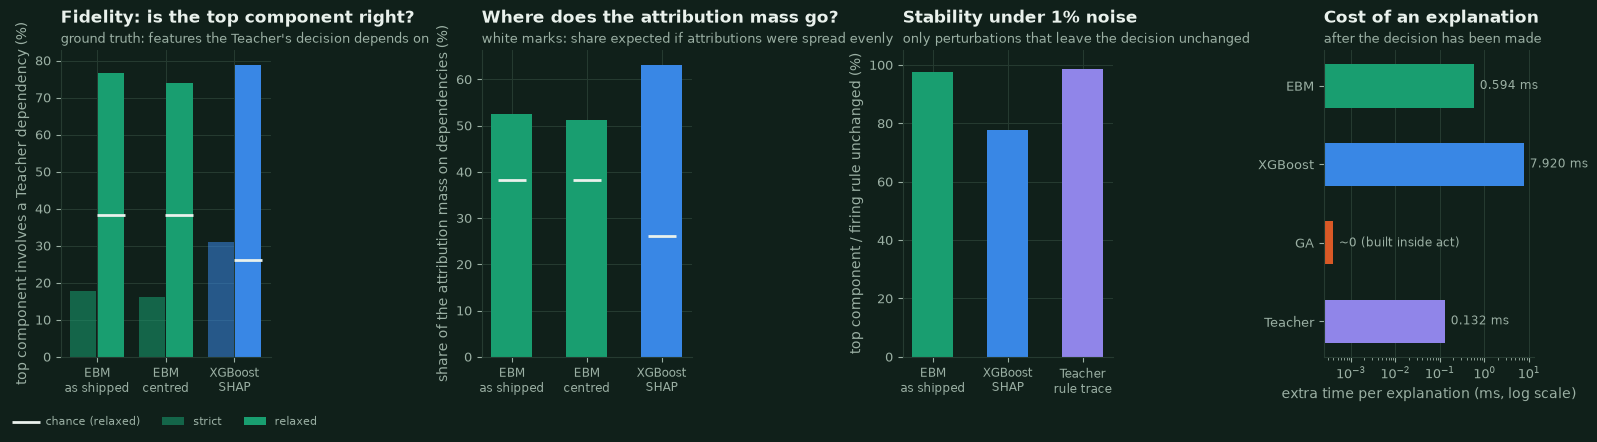

In [57]:
fig, axes = plt.subplots(1, 4, figsize=(16.0, 4.6))
names = list(FIDELITY)
SHORT = {"EBM, terms as shipped": "EBM\nas shipped", "EBM, centred on the average term": "EBM\ncentred", "XGBoost, TreeSHAP": "XGBoost\nSHAP", "Teacher, rule trace": "Teacher\nrule trace"}
colors = [nbp.SERIES[0], nbp.SERIES[0], nbp.SERIES[1]]
ax = axes[0]
x = np.arange(len(names))
ax.bar(x - 0.2, [100 * FIDELITY[n]["top1 strict"] for n in names], width=0.38, color=colors, alpha=0.55, label="strict")
ax.bar(x + 0.2, [100 * FIDELITY[n]["top1 relaxed"] for n in names], width=0.38, color=colors, label="relaxed")
ax.scatter(x + 0.2, [100 * FIDELITY[n]["chance relaxed"] for n in names], marker="_", s=420, color=nbp.TEXT, linewidths=2, zorder=3, label="chance (relaxed)")
ax.set_xticks(x, [SHORT[n] for n in names], fontsize=8.5)
ax.set_ylabel("top component involves a Teacher dependency (%)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncols=3)
nbp.title(ax, "Fidelity: is the top component right?", "ground truth: features the Teacher's decision depends on")
ax = axes[1]
ax.bar(x, [100 * FIDELITY[n]["mass relaxed"] for n in names], width=0.55, color=colors)
ax.scatter(x, [100 * FIDELITY[n]["chance relaxed"] for n in names], marker="_", s=420, color=nbp.TEXT, linewidths=2, zorder=3)
ax.set_xticks(x, [SHORT[n] for n in names], fontsize=8.5)
ax.set_ylabel("share of the attribution mass on dependencies (%)")
nbp.title(ax, "Where does the attribution mass go?", "white marks: share expected if attributions were spread evenly")
ax = axes[2]
stab_names = list(STABILITY)
ax.bar(range(len(stab_names)), [100 * STABILITY[n][0] for n in stab_names], width=0.55, color=[nbp.SERIES[0], nbp.SERIES[1], nbp.SERIES[3]])
ax.set_xticks(range(len(stab_names)), [SHORT[n] for n in stab_names], fontsize=8.5)
ax.set_ylim(0, 105)
ax.set_ylabel("top component / firing rule unchanged (%)")
nbp.title(ax, "Stability under 1% noise", "only perturbations that leave the decision unchanged")
ax = axes[3]
cost_names = list(COST)
ax.barh(range(len(cost_names)), [max(COST[n][1], 1e-4) for n in cost_names], color=[AGENT_COLORS[n] for n in cost_names], height=0.55)
for i, n in enumerate(cost_names):
    ax.annotate(f"{COST[n][1]:.3f} ms" if n != "GA" else "~0 (built inside act)", (max(COST[n][1], 1e-4), i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5, color=nbp.MUTED)
ax.set_yticks(range(len(cost_names)), cost_names)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("extra time per explanation (ms, log scale)")
ax.grid(axis="y", visible=False)
nbp.title(ax, "Cost of an explanation", "after the decision has been made")
fig.tight_layout()
nbp.savefig("nb04_explainability", fig)
plt.show()

In [58]:
f_ebm, f_xgb = FIDELITY["EBM, terms as shipped"], FIDELITY["XGBoost, TreeSHAP"]
display(Markdown(f"""
**Reading the comparison `[fresh]`.**

* **Cost.** An EBM explanation takes {COST['EBM'][1]:.2f} ms and a TreeSHAP explanation {COST['XGBoost'][1]:.1f} ms ({COST['XGBoost'][1] / COST['EBM'][1]:.0f} times more), against a decision time of {COST['EBM'][0]:.2f} and {COST['XGBoost'][0]:.2f} ms. Both are small next to the {1000 * meta['n_workers_used'] / meta['hands_per_second']:.0f} ms a hand takes in the official run, but SHAP
  is the only explanation that costs more than the decision it explains. The rule traces are free: the Teacher's costs {COST['Teacher'][1]:.2f} ms and the GA builds its trace inside `act`.
* **Size.** The EBM's explanation is *complete* but not short: {f_ebm['k80']:.0f} of {len(EBM_TERMS)} terms are needed to cover 80% of the absolute contribution mass (a reader looks at the top few and trusts the rest to be small); SHAP concentrates on {f_xgb['k80']:.0f} of {NUM_FEATURES} features; a rule trace has one rule and
  about {COMPONENTS['Teacher']:.0f} numbers (Teacher) or {COMPONENTS['GA']:.0f} genes (GA).
* **Exactness is not fidelity.** Both learned explanations are exact decompositions of *the model's* score (EBM: the terms add up to the logit, difference to `predict_proba` {ebm_additivity:.0e}; SHAP: the values add up to the margin, difference {shap_additivity:.0e}). Compared with the *Teacher's* ground truth, the highest-ranked
  SHAP feature involves one of the features the Teacher's decision depends on in {pct(f_xgb['top1 strict'])} of the states (chance {pct(f_xgb['chance strict'])}; {pct(f_xgb['top1 relaxed'])} when equivalent features are accepted, chance {pct(f_xgb['chance relaxed'])}; {pct(f_xgb['top3 relaxed'])} for the top three), the highest-ranked EBM term in
  {pct(f_ebm['top1 strict'])} (chance {pct(f_ebm['chance strict'])}; relaxed {pct(f_ebm['top1 relaxed'])}, chance {pct(f_ebm['chance relaxed'])}; top three {pct(f_ebm['top3 relaxed'])}). So the EBM's *own* terms - exact by construction - do not point at the Teacher's dependencies more often than a random term would at the very top of the
  ranking, though they do so more often than chance when the whole mass is considered ({pct(f_ebm['mass relaxed'])} of it against {pct(f_ebm['chance relaxed'])}). Centring the terms on their average ({pct(FIDELITY['EBM, centred on the average term']['top1 relaxed'])} relaxed) does not change that.
  *Speculation:* an additive model spreads the Teacher's threshold rule over many terms and interactions (hence the large number of components), so the top term is rarely "the" rule feature; SHAP, which allocates the margin feature by feature, concentrates it.
* **Stability.** Under noise of 1% of each feature's range (decisions unchanged) the top EBM term stays the same in {pct(STABILITY['EBM, terms as shipped'][0])} of the states, the top SHAP feature in {pct(STABILITY['XGBoost, TreeSHAP'][0])} (rank correlation of the whole attribution {STABILITY['EBM, terms as shipped'][1]:.2f} and {STABILITY['XGBoost, TreeSHAP'][1]:.2f}),
  the Teacher's firing rule in {pct(STABILITY['Teacher, rule trace'][0])}. Correlated features share credit unstably in SHAP; additive terms move continuously with their inputs.
* **An attribution is a statement about the model, not about poker.** Replacing the feature a model ranks first by its value in another state changes that model's decision in {pct(INTERVENTION['EBM']['its top-ranked component'])} (EBM) / {pct(INTERVENTION['XGBoost']['its top-ranked component'])} (XGBoost) of the states, a random feature in
  {pct(INTERVENTION['EBM']['a random feature'])} / {pct(INTERVENTION['XGBoost']['a random feature'])}: the ranking *is* informative about what the model is sensitive to. But replacing a feature the Teacher depends on changes the model's decision in only {pct(INTERVENTION['EBM']['a dependency of the Teacher'])} / {pct(INTERVENTION['XGBoost']['a dependency of the Teacher'])}: what a model is sensitive to
  and what the rule it imitates depends on are different things, and neither is a causal statement about winning chips (section 9: what kind of effect the EBM's edge is was investigated by intervening on what the agents may see of each other, not by reading any explanation of the EBM's own decisions).
"""))
display(md_table(pd.DataFrame(
    [
        ["EBM", "exact and global: the shape functions can be inspected before any decision; contributions add up to the logit; sub-millisecond", "85 components, not sparse; raw contributions are not centred; interactions need two-dimensional plots; top term is a weak pointer to the Teacher's rule"],
        ["XGBoost", "sparse local explanations (a handful of features), standard tooling, high imitation accuracy", "post-hoc; the allocation among correlated features is a choice; top feature moves under tiny noise; the slowest explanation; the model itself is not inspectable"],
        ["Teacher", "the explanation is the computation: every number is the one that decided; stable", "only as good as its rules (a hand-made reference, not a solver); thresholds are cliffs"],
        ["GA", "the explanation is the computation; names its genes; free", "one rule at a time; random bluff coins make a replay of the same observation differ; 18 genes constrain what can be expressed"],
    ],
    columns=["agent", "good at", "bad at"],
)))


**Reading the comparison `[fresh]`.**

* **Cost.** An EBM explanation takes 0.59 ms and a TreeSHAP explanation 7.9 ms (13 times more), against a decision time of 0.69 and 0.77 ms. Both are small next to the 10 ms a hand takes in the official run, but SHAP
  is the only explanation that costs more than the decision it explains. The rule traces are free: the Teacher's costs 0.13 ms and the GA builds its trace inside `act`.
* **Size.** The EBM's explanation is *complete* but not short: 26 of 85 terms are needed to cover 80% of the absolute contribution mass (a reader looks at the top few and trusts the rest to be small); SHAP concentrates on 6 of 45 features; a rule trace has one rule and
  about 5 numbers (Teacher) or 4 genes (GA).
* **Exactness is not fidelity.** Both learned explanations are exact decompositions of *the model's* score (EBM: the terms add up to the logit, difference to `predict_proba` 4e-15; SHAP: the values add up to the margin, difference 1e-05). Compared with the *Teacher's* ground truth, the highest-ranked
  SHAP feature involves one of the features the Teacher's decision depends on in 31% of the states (chance 12%; 79% when equivalent features are accepted, chance 26%; 94% for the top three), the highest-ranked EBM term in
  18% (chance 19%; relaxed 77%, chance 38%; top three 78%). So the EBM's *own* terms - exact by construction - do not point at the Teacher's dependencies more often than a random term would at the very top of the
  ranking, though they do so more often than chance when the whole mass is considered (53% of it against 38%). Centring the terms on their average (74% relaxed) does not change that.
  *Speculation:* an additive model spreads the Teacher's threshold rule over many terms and interactions (hence the large number of components), so the top term is rarely "the" rule feature; SHAP, which allocates the margin feature by feature, concentrates it.
* **Stability.** Under noise of 1% of each feature's range (decisions unchanged) the top EBM term stays the same in 98% of the states, the top SHAP feature in 78% (rank correlation of the whole attribution 0.94 and 0.95),
  the Teacher's firing rule in 99%. Correlated features share credit unstably in SHAP; additive terms move continuously with their inputs.
* **An attribution is a statement about the model, not about poker.** Replacing the feature a model ranks first by its value in another state changes that model's decision in 31% (EBM) / 32% (XGBoost) of the states, a random feature in
  3% / 2%: the ranking *is* informative about what the model is sensitive to. But replacing a feature the Teacher depends on changes the model's decision in only 7% / 8%: what a model is sensitive to
  and what the rule it imitates depends on are different things, and neither is a causal statement about winning chips (section 9: what kind of effect the EBM's edge is was investigated by intervening on what the agents may see of each other, not by reading any explanation of the EBM's own decisions).


| agent | good at | bad at |
|---|---|---|
| EBM | exact and global: the shape functions can be inspected before any decision; contributions add up to the logit; sub-millisecond | 85 components, not sparse; raw contributions are not centred; interactions need two-dimensional plots; top term is a weak pointer to the Teacher's rule |
| XGBoost | sparse local explanations (a handful of features), standard tooling, high imitation accuracy | post-hoc; the allocation among correlated features is a choice; top feature moves under tiny noise; the slowest explanation; the model itself is not inspectable |
| Teacher | the explanation is the computation: every number is the one that decided; stable | only as good as its rules (a hand-made reference, not a solver); thresholds are cliffs |
| GA | the explanation is the computation; names its genes; free | one rule at a time; random bluff coins make a replay of the same observation differ; 18 genes constrain what can be expressed |

## 11. Conclusions and future research

The statements below are generated from the numbers computed above; the markers say how each was obtained.

In [59]:
g_c = GRID["canonical Teacher (sees every statistic)"][2]
g_b = GRID["Teacher blind to aggression only"][2]
ci_e = lambda e, digits=0: ci_text(e.mean, e.ci_low, e.ci_high, digits)  # noqa: E731
over_ga = [MATRIX.loc[a, "GA"] for a in ("Teacher", "XGBoost")]
replicated = lambda a, b: sum(t_estimate(REPLICATION[s, a, b].session, unit="session").ci_low > 0 for s in REPLICATION_SEEDS)  # noqa: E731
BA = BEFORE_AFTER
cal_noisy, cal_ga = list(CALIBRATION.values())
display(Markdown(f"""
### 11.1 Empirical findings (computed in this notebook)

1. **The ranking, and how certain it is `[saved]` `[fresh]`.** Official order: {' > '.join(f'`{a}`' for a in BOARD['agent'])}. Among the strong agents `EBM` beats `Teacher` ({ci_e(OFFICIAL_E['EBM', 'Teacher'])}), `XGBoost` ({ci_e(OFFICIAL_E['EBM', 'XGBoost'])}) and `GA`; `Teacher` and `XGBoost`
   are not separated, and both beat the GA by {min(over_ga):.0f}-{max(over_ga):.0f} BB/100. The EBM's edges over the Teacher and over XGBoost have the **same sign in {sum(e.mean > 0 for k in (('EBM', 'Teacher'), ('EBM', 'XGBoost')) for e in REPL_ESTIMATES[k])} of {2 * len(REPLICATION_SEEDS)} replications on new seeds** (but the replicate interval excludes 0 in only {replicated('EBM', 'Teacher')} and {replicated('EBM', 'XGBoost')} of {len(REPLICATION_SEEDS)}{', and the official estimates are the largest of their three runs' if all(OFFICIAL_E[k].mean > max(e.mean for e in REPL_ESTIMATES[k]) for k in (('EBM', 'Teacher'), ('EBM', 'XGBoost'))) else ''}); the pooled edges are {ci_e(POOLED['EBM', 'Teacher'])} and {ci_e(POOLED['EBM', 'XGBoost'])}; Teacher vs XGBoost stays undecided
   ({ci_e(pooled_sd)}). The leaderboard position of the three leaders is stable in {pct(RANK_P_ALL.loc[ORDER[0], 1])} / {pct(RANK_P_ALL.loc[ORDER[1], 2])} / {pct(RANK_P_ALL.loc[ORDER[2], 3])} of the bootstrap resamples; the GA is fourth in {pct(RANK_P_ALL.loc['GA', 4])} of them.
2. **Bots are unit tests, not scales `[saved]`.** The strong agents beat every bot by at least {min(MATRIX.loc[a, b] for a in STRONG for b in WEAK):.0f} BB/100 (the GA by far less than the others), but the two tiers rank the agents differently and the matchup matrix is not additive (cyclic sums, 4.1).
3. **Sessions are the right unit, and the interval procedure is calibrated `[fresh]`.** With two identical stochastic adaptive agents under the corrected protocol, the session-level 95% interval excluded the true value 0 in {binom_text(cal_noisy['session_fp'], cal_noisy['matches'])} (noisy Teachers) and {binom_text(cal_ga['session_fp'], cal_ga['matches'])} (GAs), the pair-level interval in {binom_text(cal_noisy['pair_fp'], cal_noisy['matches'])} and {binom_text(cal_ga['pair_fp'], cal_ga['matches'])}; in the official run the pairs inside
   the Teacher family have an intraclass correlation of {100 * FAMILY['icc'].min():.2f}-{100 * FAMILY['icc'].max():.2f}% (design effect {FAMILY['ratio'].min() ** 2:.1f}-{FAMILY['ratio'].max() ** 2:.1f}) and the naive interval would have flipped {len(verdict_flips)} verdict(s).
4. **The framework had a first-mover artifact, now fixed `[fresh]`.** Under the legacy single-table duplicate protocol two identical Teachers did not cancel: the first-named one lost {-AA_LEGACY['mean']:.1f} ± {AA_LEGACY['se']:.1f} BB/100 (z = {AA_LEGACY['mean'] / AA_LEGACY['se']:.1f}, {len(AA_LEGACY['sessions'])} sessions). Under the corrected two-table protocol they cancel in every pair (largest |pair sum| {np.max(np.abs(AA_EXACT['pairs'])):.2f} BB). On the same deals the key estimates move
   (legacy -> corrected, BB/100): {'; '.join(f"`{a} vs {b}` {ba['legacy'].mean:+.0f} -> {ba['corrected'].mean:+.0f}" for (a, b), ba in BA.items())}, and the standard error of a match shrinks {min(ba['legacy'].se / ba['corrected'].se for ba in BA.values()):.1f}-{max(ba['legacy'].se / ba['corrected'].se for ba in BA.values()):.1f} times.
5. **Detecting small edges is expensive `[saved]`**: a +{POWER_TARGET_EDGE:.0f} BB/100 edge needs about {((Z_ALPHA + Z_POWER) * power_data['EBM', 'Teacher'][0] / POWER_TARGET_EDGE) ** 2 * OFFICIAL_CFG.session_hands / 1000:,.0f} thousand hands at {pct(POWER_LEVEL)} power; the official run resolves about {min(float(r[f'smallest edge detected with {pct(POWER_LEVEL)} power']) for r in power_rows):.0f}-{max(float(r[f'smallest edge detected with {pct(POWER_LEVEL)} power']) for r in power_rows):.0f} BB/100.
6. **Style `[saved]` `[fresh]`**: EBM, XGBoost and Teacher are nearly the same player (VPIP {pct(STYLE.loc['Teacher', 'vpip'])}, PFR {pct(STYLE.loc['Teacher', 'pfr'])}); the EBM is slightly more aggressive (AF {STYLE.loc['EBM', 'aggression_factor']:.2f} vs {STYLE.loc['Teacher', 'aggression_factor']:.2f}); the GA is tighter (VPIP {pct(STYLE.loc['GA', 'vpip'])}), folds more and loses its chips at showdown against strong opponents.
7. **Why the EBM beats its teacher `[fresh]`**: not luck (pooled edge {ci_e(POOLED['EBM', 'Teacher'])}; the official estimate is the high end of the three runs), not general strength (bots, static game {ci_e(static_ebm)}), not random imperfection, not the protocol. It is an **adaptation effect**: the advantage over an identical Teacher copy appears as soon as one side reads opponent statistics
   ({ci_e(CELL_E['sees', 'blind'])} when only the EBM does, {ci_e(CELL_E['blind', 'sees'])} when only the Teacher does, {ci_e(CELL_E['sees', 'sees'])} when both do) and survives a Teacher that is blind to the aggression statistic ({ci_e(g_b)}), so **no single channel carries it**. The first version of this analysis (legacy protocol) had found the aggression channel to be
   necessary; that conclusion did not survive the corrected protocol (9.6). What does survive is the Teacher's miscalibration: a Teacher blind to aggression beats the canonical one by {fmt('Teacher blind to aggression')} BB/100, which makes "beating the Teacher" a weak statement (section 9).
8. **Explainability `[fresh]`**: SHAP is sparse but slow ({COST['XGBoost'][1]:.1f} ms) and less stable ({pct(STABILITY['XGBoost, TreeSHAP'][0])} unchanged top feature under tiny noise); the EBM's terms are exact, fast ({COST['EBM'][1]:.2f} ms) and stable ({pct(STABILITY['EBM, terms as shipped'][0])}) but spread over many components; rule traces are free and exact but only as good as the rules.
   None of the explanations pointed at the mechanism of section 9.

### 11.2 What the evidence does **not** support

* That the EBM is a stronger *poker player* than the Teacher: it is stronger *against the Teacher* in games in which the agents read opponent statistics; against the bots it is not ({ci_text(gap_bots, gap_bots - 1.96 * gap_se, gap_bots + 1.96 * gap_se)} relative to the Teacher), in a static game it is not ({ci_e(static_ebm)}).
* That the aggression channel *explains* the EBM's edge (it did in the first version of this analysis, under the legacy protocol; it does not under the corrected one).
* That imitation accuracy predicts playing strength: XGBoost agrees with the Teacher {pct(agreement(CONTROL_RUNS['XGBoost']), 1)} of the time and ties it, the EBM agrees {pct(agreement(CONTROL_RUNS['EBM']), 1)} and beats it, a Teacher that merely shrinks its opponent statistics by 10% agrees {pct(agreement(CONTROL_RUNS['Teacher with statistics x0.9']), 1)} and beats it.
* That the GA's loss to the three leaders says anything about evolution in general: one run, one genome, 18 genes.
* That differences of a few BB/100 between adaptive agents have a reliable sign: `Teacher vs XGBoost` is {ci_e(pooled_sd, 1)} after pooling three runs - undecided at the size of the experiment (power, 6.3).
* Anything about exploitability: nobody was tested against a best response.

### 11.3 Assumptions

1. The Teacher's decision is a pure function of the observation, so "what it would have done" is well defined (shadow replays, 9.2).
2. A game in which the opponent statistics are replaced by the neutral prior is a fair stand-in for "an agent that does not adapt".
3. The tiers (weak = Random, CallStation, Maniac) are fixed in advance by the construction of the bots, not by results.
4. Sessions of {OFFICIAL_CFG.session_hands} hands starting from fresh agents are independent; the calibration of 6.2 is consistent with that, and the pair-level analysis shows why hands and pairs are not.
5. Stacks of 100 bb, blinds 5/10, a five-action abstraction, equity against a random hand as the core feature.

### 11.4 Speculation (clearly not tested)

* An additive model that smooths a threshold rule, trained with class weights and DAgger states, ends up slightly more aggressive than its teacher and reacts to the aggression statistic {aggr_ratio:.0%} as often; which of the three causes it is open (9.6).
* The EBM's edge is the footprint of a *damped copy of a costly reaction* of the Teacher (9.6): consistent with the dose-response of the data (XGBoost 100% reaction, no edge; EBM {aggr_ratio:.0%}, edge; a Teacher shrinking its statistics by 10%, edge), but resting on three points.
* The legacy first-mover artifact came from the first play of a deal leaking, through the shared opponent statistics, information about the second play of the same deal. The exact cancellation under two tables is consistent with that story, but the story itself was not tested separately.
* With several EBM training seeds the sign of the edge over the Teacher could vary: it depends on a side effect of imitation.
* The GA's weakness against strong agents comes from the 18-gene cascade's inability to express range-aware calling rather than from the search.

### 11.5 Limitations

* **Heads-up only**, fixed 100 bb, stacks reset every hand, five abstract actions: no stack-depth, tournament or multi-way behaviour is measured.
* **Equity against a random hand** is the core feature of every agent except the bots: nothing here tests range-aware play.
* **A single training run per architecture**: the training variability of the EBM, of XGBoost and of the GA is unknown.
* **Teacher dependence**: EBM and XGBoost are not independent evidence about "machine learning vs evolution".
* **No exploitability / best-response evaluation**: strength is relative to this pool.
* **Limited adaptation**: sessions of {OFFICIAL_CFG.session_hands} hands from neutral statistics; longer sessions would let the statistic-driven agents diverge further.
* **Multiple comparisons** across 21 pairings and {len(CONTROL_RUNS)} controlled experiments: the headline verdicts survive a Bonferroni correction ({len(survivors)} of {len(p_values)} pairings do), single rows of the controlled experiments ({CONTROL_SESSIONS} sessions each) are hints.
* **Notebook-level tooling** (`SeesLess`, shadow and logging wrappers) is not part of the package; the conclusions about it are conclusions about those wrappers.

### 11.6 Future research

* **Outcome-based learning beyond imitation**: reinforcement learning (self-play) and counterfactual-regret methods, with the Teacher only as an opponent - the EBM/XGBoost results show that imitation inherits the Teacher's miscalibrations (here, its aggression slope).
* **LLM agents via Ollama** and **specialised "System One" models** under the same `Agent` interface and the same tournament, with the same session-level statistics and the two-table protocol.
* **3-6 player tables**: the engine is heads-up; position effects, multi-way pots and explanation methods under several opponents are untouched.
* **Variance reduction**: AIVAT-style estimators or control variates for the strong tier, so that +10 BB/100 differences are resolved with tens instead of hundreds of thousands of hands (the two-table protocol already removed part of the shared variance, 6.5).
* **Exploitability**: a best-response trainer against each agent's frozen policy, and "exploit-the-adapter" tests such as the aggression-statistic attack found here.
* **Retrain and re-evaluate the GA under the corrected protocol**: its fitness was computed with the legacy single-table duplicate protocol, so the genome in this tournament was selected under an artifact; the GA's results here describe that genome, not what the same search would find under two tables.
* **Re-calibrating the framework**: a neutral point for the Teacher's aggression statistic that matches what competent opponents show (see 9.6), and a re-run of the saved validation numbers in the training metadata of the EBM and XGBoost under the corrected protocol.
* **Several training seeds per architecture**, with the controlled experiments of section 9 repeated for each.
"""))


### 11.1 Empirical findings (computed in this notebook)

1. **The ranking, and how certain it is `[saved]` `[fresh]`.** Official order: `EBM` > `Teacher` > `XGBoost` > `GA` > `Random` > `CallStation` > `Maniac`. Among the strong agents `EBM` beats `Teacher` (+37 [+27, +47]), `XGBoost` (+29 [+20, +38]) and `GA`; `Teacher` and `XGBoost`
   are not separated, and both beat the GA by 75-83 BB/100. The EBM's edges over the Teacher and over XGBoost have the **same sign in 4 of 4 replications on new seeds** (but the replicate interval excludes 0 in only 1 and 1 of 2, and the official estimates are the largest of their three runs); the pooled edges are +28 [+21, +34] and +23 [+16, +29]; Teacher vs XGBoost stays undecided
   (-2 [-6, +1]). The leaderboard position of the three leaders is stable in 99% / 86% / 87% of the bootstrap resamples; the GA is fourth in 100% of them.
2. **Bots are unit tests, not scales `[saved]`.** The strong agents beat every bot by at least 190 BB/100 (the GA by far less than the others), but the two tiers rank the agents differently and the matchup matrix is not additive (cyclic sums, 4.1).
3. **Sessions are the right unit, and the interval procedure is calibrated `[fresh]`.** With two identical stochastic adaptive agents under the corrected protocol, the session-level 95% interval excluded the true value 0 in 1 of 40 (exact 95% range 0%-13%) (noisy Teachers) and 1 of 40 (exact 95% range 0%-13%) (GAs), the pair-level interval in 1 of 40 (exact 95% range 0%-13%) and 0 of 40 (exact 95% range 0%-9%); in the official run the pairs inside
   the Teacher family have an intraclass correlation of 0.34-0.69% (design effect 1.3-1.7) and the naive interval would have flipped 0 verdict(s).
4. **The framework had a first-mover artifact, now fixed `[fresh]`.** Under the legacy single-table duplicate protocol two identical Teachers did not cancel: the first-named one lost 13.2 ± 3.0 BB/100 (z = -4.3, 1200 sessions). Under the corrected two-table protocol they cancel in every pair (largest |pair sum| 0.00 BB). On the same deals the key estimates move
   (legacy -> corrected, BB/100): `EBM vs Teacher` +69 -> +38; `EBM vs XGBoost` +40 -> +31; `Teacher vs XGBoost` -6 -> -4, and the standard error of a match shrinks 1.6-2.8 times.
5. **Detecting small edges is expensive `[saved]`**: a +10 BB/100 edge needs about 82 thousand hands at 80% power; the official run resolves about 7-14 BB/100.
6. **Style `[saved]` `[fresh]`**: EBM, XGBoost and Teacher are nearly the same player (VPIP 82%, PFR 51%); the EBM is slightly more aggressive (AF 1.66 vs 1.56); the GA is tighter (VPIP 69%), folds more and loses its chips at showdown against strong opponents.
7. **Why the EBM beats its teacher `[fresh]`**: not luck (pooled edge +28 [+21, +34]; the official estimate is the high end of the three runs), not general strength (bots, static game +3 [-2, +7]), not random imperfection, not the protocol. It is an **adaptation effect**: the advantage over an identical Teacher copy appears as soon as one side reads opponent statistics
   (+18 [+7, +29] when only the EBM does, +28 [+12, +44] when only the Teacher does, +28 [+4, +51] when both do) and survives a Teacher that is blind to the aggression statistic (+20 [+10, +30]), so **no single channel carries it**. The first version of this analysis (legacy protocol) had found the aggression channel to be
   necessary; that conclusion did not survive the corrected protocol (9.6). What does survive is the Teacher's miscalibration: a Teacher blind to aggression beats the canonical one by +128 [+96, +160] BB/100, which makes "beating the Teacher" a weak statement (section 9).
8. **Explainability `[fresh]`**: SHAP is sparse but slow (7.9 ms) and less stable (78% unchanged top feature under tiny noise); the EBM's terms are exact, fast (0.59 ms) and stable (98%) but spread over many components; rule traces are free and exact but only as good as the rules.
   None of the explanations pointed at the mechanism of section 9.

### 11.2 What the evidence does **not** support

* That the EBM is a stronger *poker player* than the Teacher: it is stronger *against the Teacher* in games in which the agents read opponent statistics; against the bots it is not (-3 [-30, +23] relative to the Teacher), in a static game it is not (+3 [-2, +7]).
* That the aggression channel *explains* the EBM's edge (it did in the first version of this analysis, under the legacy protocol; it does not under the corrected one).
* That imitation accuracy predicts playing strength: XGBoost agrees with the Teacher 99.7% of the time and ties it, the EBM agrees 96.8% and beats it, a Teacher that merely shrinks its opponent statistics by 10% agrees 99.1% and beats it.
* That the GA's loss to the three leaders says anything about evolution in general: one run, one genome, 18 genes.
* That differences of a few BB/100 between adaptive agents have a reliable sign: `Teacher vs XGBoost` is -2.2 [-5.5, +1.2] after pooling three runs - undecided at the size of the experiment (power, 6.3).
* Anything about exploitability: nobody was tested against a best response.

### 11.3 Assumptions

1. The Teacher's decision is a pure function of the observation, so "what it would have done" is well defined (shadow replays, 9.2).
2. A game in which the opponent statistics are replaced by the neutral prior is a fair stand-in for "an agent that does not adapt".
3. The tiers (weak = Random, CallStation, Maniac) are fixed in advance by the construction of the bots, not by results.
4. Sessions of 200 hands starting from fresh agents are independent; the calibration of 6.2 is consistent with that, and the pair-level analysis shows why hands and pairs are not.
5. Stacks of 100 bb, blinds 5/10, a five-action abstraction, equity against a random hand as the core feature.

### 11.4 Speculation (clearly not tested)

* An additive model that smooths a threshold rule, trained with class weights and DAgger states, ends up slightly more aggressive than its teacher and reacts to the aggression statistic 88% as often; which of the three causes it is open (9.6).
* The EBM's edge is the footprint of a *damped copy of a costly reaction* of the Teacher (9.6): consistent with the dose-response of the data (XGBoost 100% reaction, no edge; EBM 88%, edge; a Teacher shrinking its statistics by 10%, edge), but resting on three points.
* The legacy first-mover artifact came from the first play of a deal leaking, through the shared opponent statistics, information about the second play of the same deal. The exact cancellation under two tables is consistent with that story, but the story itself was not tested separately.
* With several EBM training seeds the sign of the edge over the Teacher could vary: it depends on a side effect of imitation.
* The GA's weakness against strong agents comes from the 18-gene cascade's inability to express range-aware calling rather than from the search.

### 11.5 Limitations

* **Heads-up only**, fixed 100 bb, stacks reset every hand, five abstract actions: no stack-depth, tournament or multi-way behaviour is measured.
* **Equity against a random hand** is the core feature of every agent except the bots: nothing here tests range-aware play.
* **A single training run per architecture**: the training variability of the EBM, of XGBoost and of the GA is unknown.
* **Teacher dependence**: EBM and XGBoost are not independent evidence about "machine learning vs evolution".
* **No exploitability / best-response evaluation**: strength is relative to this pool.
* **Limited adaptation**: sessions of 200 hands from neutral statistics; longer sessions would let the statistic-driven agents diverge further.
* **Multiple comparisons** across 21 pairings and 26 controlled experiments: the headline verdicts survive a Bonferroni correction (18 of 21 pairings do), single rows of the controlled experiments (50 sessions each) are hints.
* **Notebook-level tooling** (`SeesLess`, shadow and logging wrappers) is not part of the package; the conclusions about it are conclusions about those wrappers.

### 11.6 Future research

* **Outcome-based learning beyond imitation**: reinforcement learning (self-play) and counterfactual-regret methods, with the Teacher only as an opponent - the EBM/XGBoost results show that imitation inherits the Teacher's miscalibrations (here, its aggression slope).
* **LLM agents via Ollama** and **specialised "System One" models** under the same `Agent` interface and the same tournament, with the same session-level statistics and the two-table protocol.
* **3-6 player tables**: the engine is heads-up; position effects, multi-way pots and explanation methods under several opponents are untouched.
* **Variance reduction**: AIVAT-style estimators or control variates for the strong tier, so that +10 BB/100 differences are resolved with tens instead of hundreds of thousands of hands (the two-table protocol already removed part of the shared variance, 6.5).
* **Exploitability**: a best-response trainer against each agent's frozen policy, and "exploit-the-adapter" tests such as the aggression-statistic attack found here.
* **Retrain and re-evaluate the GA under the corrected protocol**: its fitness was computed with the legacy single-table duplicate protocol, so the genome in this tournament was selected under an artifact; the GA's results here describe that genome, not what the same search would find under two tables.
* **Re-calibrating the framework**: a neutral point for the Teacher's aggression statistic that matches what competent opponents show (see 9.6), and a re-run of the saved validation numbers in the training metadata of the EBM and XGBoost under the corrected protocol.
* **Several training seeds per architecture**, with the controlled experiments of section 9 repeated for each.


In [60]:
runtime = time.perf_counter() - NOTEBOOK_STARTED
figure_files = sorted((ARTIFACTS_DIR / "figures").glob("nb04_*.png"))
display(Markdown(
    f"Notebook run time: **{runtime / 60:.1f} min** on {N_WORKERS} worker processes. Figures written to `artifacts/figures/` ({len(figure_files)} files, {sum(f.stat().st_size for f in figure_files) / 1e6:.1f} MB): " + ", ".join(f"`{f.name}`" for f in figure_files) + "."
))

Notebook run time: **11.6 min** on 8 worker processes. Figures written to `artifacts/figures/` (17 files, 2.4 MB): `nb04_controls.png`, `nb04_cumulative_profit.png`, `nb04_decision_explanations.png`, `nb04_ebm_vs_teacher_deviations.png`, `nb04_ebm_vs_teacher_mechanism.png`, `nb04_explainability.png`, `nb04_head_to_head.png`, `nb04_latency.png`, `nb04_leaderboard.png`, `nb04_matchup_matrix.png`, `nb04_pair_vs_session.png`, `nb04_power.png`, `nb04_rank_stability.png`, `nb04_replication.png`, `nb04_style_radar.png`, `nb04_style_streets.png`, `nb04_vs_baselines.png`.